# Persona 3 — Entidades y relaciones del corpus Glaciares (v2.2 · lista para el grafo)
**Proyecto:** Enterprise Brain — Gestión del Conocimiento con Knowledge Graph + GraphRAG · Grupo G8

**Entrada:** `texto_glaciares/chunks.jsonl` y `tables.jsonl` (Persona 2) · `corpus_glaciares/papers.csv` y `metadata_triples.csv` (Persona 1)
**Salida:** `tripletas_glaciares_v22/` → base de la ontología y del grafo (Neo4j)

### v2.2 (revisión con los datos reales de la v2.1)
- Riesgo: una laguna entra si **algún** documento la cita con el nivel pedido (Palcacocha y Cuchillacocha vuelven a P2).
- Departamento: manda el que dice el texto; ya no se cuentan lagunas de Áncash en Arequipa o Pasco.
- Poblados "aguas abajo": solo por subcuencas pequeñas (no por todo el río Santa o Marañón) y sin nevados tomados como poblados (Alpamayo, Quitaraju).
- P9: se quitan superficies atípicas (la de un glaciar o una subcuenca leída como si fuera de toda la cordillera).
- "1800 personas" ya no se toma como el año 1800.
- Tablas de **validación o muestreo** por cordillera (p. ej. "Puntos de validación": Glaciar / No glaciar) ya no se leen como inventario.
- Pregunta libre: no confunde palabras comunes ("aguas", "riesgo") con entidades.
- **Hechos verificados (sección 11b):** datos del INGLOG 2023 copiados a mano con su página (P1 y P9).

### Qué cambió en la v2.1 (respecto de la v2)
| Arreglo | Para qué pregunta |
|---|---|
| **Riesgo desde tablas** (columnas *Riesgo / Peligro / Categoría*) y listas largas ("las lagunas con riesgo muy alto son …") | P2, P3, P5, P6, P7, P10 |
| **"En Huánuco, las lagunas …"** → cada laguna queda en ese departamento (evita que Quesillococha salga en Áncash) | P2 |
| **Entidad Inventario** (cordillera + año → nº de glaciares, nº de lagunas, superficie) desde texto y tablas | P1, P9 |
| **Centro poblado → subcuenca / distrito**, y columnas *Poblados expuestos*, *Obras*, *Estado* en tablas | P3, P10 |
| Verbos falsos de spaCy ("glaciar", "andir") fuera, también los del caché | calidad |
| **Capa de respuestas:** las 10 preguntas con evidencia + banco de 20 preguntas difíciles + pregunta libre | todas e imprevistas |

### Técnicas combinadas (cada una tapa los huecos de la otra)
| # | Técnica | Qué aporta | Ejemplo |
|---|---|---|---|
| 1 | **Reglas del dominio** | Lagunas, glaciares, bofedales, fenómenos, especies, servicios, obras y su estado, eventos, mediciones | "laguna Palcacocha … riesgo muy alto" |
| 2 | **Tablas de inventarios** | Valores limpios (área, volumen, altitud) y ubicación | Fila: Palcacocha · 0,51 km² · 17,4 hm³ |
| 3 | **GLiNER** | Nombres que las reglas no ven + bofedales y especies | "Ichiccollcococha" (bofedal) |
| 4 | **Diccionario del corpus** | Reconoce nombres sueltos ya vistos en ≥2 documentos | "Palcacocha creció…" sin la palabra laguna |
| 5 | **spaCy** (gramática) | Sujeto → verbo → objeto: relaciones no previstas | "Pastoruri **atrae** turistas" |
| 6 | **LLM** (Gemini → Groq) | Relaciones ricas en una muestra, con evidencia verificada | — |
| + | Unificar nombres · unidades · sentido común · **votación** | Datos limpios y con confianza | Palcaccocha = Palcacocha; m² → km² |

### Cómo ejecutarlo
1. Colab con **GPU T4** (para GLiNER). 🔑 Secrets opcionales: `GEMINI_API_KEY`, `GROQ_API_KEY`.
2. *Entorno de ejecución → Ejecutar todas*. Reutiliza los cachés de la v2.1 (GLiNER, spaCy y LLM): **no repite** las llamadas a Gemini/Groq. Tiempo aprox.: 10–15 min.
3. Todo es reanudable: si se corta, se vuelve a ejecutar y continúa.

## 0. Carpetas

In [1]:
BASE_LOCAL = r"G:\Mi unidad\proyecto_gc"

import os, sys
try:
    import google.colab  # noqa: F401
    EN_COLAB = True
except ImportError:
    EN_COLAB = False
if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/proyecto_gc"
else:
    BASE = BASE_LOCAL
CARPETA_CORPUS = os.path.join(BASE, "corpus_glaciares")
CARPETA_TEXTO  = os.path.join(BASE, "texto_glaciares")
CARPETA_V1     = os.path.join(BASE, "tripletas_glaciares_v21")  # cachés de la v2.1 (GLiNER, spaCy y LLM)
CARPETA_TRIP   = os.path.join(BASE, "tripletas_glaciares_v22")  # salida de esta versión (v2 y v2.1 quedan intactas)
os.makedirs(CARPETA_TRIP, exist_ok=True)
print("Entrada:", CARPETA_TEXTO, "\nSalida: ", CARPETA_TRIP)

Mounted at /content/drive
Entrada: /content/drive/MyDrive/proyecto_gc/texto_glaciares 
Salida:  /content/drive/MyDrive/proyecto_gc/tripletas_glaciares_v22


## 1. Claves de LLM (opcionales)
Gemini es el principal; Groq es el respaldo gratuito si Gemini está saturado. Sin claves, se omite esa capa.

In [2]:
def leer_secreto(nombre):
    try:
        from google.colab import userdata
        v = userdata.get(nombre)
        if v:
            print(f"{nombre}: cargada desde Secrets")
            return v
    except Exception:
        pass
    if os.environ.get(nombre):
        print(f"{nombre}: cargada desde variable de entorno")
        return os.environ[nombre]
    print(f"{nombre}: no configurada (se omite)")
    return None

GEMINI_API_KEY = leer_secreto("GEMINI_API_KEY")
GROQ_API_KEY = leer_secreto("GROQ_API_KEY")

GEMINI_API_KEY: cargada desde Secrets
GROQ_API_KEY: cargada desde Secrets


## 2. Configuración ✏️

In [3]:
CONFIG = {
    "USAR_TABLAS": True,
    "USAR_GLINER": True,
    "GLINER_MODELO": "urchade/gliner_multi-v2.1",
    "GLINER_UMBRAL": 0.5,
    "GLINER_PRIORIDAD_MIN": 2,
    "GLINER_MAX_SIN_GPU": 1500,
    "USAR_DICCIONARIO": True,
    "DICC_MIN_DOCS": 2,              # un nombre entra al diccionario si aparece en ≥2 documentos
    "USAR_SPACY": True,
    "SPACY_MODELO": "es_core_news_md",
    "USAR_LLM": True,
    "LLM_MODELOS": ["gemini-flash-latest"],
    "LLM_N_FRAGMENTOS": 60,
    "LLM_PAUSA_S": 6,
    "GROQ_PAUSA_S": 8,               # Groq gratis limita tokens por minuto: con 8 s casi no hay esperas
    "UMBRAL_UNIFICAR": 93,           # 0-100: parecido mínimo para unir variantes de un nombre
    "DOC_DEMO": "20.500.12748/394",
    "ENTIDAD_DEMO": "Palcacocha",
}

## 3. Código
Solo se ejecuta.

In [4]:
%pip install -q gliner google-genai networkx spacy rapidfuzz tabulate

# -*- coding: utf-8 -*-
"""
Persona 3 — Entidades y relaciones (tripletas) desde el texto del corpus Glaciares
Proyecto: Enterprise Brain — Gestión del Conocimiento (Knowledge Graph + GraphRAG)

Entrada (Persona 2): texto_glaciares/chunks.jsonl (fragmentos con procedencia)
Varias técnicas combinadas, todas con evidencia (documento, páginas, oración o fila de tabla):
  1. Reglas y diccionarios del dominio (todo el corpus)
  2. Tablas de inventarios (valores limpios: área, volumen, altitud, ubicación)
  3. Diccionario de nombres construido con el propio corpus (encuentra "Palcacocha" sin la palabra "laguna")
  4. GLiNER multilingüe (nombres que las reglas no ven)
  5. spaCy: análisis gramatical sujeto → verbo → objeto (relaciones inesperadas)
  6. LLM (Gemini; Groq de respaldo) sobre una muestra, validado contra el texto
  + unificación de nombres, unidades normalizadas, reglas de sentido común y votación entre métodos
Salidas: entidades.csv, menciones.csv, tripletas_contenido.csv, tripletas_consolidadas.csv,
         tripletas_todas.csv (metadatos de la Persona 1 + contenido), reporte_pln.md
"""
import os, re, json, time, unicodedata
from collections import Counter, defaultdict
from datetime import datetime, timezone

import pandas as pd

VERSION = "2.2-glaciares"


def ahora():
    return datetime.now(timezone.utc).isoformat(timespec="seconds")


def sin_tildes(t):
    return "".join(c for c in unicodedata.normalize("NFD", t or "") if unicodedata.category(c) != "Mn")


def norm(t):
    return re.sub(r"\s+", " ", sin_tildes((t or "").lower())).strip()


def leer_jsonl(ruta):
    import gzip
    abrir = gzip.open if ruta.endswith(".gz") else open
    with abrir(ruta, "rt", encoding="utf-8") as fh:
        return [json.loads(l) for l in fh if l.strip()]


# ======================================================================
# 1. Ontología de trabajo (tipos y predicados)
# ======================================================================
TIPOS = ["Laguna", "Glaciar", "Nevado", "Cordillera", "Cuenca", "Rio", "Quebrada", "Departamento", "Provincia",
         "Distrito", "CentroPoblado", "Evento", "Institucion", "MetodoMonitoreo", "ObraSeguridad",
         "Ecosistema", "Bofedal", "Fenomeno", "Especie", "ServicioEcosistemico", "Inventario"]

PREDICADOS = {
    "ubicadaEn": "lugar donde está una laguna, glaciar, nevado, cuenca, provincia o distrito",
    "alimentadaPor": "laguna alimentada por (o al pie de) un glaciar o nevado",
    "tieneNivelRiesgo": "nivel de riesgo o peligro de una laguna (Muy alto, Alto, Medio, Bajo)",
    "amenazaA": "laguna o glaciar que pone en peligro a un centro poblado aguas abajo",
    "ocurrioEn": "evento (aluvión, desborde, avalancha) ocurrido en una laguna o glaciar",
    "afectoA": "evento que afectó a un centro poblado",
    "ocurrioEnAnio": "año del evento",
    "tieneObraSeguridad": "obra de seguridad de una laguna (dique, túnel, sifón, canal de desagüe, sistema de alerta temprana)",
    "monitoreadoCon": "método con que se monitorea una laguna o glaciar",
    "intervieneEn": "institución que monitorea, evalúa o ejecuta obras en una laguna o glaciar",
    "tieneVolumen": "volumen de agua de una laguna (valor y unidad)",
    "tieneArea": "área o espejo de agua (valor y unidad)",
    "tieneAltitud": "altitud (m s.n.m.)",
    "tieneProfundidadMax": "profundidad máxima (m)",
    "tieneSuperficieGlaciar": "superficie glaciar de una cordillera (valor, unidad y año)",
    "estadoObra": "estado de una obra de seguridad de la laguna (p. ej. 'Dique: Requiere mantenimiento')",
    "formadaEnAnio": "año en que se formó o apareció una laguna",
    "causoVictimas": "número de víctimas (fallecidos) de un evento",
    "tienePoblacion": "número de habitantes de un centro poblado",
    "tieneEcosistema": "ecosistema presente en un lugar (bofedal, pajonal, bosque de Polylepis, humedal altoandino)",
    "presentaFenomeno": "fenómeno que ocurre en un lugar (retroceso glaciar, drenaje ácido de roca, contaminación por metales…)",
    "albergaEspecie": "especie de flora o fauna presente en un ecosistema o lugar",
    "proveeServicio": "servicio ecosistémico que brinda un ecosistema, glaciar o laguna (regulación hídrica, agua para consumo…)",
    "abasteceA": "laguna, río o glaciar que abastece de agua a un centro poblado o distrito",
    "drenaHacia": "laguna o río que desagua hacia un río, quebrada u otra laguna",
    # v2.1 — inventarios (una ficha por cordillera y año: cuántos glaciares, lagunas y cuánta superficie)
    "inventarioDe": "inventario que describe una cordillera (o el país)",
    "anioInventario": "año de referencia del inventario",
    "registraGlaciares": "número de glaciares que registra el inventario",
    "registraLagunas": "número de lagunas (de origen glaciar) que registra el inventario",
    "registraLagunasNuevas": "número de lagunas nuevas formadas (por la pérdida de glaciares) según el inventario",
    "registraSuperficieGlaciar": "superficie glaciar que registra el inventario (km²)",
    "relacionadoCon": "relación abierta encontrada por el análisis gramatical (el verbo va en la columna 'verb')",
}

# ======================================================================
# 2. Diccionarios del dominio
# ======================================================================
CORDILLERAS = ["Blanca", "Negra", "Huallanca", "Huayhuash", "Raura", "Huagoruncho", "La Viuda", "Central",
               "Huaytapallana", "Chonta", "Ampato", "Urubamba", "Vilcabamba", "Huanzo", "Chila", "La Raya",
               "Vilcanota", "Carabaya", "Apolobamba", "Volcánica", "Barroso", "Real"]
DEPARTAMENTOS = ["Áncash", "Ancash", "Junín", "Cusco", "Cuzco", "Puno", "Huánuco", "Apurímac", "Huancavelica",
                 "Arequipa", "Ayacucho", "Pasco", "Cajamarca", "Moquegua", "Tacna", "Lima", "La Libertad", "Piura",
                 "Amazonas", "San Martín", "Ica", "Lambayeque", "Tumbes", "Loreto", "Ucayali", "Madre de Dios"]
DEP_CANON = {"ancash": "Áncash", "cuzco": "Cusco"}
DEPARTAMENTOS_SUELTOS = ["Áncash", "Ancash", "Junín", "Huánuco", "Apurímac", "Huancavelica", "Ayacucho", "Cajamarca",
                         "Moquegua", "Tacna", "Puno"]
POBLADOS_CONOCIDOS = ["Huaraz", "Carhuaz", "Yungay", "Caraz", "Recuay", "Huari", "Chavín", "Ranrahirca", "Mancos",
                      "Marcará", "Pomabamba", "Piscobamba", "Chacas", "Huallanca", "Ocongate", "Marcapata", "Macusani",
                      "Cabanaconde", "Chivay", "Urubamba", "Ollantaytambo", "Santa Teresa", "Quillabamba", "Huancayo",
                      "Paccha", "Llupa", "Pitec", "Cashapampa", "Tarica", "Aija", "Ticapampa", "Catac", "Cátac",
                      "Jangas", "Taricá", "Shilla", "Ataquero", "Musho", "Matacoto"]
INSTITUCIONES = {
    "INAIGEM": r"INAIGEM|Instituto Nacional de Investigaci[oó]n en Glaciares",
    "ANA": r"\bANA\b|Autoridad Nacional del Agua",
    "SENAMHI": r"SENAMHI|Servicio Nacional de Meteorolog[ií]a",
    "INDECI": r"INDECI|Instituto Nacional de Defensa Civil",
    "CENEPRED": r"CENEPRED",
    "INGEMMET": r"INGEMMET",
    "IGP": r"\bIGP\b|Instituto Geof[ií]sico del Per[uú]",
    "Electroperú": r"Electroper[uú]|ELECTROPER[UÚ]",
    "Hidrandina": r"Hidrandina|HIDRANDINA",
    "INRENA": r"INRENA",
    "Unidad de Glaciología": r"Unidad de Glaciolog[ií]a|UGRH",
    "Corporación Peruana del Santa": r"Corporaci[oó]n Peruana del Santa",
    "Comisión de Control de Lagunas": r"Comisi[oó]n de Control de Lagunas",
    "Gobierno Regional de Áncash": r"Gobierno Regional de [ÁA]ncash",
    "Municipalidad Provincial de Huaraz": r"Municipalidad Provincial de Huaraz",
}
METODOS = {
    "Batimetría": r"batim[eé]tr\w*|ecosonda",
    "Fotogrametría": r"fotogram[eé]tr\w*",
    "Dron (UAV)": r"\bdron(es)?\b|\bdrones\b|\bUAV\b|\bRPAS\b|veh[ií]culo a[eé]reo no tripulado",
    "Imágenes Landsat": r"\bLandsat\b",
    "Imágenes Sentinel": r"\bSentinel(-?\d\w?)?\b",
    "Teledetección": r"teledetecci[oó]n|sensores remotos|percepci[oó]n remota|im[aá]genes satelitales",
    "Georradar (GPR)": r"georradar|\bGPR\b|radar de penetraci[oó]n",
    "LiDAR": r"\bLiDAR\b",
    "GNSS / GPS diferencial": r"\bGNSS\b|GPS diferencial|\bDGPS\b",
    "Estación meteorológica": r"estaci[oó]n(es)? meteorol[oó]gica",
    "Limnígrafo / limnímetro": r"limn[ií]grafo|limn[ií]metro|sensor de nivel",
    "Balance de masa": r"balance de masa|mass balance",
    "Estacas de ablación": r"estacas? de ablaci[oó]n|ablation stakes",
    "InSAR / DInSAR": r"\bD?InSAR\b|interferometr\w*",
    "Modelamiento de flujo (HEC-RAS / FLO-2D / RAMMS)": r"HEC-?RAS|FLO-?2D|RAMMS|modelamiento hidr[aá]ulico|modelaci[oó]n num[eé]rica",
    "Cámaras de monitoreo": r"c[aá]maras? de (video)?vigilancia|c[aá]maras? de monitoreo|c[aá]mara time-?lapse",
}
OBRAS = {
    "Dique": r"\bdiques?\b|\bmuro de contenci[oó]n",
    "Túnel de desagüe": r"\bt[uú]nel(es)?\b",
    "Canal de desagüe": r"canal(es)? de (desag[uü]e|descarga|derivaci[oó]n|evacuaci[oó]n)",
    "Sifón": r"\bsif[oó]n(es)?\b",
    "Aliviadero": r"aliviadero",
    "Presa": r"\bpresa\b|\brepresa\b",
    "Sistema de alerta temprana": r"sistema de alerta temprana|\bSAT\b",
    "Obras de seguridad": r"obras? de seguridad",
}
ECOSISTEMAS = {
    "Bofedal": r"\bbofedal(es)?\b|\bwetlands? \(bofedal",
    "Pajonal altoandino": r"\bpajonal(es)?\b",
    "Bosque de Polylepis (queñual)": r"bosques? de (polylepis|que[ñn]u[ae]l(es)?|queu[ñn]a(s)?)|\bque[ñn]uales\b|\bqueu[ñn]ales\b|polylepis forests?",
    "Humedal altoandino": r"humedal(es)?( alto ?andinos?)?|\bpeatlands?\b|turberas?",
    "Puna": r"\bpuna\b",
}
FENOMENOS = {
    "Retroceso glaciar": r"retroceso (glaciar|del glaciar|de los glaciares)|p[eé]rdida de (superficie|cobertura|masa) glaciar|"
                         r"deglaciaci[oó]n|desglaciaci[oó]n|reducci[oó]n (de la )?(superficie|cobertura) glaciar|glacier retreat|glacier (mass )?loss",
    "Drenaje ácido de roca": r"drenaje [aá]cido( de roca)?|\bDAR\b|acid rock drainage|\bARD\b",
    "Contaminación por metales": r"metales pesados|contaminaci[oó]n (por|con) metales|trace[- ]metal|heavy metals",
    "Cambio climático": r"cambio clim[aá]tico|calentamiento global|climate change",
    "Escasez hídrica": r"escasez (h[ií]drica|de agua)|estr[eé]s h[ií]drico|d[eé]ficit h[ií]drico|water scarcity",
    "Aumento de temperatura": r"(aumento|incremento) de (la )?temperatura|warming",
    "Sequía": r"\bsequ[ií]as?\b|\bdrought",
    "Formación de nuevas lagunas": r"(formaci[oó]n|aparici[oó]n) de (nuevas )?lagunas|nuevas lagunas|new (glacial )?lakes",
}
ESPECIES = {
    "Polylepis (queñual)": r"\bPolylepis\b|\bque[ñn]ual\b|\bqueu[ñn]a\b",
    "Distichia muscoides": r"Distichia",
    "Plantago rigida": r"Plantago rigida",
    "Oxychloe andina": r"Oxychloe",
    "Puya raimondii": r"Puya raimondii|Puya Raimondi",
    "Ichu (Jarava ichu)": r"\bichu\b|Jarava ichu|Stipa ichu",
    "Vicuña": r"\bvicu[ñn]as?\b",
    "Alpaca": r"\balpacas?\b",
    "Llama": r"\bllamas\b",
    "Taruca": r"\btarucas?\b",
    "Cóndor andino": r"c[oó]ndor",
    "Vizcacha": r"\bvizcachas?\b",
    "Huallata (ganso andino)": r"huallata|Chloephaga",
    "Trucha": r"\btruchas?\b|Oncorhynchus",
    "Rana andina (Telmatobius)": r"Telmatobius",
}
SERVICIOS = {
    "Regulación hídrica": r"regulaci[oó]n (h[ií]drica|del agua|hidrol[oó]gica)|water regulation",
    "Provisión de agua": r"provisi[oó]n (de|del) agua|abastecimiento (de|del) agua|suministro de agua|water supply|fuente de agua",
    "Agua para consumo humano": r"consumo humano|agua potable",
    "Agua para riego": r"\briego\b|irrigaci[oó]n",
    "Generación hidroeléctrica": r"hidroel[eé]ctric\w*|hydropower",
    "Almacenamiento de carbono": r"(almacenamiento|captura|secuestro|reserva) de carbono|carbon (storage|stock|sequestration)",
    "Forraje y pastoreo": r"\bforraje\b|\bpastoreo\b|grazing",
    "Turismo": r"\bturis\w+|tourism",
    "Hábitat y biodiversidad": r"h[aá]bitat|biodiversidad|biodiversity",
}
ESTADOS_OBRA = [
    ("Colapsada", r"colaps\w+|destruid[ao]s?"),
    ("Deteriorada", r"deteriorad[ao]s?|en mal estado|mal estado|da[ñn]ad[ao]s?|fisurad[ao]s?|agrietad[ao]s?|erosionad[ao]s?|obstruid[ao]s?|colmatad[ao]s?"),
    ("Requiere mantenimiento", r"requiere[n]? (de )?mantenimiento|necesita[n]? mantenimiento|falta de mantenimiento|sin mantenimiento"),
    ("Inoperativa", r"inoperativ[ao]s?|no funciona|fuera de servicio|abandonad[ao]s?"),
    ("En construcción", r"en construcci[oó]n|en ejecuci[oó]n|por construir|proyectad[ao]s?"),
    ("Rehabilitada", r"rehabilitad[ao]s?|reconstruid[ao]s?|reparad[ao]s?"),
    ("Operativa", r"operativ[ao]s?|en buen estado|buen estado|en funcionamiento|funciona(n)? (adecuadamente|correctamente)|en buenas condiciones"),
]
PAT_FORMADA = re.compile(r"(?:se form[oó]|formad[ao]|apareci[oó]|surgi[oó]|se origin[oó]|originad[ao]|was formed|formed in|appeared in)"
                         r"[^.;]{0,50}?\b(19\d{2}|20[0-4]\d)\b", re.I)
PAT_VICTIMAS = re.compile(r"(?:muerte de|murieron|fallecieron|perdieron la vida|v[ií]ctimas[^.;]{0,25}?|deaths? of|killed|killing)\s*"
                          r"(?:aproximadamente |unas? |cerca de |m[aá]s de |alrededor de |about |more than |over |some )?"
                          r"(?P<num>\d{1,3}(?:[ .,]\d{3})+|\d{2,6})\b", re.I)
PAT_POBLACION = re.compile(r"(?P<num>\d{1,3}(?:[ .,]\d{3})+|\d{3,7})\s*(?:habitantes|pobladores|inhabitants|residents)", re.I)

EVENTOS = r"(aluvi[oó]n|desborde|avalancha|\balud\b|GLOF|huaico|huayco|deslizamiento|desembalse|rotura de (?:la )?morrena)"
# desborde, GLOF, rotura de morrena y desembalse súbito son el mismo tipo de evento: aluvión (inundación por desborde)
EVENTO_CANON = {"aluvion": "Aluvión", "desborde": "Aluvión", "avalancha": "Avalancha", "alud": "Avalancha",
                "glof": "Aluvión", "huaico": "Huaico", "huayco": "Huaico", "deslizamiento": "Deslizamiento",
                "desembalse": "Aluvión", "rotura de morrena": "Aluvión", "rotura de la morrena": "Aluvión"}
PAT_CITA = re.compile(r"(?:\bet al\.?,?|[A-ZÁÉÍÓÚ][a-záéíóúñ]+,|[A-ZÁÉÍÓÚ][a-záéíóúñ]+ (?:y|and|&) [A-ZÁÉÍÓÚ][a-záéíóúñ]+,?)\s*\(?(?:19|20)\d{2}[a-z]?\)?"
                      r"|\((?:[^()]*?,\s*)?(?:19|20)\d{2}[a-z]?(?:;[^()]*)?\)")

# palabras con mayúscula que NO son nombres propios
NO_NOMBRES = set(norm(x) for x in """la el los las lo este esta estos estas dicha dicho dichas dichos su sus en se que con por
para del de una un al y o segun durante desde hasta ademas asimismo sin fuente figura foto fotografia cuadro tabla mapa
glaciar glaciares laguna lagunas nevado nevados cordillera cuenca rio quebrada n no nro y/o total ver anexo sector zona
area parte grupo sistema proyecto estudio informe evaluacion inventario monitoreo peligro riesgo alto medio bajo muy
norte sur este oeste superior inferior principal nacional regional general tipo nivel volumen fecha ano anos
ubicacion caracteristicas resultados conclusiones recomendaciones objetivo objetivos metodologia introduccion
of the and in peru mundo andes america sudamerica latinoamerica origen alto-andinas altoandinas alto altas montana
tropicales tropical inventario nacional mayor menor gran grandes pequenas cabecera tipo formacion lake lakes glacier
glaciers city town peruvian andean the these those many most all some other debris rock small large
mountain outlet cirque valley tropical proglacial moraine-dammed glacial a an this that
vista imagen detalle panoramica elaboracion leyenda croquis plano esquema perfil corte seccion""".split())

LETRA = "A-ZÁÉÍÓÚÑÜ"
PAL = rf"[{LETRA}][A-Za-zÁÉÍÓÚÑÜáéíóúñü'\-]+"
SUFIJO = r"(?:Alta|Baja|Grande|Chico|Chica|Nueva|Vieja|Norte|Sur|Este|Oeste|Superior|Inferior|I{1,3}\b|IV\b|\d{1,3}(?![\d.,]))"
NOMBRE = rf"(?:{PAL}|\d{{2,3}}(?!\d))(?:\s+{SUFIJO})?"
LISTA = rf"{NOMBRE}(?:\s*(?:,|\by\b|\be\b)\s*(?:(?:la|el)\s+)?{NOMBRE})*"


def _limpio(nombre):
    n = re.sub(r"\s+", " ", nombre).strip(" ,.;:()-")
    if not n or len(n) < 2 or len(n) > 60:
        return ""
    if norm(n) in NO_NOMBRES or norm(n.split()[0]) in NO_NOMBRES:
        return ""
    if n.isupper() and len(n) > 3:
        n = " ".join(w.capitalize() if not re.fullmatch(r"I{1,3}|IV", w) else w for w in n.split())
    return n


def _lista(s):
    partes = re.split(r"\s*(?:,|\by\b|\be\b)\s*", s)
    return [p for p in (_limpio(re.sub(r"^(la|el)\s+", "", x)) for x in partes) if p]


def clave(tipo, nombre):
    return f"{tipo}:{re.sub(r'[^a-z0-9]+', '_', norm(nombre)).strip('_')}"


def canon_nombre(tipo, nombre):
    n = re.sub(r"^(la|el|los|las)\s+", "", nombre.strip(), flags=re.I)
    prefijos = {
        "Laguna": r"^(lagunas?|lakes?)\s+(de\s+|del\s+|of\s+)?", "Bofedal": r"^bofedal(es)?\s+(de\s+|del\s+)?", "Glaciar": r"^(glaciar(es)?|glaciers?)\s+(de\s+|del\s+|of\s+)?",
        "Nevado": r"^(nevados?|mount|mt\.?|cerro)\s+(de\s+|del\s+)?", "Cordillera": r"^(cordillera|cordilleras)\s+",
        "Cuenca": r"^(sub|micro)?cuenca\s+(hidrogr[aá]fica\s+)?(de(l)?\s+)?((r[ií]o|quebrada)\s+)?",
        "Rio": r"^r[ií]o\s+", "Quebrada": r"^quebrada\s+", "Provincia": r"^provincia\s+(de\s+)?",
        "Distrito": r"^distrito\s+(de\s+)?", "Departamento": r"^(departamento|regi[oó]n)\s+(de\s+)?",
        "CentroPoblado": r"^(ciudad|centro poblado|localidad|caser[ií]o|poblado|pueblo|comunidad campesina|city|town|village)\s+(de\s+|of\s+)?",
    }
    sufijos = {"Laguna": r"\s+(lake|laguna)$", "Glaciar": r"\s+(glacier|glaciar)$", "Nevado": r"\s+(peak|mountain)$",
               "Cordillera": r"\s+(range|mountains)$"}
    if tipo in prefijos:
        n = re.sub(prefijos[tipo], "", n, flags=re.I)
    if tipo in sufijos:
        n = re.sub(sufijos[tipo], "", n, flags=re.I)
    if tipo == "Institucion":
        for canon, p in INSTITUCIONES.items():
            if re.fullmatch(r"(?:" + p + r")", n.strip()):
                return canon
        if not (re.fullmatch(r"[A-ZÁÉÍÓÚÑ]{2,10}", n.strip()) or re.search(
                r"instituto|universi|ministerio|autoridad|servicio|direcci[oó]n|municipalidad|gobierno|agencia|"
                r"comisi[oó]n|corporaci[oó]n|empresa|programa|proyecto|centro|unidad|organizaci|fundaci|asociaci|"
                r"institute|university|agency|department|survey|council|foundation", n, re.I)):
            return ""
    n = _limpio(n) if tipo not in ("Institucion", "MetodoMonitoreo", "ObraSeguridad", "Evento", "Ecosistema",
                                   "Fenomeno", "Especie", "ServicioEcosistemico") else n.strip()
    if tipo == "Bofedal" and n and (len(n.split()) > 3 or re.search(
            r"bosque|p[aá]ramo|batolito|tundra|pajonal|zona|formaci|montano|tropical|h[uú]med|subalpin|piso|vegetaci|"
            r"pradera|matorral|estepa|desierto|puna|herbazal|c[eé]sped", n, re.I)):
        return ""
    if tipo in ("Laguna", "Glaciar", "Nevado") and norm(n) in {"blanca", "negra", "central", "real", "volcanica"}:
        return ""   # "glaciares de la Blanca" → es la cordillera, no un glaciar
    if tipo == "Departamento" and n:
        n = DEP_CANON.get(norm(n), n)
    return n


# ======================================================================
# 3. Oraciones y menciones por reglas
# ======================================================================
PAT_ORACION = re.compile(r"[^.!?;\n]+(?:[.!?;]+|$)|\n+")


def oraciones(texto):
    """Lista de (inicio, fin, oración). Corta en . ! ? ; y saltos de párrafo (no en '17,4' ni en abreviaturas)."""
    texto = texto or ""
    out, ini = [], 0
    for m in re.finditer(r"(?<=[.!?;])\s+(?=[A-ZÁÉÍÓÚÑ¿¡(\d])|\n{2,}", texto):
        fin = m.start()
        frag = texto[ini:fin]
        if re.search(r"(aprox|Fig|N°|Nº|Sr|Dr|Ing|et al|Ap|Cap)\.$", frag.strip()):
            continue
        if frag.strip():
            out.append((ini, fin, frag))
        ini = m.end()
    if texto[ini:].strip():
        out.append((ini, len(texto), texto[ini:]))
    return out


def _re(p, flags=0):
    return re.compile(p, flags)


REGLAS_ENTIDADES = [
    ("Laguna", _re(rf"\b(?:[Ll]agunas?|LAGUNAS?)\s+(?:(?:de|del)\s+)?(?P<n>{LISTA})")),
    ("Glaciar", _re(rf"\b(?:[Gg]laciar(?:es)?|GLACIAR(?:ES)?)\s+(?:(?:de|del)\s+)?(?P<n>{LISTA})")),
    ("Nevado", _re(rf"\b(?:[Nn]evados?|NEVADOS?)\s+(?:(?:de|del)\s+)?(?P<n>{LISTA})")),
    # artículos en inglés
    ("Laguna", _re(rf"\bLakes?\s+(?P<n>{LISTA})")),
    ("Laguna", _re(rf"\b(?P<n>{PAL})\s+[Ll]akes?\b")),
    ("Glaciar", _re(rf"\b(?P<n>{PAL})\s+[Gg]laciers?\b")),
    ("Nevado", _re(rf"\b(?:Mount|Mt\.|Nevado)\s+(?P<n>{PAL})")),
    ("Bofedal", _re(rf"\b(?:[Bb]ofedal(?:es)?|BOFEDAL(?:ES)?)\s+(?:(?:de|del)\s+)?(?P<n>{LISTA})")),
    ("Cordillera", _re(r"\b[Cc]ordillera(?:s)?\s+(?P<n>" + "|".join(sorted(CORDILLERAS, key=len, reverse=True)) + r")\b")),
    ("Cuenca", _re(rf"\b(?:[Ss]ub|[Mm]icro)?[Cc]uencas?\s+(?:hidrogr[aá]fica\s+)?(?:(?:de|del)\s+)?(?:(?:[Rr][ií]o|[Qq]uebrada)\s+)?(?P<n>{PAL}(?:\s+{PAL})?)")),
    ("Rio", _re(rf"\b[Rr][ií]o\s+(?P<n>{PAL})")),
    ("Quebrada", _re(rf"\b[Qq]uebrada\s+(?:(?:de|del)\s+)?(?P<n>{PAL})")),
    ("Provincia", _re(rf"\b[Pp]rovincias?\s+de\s+(?P<n>{PAL}(?:\s+{PAL})?)")),
    ("Distrito", _re(rf"\b[Dd]istritos?\s+de\s+(?P<n>{PAL}(?:\s+{PAL})?)")),
    ("Departamento", _re(r"\b(?:[Dd]epartamento|[Rr]egi[oó]n)\s+(?:de\s+)?(?P<n>" + "|".join(sorted(DEPARTAMENTOS, key=len, reverse=True)) + r")\b")),
    ("Departamento", _re(r"\b(?P<n>" + "|".join(DEPARTAMENTOS_SUELTOS) + r")\b")),
    ("CentroPoblado", _re(rf"\b(?:[Cc]iudad|[Cc]entro [Pp]oblado|[Ll]ocalidad|[Cc]aser[ií]o|[Pp]oblado|[Pp]ueblo|[Cc]omunidad [Cc]ampesina)\s+(?:de\s+)?(?P<n>{PAL}(?:\s+{PAL})?)")),
    ("CentroPoblado", _re(r"\b(?P<n>" + "|".join(sorted(POBLADOS_CONOCIDOS, key=len, reverse=True)) + r")\b")),
]


def menciones_reglas(texto):
    """Menciones (tipo, nombre canónico, inicio, fin, metodo) encontradas por reglas."""
    out = []
    for tipo, pat in REGLAS_ENTIDADES:
        for m in pat.finditer(texto):
            grupo = m.group("n")
            nombres = _lista(grupo) if tipo in ("Laguna", "Glaciar", "Nevado", "Bofedal") else [grupo]
            pos = m.start("n")
            for n in nombres:
                c = canon_nombre(tipo, n)
                if c:
                    i = texto.find(n, pos)
                    i = i if i >= 0 else m.start("n")
                    out.append({"tipo": tipo, "nombre": c, "ini": i, "fin": i + len(n), "metodo": "reglas"})
    for nombre, p in INSTITUCIONES.items():
        for m in re.finditer(p, texto):
            out.append({"tipo": "Institucion", "nombre": nombre, "ini": m.start(), "fin": m.end(), "metodo": "reglas"})
    for nombre, p in METODOS.items():
        for m in re.finditer(p, texto, re.I):
            out.append({"tipo": "MetodoMonitoreo", "nombre": nombre, "ini": m.start(), "fin": m.end(), "metodo": "reglas"})
    for nombre, p in OBRAS.items():
        for m in re.finditer(p, texto, re.I if nombre != "Sistema de alerta temprana" else 0):
            out.append({"tipo": "ObraSeguridad", "nombre": nombre, "ini": m.start(), "fin": m.end(), "metodo": "reglas"})
    for tipo, dic, flags in (("Ecosistema", ECOSISTEMAS, re.I), ("Fenomeno", FENOMENOS, re.I),
                             ("Especie", ESPECIES, 0), ("ServicioEcosistemico", SERVICIOS, re.I)):
        for nombre, p in dic.items():
            for m in re.finditer(p, texto, flags):
                out.append({"tipo": tipo, "nombre": nombre, "ini": m.start(), "fin": m.end(), "metodo": "reglas"})
    # quitar duplicados y menciones contenidas en otra del mismo tipo
    out.sort(key=lambda x: (x["ini"], -(x["fin"] - x["ini"])))
    final = []
    for x in out:
        if any(y["tipo"] == x["tipo"] and y["ini"] <= x["ini"] and x["fin"] <= y["fin"] and y["nombre"] == x["nombre"]
               for y in final):
            continue
        final.append(x)
    return final


# ======================================================================
# 4. GLiNER (opcional)
# ======================================================================
ETIQUETAS_GLINER = {
    "laguna": "Laguna", "glaciar": "Glaciar", "nevado o montaña": "Nevado", "cordillera": "Cordillera",
    "río": "Rio", "cuenca hidrográfica": "Cuenca", "ciudad o centro poblado": "CentroPoblado",
    "institución u organización": "Institucion",
}


ETIQUETAS_GLINER_V2 = {"bofedal o humedal altoandino": "Bofedal", "especie de planta o animal": "Especie"}
PAT_TEMAS_V2 = re.compile(r"bofedal|humedal|turbera|especie|flora|fauna|vegetaci[oó]n|wetland|species", re.I)


def cargar_gliner(modelo="urchade/gliner_multi-v2.1"):
    import warnings
    warnings.filterwarnings("ignore", message=".*truncated to 384.*")
    warnings.filterwarnings("ignore", category=FutureWarning)
    from gliner import GLiNER
    import torch
    m = GLiNER.from_pretrained(modelo)
    disp = "cuda" if torch.cuda.is_available() else "cpu"
    m = m.to(disp)
    return m, disp


def ventanas(texto, maximo=900):
    """Divide el texto en ventanas por oraciones (GLiNER lee ~384 palabras)."""
    out, ini, actual_ini, actual_fin = [], 0, None, None
    for i, f, _ in oraciones(texto):
        if actual_ini is None:
            actual_ini, actual_fin = i, f
        elif f - actual_ini > maximo:
            out.append((actual_ini, actual_fin))
            actual_ini, actual_fin = i, f
        else:
            actual_fin = f
    if actual_ini is not None:
        out.append((actual_ini, actual_fin))
    return out


def menciones_gliner(modelo, chunks, umbral=0.5, lote=8, cache_ruta=None, log=print, etiquetas_map=None):
    """Menciones de GLiNER por chunk_id. Reanudable con un caché jsonl."""
    hechos = {}
    if cache_ruta and os.path.exists(cache_ruta):
        for r in leer_jsonl(cache_ruta):   # se vuelven a normalizar (por si cambiaron las reglas de nombres)
            ms = []
            for m in r["menciones"]:
                n = canon_nombre(m["tipo"], m["nombre"])
                if n:
                    ms.append({**m, "nombre": n})
            hechos[r["chunk_id"]] = ms
    pendientes = [c for c in chunks if c["chunk_id"] not in hechos]
    log(f"GLiNER: {len(hechos)} fragmentos en caché, {len(pendientes)} por procesar")
    etiquetas_map = etiquetas_map or ETIQUETAS_GLINER
    etiquetas = list(etiquetas_map)
    fh = open(cache_ruta, "a", encoding="utf-8") if cache_ruta else None
    t0 = time.time()
    try:
        for k in range(0, len(pendientes), 64):
            bloque = pendientes[k:k + 64]
            textos, idx = [], []
            for c in bloque:
                for (i, f) in ventanas(c["text"]):
                    textos.append(c["text"][i:f]); idx.append((c["chunk_id"], i))
            preds = []
            for j in range(0, len(textos), lote):
                preds += modelo.batch_predict_entities(textos[j:j + lote], etiquetas, threshold=umbral)
            por_chunk = defaultdict(list)
            for (cid, desplaz), ents in zip(idx, preds):
                for e in ents:
                    tipo = etiquetas_map.get(e["label"])
                    nombre = canon_nombre(tipo, e["text"]) if tipo else ""
                    if tipo == "Especie":   # solo nombres científicos (Género especie) o especies conocidas
                        conocida = next((k for k, p in ESPECIES.items() if re.search(p, e["text"], re.I)), None)
                        nombre = conocida or (nombre if re.fullmatch(r"[A-Z][a-z]{3,} [a-z]{3,}", nombre) else "")
                    if not nombre or not re.search(rf"[{LETRA}0-9]", nombre):
                        continue
                    por_chunk[cid].append({"tipo": tipo, "nombre": nombre, "ini": desplaz + e["start"],
                                           "fin": desplaz + e["end"], "metodo": "gliner",
                                           "score": round(float(e.get("score", 0)), 3)})
            for c in bloque:
                hechos[c["chunk_id"]] = por_chunk.get(c["chunk_id"], [])
                if fh:
                    fh.write(json.dumps({"chunk_id": c["chunk_id"], "menciones": hechos[c["chunk_id"]]}, ensure_ascii=False) + "\n")
            if fh:
                fh.flush()
            hechos_n = k + len(bloque)
            vel = hechos_n / max(time.time() - t0, 1e-6)
            log(f"   GLiNER {hechos_n}/{len(pendientes)} · {vel:.1f} frag/s · faltan ~{(len(pendientes) - hechos_n) / max(vel, 1e-6) / 60:.0f} min")
    finally:
        if fh:
            fh.close()
    return hechos


# ======================================================================
# 5. Relaciones por reglas (en cada oración, con la mención más cercana)
# ======================================================================
T_UBIC = r"ubicad|situad|se encuentra|se localiza|localizad|pertenec|forma parte|en la cordillera|en la (sub|micro)?cuenca|en el distrito|en la provincia"
T_ALIM = r"al pie|alimenta|deshielo|frente glaciar|lengua glaciar|lengua del|origen glaciar|retroceso del glaciar|desprend|bajo el glaciar|debajo del|aporte glaciar|derivad"
T_AMEN = r"aguas abajo|expuest|amenaz|en riesgo|en peligro|afectar[ií]a|podr[ií]a afectar|vulnerab|poner en riesgo|zona de impacto|recorrido del flujo"
T_AFEC = r"afect|destru|arras|sepult|v[ií]ctimas|muert|fallec|da[ñn]|inund|devast"
T_INTERV = r"monitore|inspeccion|evalu|vigil|ejecut|constru|instal|realiz|estudi|supervis|implement"
PAT_RIESGO = re.compile(r"(?:riesgo|peligro(?:sidad)?|amenaza)\s+(?:(?:es|ser[ií]a|era|fue|se considera|considerado como|calificado como|de nivel)\s+)?"
                        r"(?P<v>muy\s+alto|alto|medio|moderado|bajo|muy\s+bajo|cr[ií]tico)\b", re.I)
NUM = r"(?P<num>\d{1,3}(?:[ .]\d{3})*(?:,\d+)?|\d+(?:[.,]\d+)?)"
PAT_MEDIDAS = [
    ("tieneVolumen", re.compile(r"volumen[^.;]{0,70}?" + NUM + r"\s*(?P<u>hm3|hm³|MMC|MMm3|millones de m3|millones de metros c[uú]bicos|m3|m³)", re.I)),
    ("tieneArea", re.compile(r"(?:[áa]rea|espejo de agua|superficie)(?! glaciar)[^.;]{0,60}?" + NUM + r"\s*(?P<u>km2|km²|m2|m²|ha)\b", re.I)),
    ("tieneAltitud", re.compile(r"(?:altitud|cota|a una altura|ubicad[oa] a|situad[oa] a|,\s*a)[^.;]{0,40}?" + NUM + r"\s*(?P<u>m\s?\.?\s?s\.?\s?n\.?\s?m\.?|msnm)", re.I)),
    ("tieneProfundidadMax", re.compile(r"profundidad m[aá]xima[^.;]{0,40}?" + NUM + r"\s*(?P<u>m)\b", re.I)),
]
PAT_SUP_GLACIAR = re.compile(r"(?:superficie|cobertura|[áa]rea) glaciar[^.;]{0,80}?" + NUM + r"\s*(?P<u>km2|km²|ha)\b", re.I)
PAT_ANIO = re.compile(r"\b(1[89]\d{2}|20[0-4]\d)\b")
PAT_NO_ANIO = re.compile(r"\b\d{4}\s*(?:personas|habitantes|pobladores|muertos|v[ií]ctimas|fallecidos|familias|viviendas|"
                         r"m\b|m\.|msnm|m\s?s\.?n|metros|km|ha\b|hect[aá]reas|m3|m2|lagunas|glaciares)", re.I)
PAT_SUP_GLACIAR_INV = re.compile(NUM + r"\s*(?P<u>km2|km²)\s+de\s+(?:superficie|cobertura|[áa]rea)\s+glaciar", re.I)
# v2.1 — "las lagunas con riesgo muy alto son Palcacocha, Cuchillacocha y Tullparaju" (listas largas)
PAT_RIESGO_LISTA = re.compile(
    r"lagunas?\s+(?:glaciares\s+|de origen glaciar\s+)?(?:con|de|en)\s+(?:un\s+)?(?:nivel\s+de\s+)?(?:riesgo|peligro)"
    r"(?:\s+de\s+desborde)?\s+(?:es\s+|son\s+)?(?P<v>muy\s+alto|alto|medio|moderado|bajo)\b[^.:;]{0,60}?"
    r"(?:\bson\b|ser[ií]an|fueron|corresponden a|incluyen|destacan|:)", re.I)
# v2.1 — "En Huánuco, las lagunas…" → todo lo de la oración está en ese departamento
PAT_EN_DEP = re.compile(r"\s*(?:En|Para)\s+(?:el\s+departamento\s+de\s+|la\s+regi[oó]n\s+(?:de\s+)?)?(?P<d>"
                        + "|".join(sorted(DEPARTAMENTOS, key=len, reverse=True)) + r")\b\s*,")
# v2.1 — conteos de inventario: "la Cordillera Blanca cuenta con 755 glaciares y 830 lagunas"
PAT_CONTEO = re.compile(r"(?P<num>\d{1,3}(?:[ .]\d{3})+|\d{1,5})\s+(?P<q>nuevas\s+lagunas|lagunas\s+nuevas|lagunas|glaciares)\b", re.I)
T_INVENT = r"inventari|cuenta con|existen|exist[ií]an|alberga|registr|identific|tiene|ten[ií]a|posee|total de|un total|se formaron|aparecieron|contabiliz|hay\b"
ANIO_INVENTARIO = {}   # {paper_id: año} de los documentos que son inventarios (se llena en el notebook)


def nivel_riesgo(txt, abreviado=False):
    """'MUY ALTO', 'Muy alta', 'riesgo alto', 'MA' (si la columna es de riesgo) → 'Muy alto' / 'Alto' / 'Medio' / 'Bajo'."""
    t = norm(txt)
    if re.search(r"muy\s+alt[oa]|critic[oa]", t):
        return "Muy alto"
    if re.search(r"\balt[oa]\b", t):
        return "Alto"
    if re.search(r"\bmedi[oa]\b|moderad[oa]", t):
        return "Medio"
    if re.search(r"muy\s+baj[oa]|\bbaj[oa]\b", t):
        return "Bajo"
    if abreviado:
        return {"ma": "Muy alto", "a": "Alto", "m": "Medio", "b": "Bajo", "mb": "Bajo"}.get(re.sub(r"[^a-z]", "", t), "")
    return ""


def numero(s):
    s = s.strip().replace(" ", "")
    if re.fullmatch(r"\d{1,3}(\.\d{3})+", s):
        s = s.replace(".", "")
    s = s.replace(",", ".")
    try:
        return float(s)
    except ValueError:
        return None


def _cercano(x, candidatos):
    return min(candidatos, key=lambda y: abs(y["ini"] - x["ini"])) if candidatos else None


def _metodo_par(s, ob):
    ms = {s.get("metodo", "reglas")} | ({ob.get("metodo", "reglas")} if isinstance(ob, dict) else set())
    if ms <= {"reglas", "tabla"}:
        return "reglas"
    if "diccionario" in ms and "gliner" not in ms:
        return "diccionario"
    return "gliner+reglas"


def relaciones_oracion(o, ments, base, foco=()):
    """Tripletas de una oración. ments: menciones dentro de la oración (posiciones relativas al chunk).
    foco: lagunas de la oración anterior o del título (para "la laguna", "el volumen"... sin nombre)."""
    t = []
    ini, fin, texto = o
    tl = texto.lower()
    por = defaultdict(list)
    for m in ments:
        por[m["tipo"]].append(m)

    sin_citas = PAT_CITA.sub(lambda x: " " * len(x.group(0)), texto)   # (Worni et al., 2014) no es el año del evento
    sin_citas = PAT_NO_ANIO.sub(lambda x: " " * len(x.group(0)), sin_citas)   # "1800 personas" no es un año
    anios_or = PAT_ANIO.findall(sin_citas)
    anio_or = anios_or[-1] if anios_or else ""

    def add(s, p, ob, conf, tipo_ob=None, valor=None, unidad="", anio=""):
        t.append({**base, "subject": s["nombre"], "subject_type": s["tipo"], "predicate": p, "year": anio,
                  "object": ob["nombre"] if isinstance(ob, dict) else ob,
                  "object_type": ob["tipo"] if isinstance(ob, dict) else (tipo_ob or "Literal"),
                  "value": valor, "unit": unidad, "evidence": texto.strip()[:600], "confidence": conf,
                  "method": _metodo_par(s, ob)})

    lugares = ["Cordillera", "Cuenca", "Quebrada", "Departamento", "Provincia", "Distrito"]
    trig_ubic = bool(re.search(T_UBIC, tl))
    m_dep = PAT_EN_DEP.match(texto)
    dep_ini = None
    if m_dep:
        nd = DEP_CANON.get(norm(m_dep.group("d")), m_dep.group("d"))
        dep_ini = next((x for x in por["Departamento"] if x["nombre"] == nd), None) or \
            {"tipo": "Departamento", "nombre": nd, "ini": ini + m_dep.start("d"), "metodo": "reglas"}
    varios_dep = len({x["nombre"] for x in por["Departamento"]}) > 1
    sin_nombre = (not por["Laguna"] and foco and trig_ubic and re.search(r"\bla laguna\b|\bdicha laguna\b|\besta laguna\b", tl))
    for tipo_s in ("Laguna", "Glaciar", "Nevado"):
        for s in (por[tipo_s] if not (tipo_s == "Laguna" and sin_nombre) else list(foco)):
            for tl_ in lugares:
                if tl_ == "Departamento" and dep_ini:
                    add(s, "ubicadaEn", dep_ini, 0.85)
                    continue
                ob = _cercano(s, por[tl_])
                if ob:
                    conf = 0.8 if trig_ubic else 0.6
                    add(s, "ubicadaEn", ob, 0.5 if (tl_ == "Departamento" and varios_dep) else conf)
    for s in por["Provincia"] + por["Distrito"] + por["Cuenca"]:
        for tl_ in (["Departamento"] if s["tipo"] != "Distrito" else ["Provincia", "Departamento"]):
            ob = _cercano(s, por[tl_])
            if ob and not por["Laguna"]:
                add(s, "ubicadaEn", ob, 0.7)
    # v2.1 — centro poblado → subcuenca / quebrada / distrito (para "poblados aguas abajo en la misma subcuenca")
    if trig_ubic or re.search(r"aguas abajo|(sub|micro)?cuenca|quebrada|distrito", tl):
        for p_ in {x["nombre"]: x for x in por["CentroPoblado"]}.values():
            for tl_ in ("Cuenca", "Quebrada", "Distrito"):
                ob = _cercano(p_, por[tl_])
                if ob and abs(ob["ini"] - p_["ini"]) < 120 and norm(ob["nombre"]) != norm(p_["nombre"]):
                    add(p_, "ubicadaEn", ob, 0.6)
    if re.search(T_ALIM, tl):
        for s in por["Laguna"]:
            ob = _cercano(s, por["Glaciar"] + por["Nevado"])
            if ob:
                add(s, "alimentadaPor", ob, 0.7)
    listas = list(PAT_RIESGO_LISTA.finditer(texto))
    for k_, m in enumerate(listas):
        v = nivel_riesgo(m.group("v"))
        hasta = ini + (listas[k_ + 1].start() if k_ + 1 < len(listas) else len(texto))
        for s in {x["nombre"]: x for x in por["Laguna"] if ini + m.start() <= x["ini"] < hasta}.values():
            add(s, "tieneNivelRiesgo", v, 0.8)
    for m in ([] if listas else PAT_RIESGO.finditer(texto)):
        v = re.sub(r"\s+", " ", m.group("v").lower())
        v = {"moderado": "Medio", "critico": "Muy alto", "crítico": "Muy alto"}.get(v, v.capitalize())
        pseudo = {"ini": ini + m.start()}
        lags = {x["nombre"]: x for x in por["Laguna"]}
        if len(lags) > 1 and re.search(r"\blagunas\b", tl) and len(lags) <= 6:
            for s in lags.values():
                add(s, "tieneNivelRiesgo", v, 0.7)
            continue
        s = _cercano(pseudo, por["Laguna"] or por["Glaciar"] + por["Nevado"])
        if s:
            add(s, "tieneNivelRiesgo", v, 0.75)
        elif foco and re.search(r"\blaguna\b|\bla misma\b|\bdicha\b", tl):
            for s in foco:
                add(s, "tieneNivelRiesgo", v, 0.6)
    if re.search(T_AMEN, tl):
        sujetos = por["Laguna"] + por["Glaciar"]
        for s in (sujetos or list(foco)):
            for ob in por["CentroPoblado"]:
                add(s, "amenazaA", ob, 0.7 if sujetos else 0.6)
    # Eventos con año
    for m in re.finditer(EVENTOS, texto, re.I):
        anios = [a for a in PAT_ANIO.finditer(sin_citas) if abs(a.start() - m.start()) < 90]
        if not anios:
            continue
        anio = min(anios, key=lambda a: abs(a.start() - m.start())).group(1)
        tipo_ev = EVENTO_CANON.get(norm(m.group(1)), m.group(1).capitalize())
        lag = _cercano({"ini": ini + m.start()}, por["Laguna"] + por["Glaciar"] + por["Nevado"])
        nombre = f"{tipo_ev} {lag['nombre']} {anio}" if lag else f"{tipo_ev} {anio}"
        ev = {"tipo": "Evento", "nombre": nombre, "ini": ini + m.start(), "metodo": "reglas"}
        add(ev, "ocurrioEnAnio", anio, 0.8, "Literal", float(anio), anio=anio)
        if lag:
            add(ev, "ocurrioEn", lag, 0.8)
        for v in PAT_VICTIMAS.finditer(texto):
            n = numero(v.group("num"))
            if n and not (1800 <= n <= 2049 and len(v.group("num")) == 4):
                add(ev, "causoVictimas", v.group("num").strip(), 0.7, "Literal", n, "personas", anio)
        for p in por["CentroPoblado"]:
            add(ev, "afectoA", p, 0.75 if re.search(T_AFEC, tl) else 0.55)
    for s in (por["Laguna"] or list(foco)):
        for ob in {o_["nombre"]: o_ for o_ in por["ObraSeguridad"]}.values():
            add(s, "tieneObraSeguridad", ob["nombre"], 0.7 if por["Laguna"] else 0.6, "ObraSeguridad")
    for s in por["Laguna"] + por["Glaciar"] + por["Nevado"]:
        for ob in {o_["nombre"]: o_ for o_ in por["MetodoMonitoreo"]}.values():
            add(s, "monitoreadoCon", ob["nombre"], 0.6, "MetodoMonitoreo")
    if re.search(T_INTERV, tl):
        for s in {i_["nombre"]: i_ for i_ in por["Institucion"]}.values():
            for ob in por["Laguna"] + por["Glaciar"]:
                add(s, "intervieneEn", ob, 0.6)
    # Mediciones
    for pred, pat in PAT_MEDIDAS:
        for m in pat.finditer(texto):
            s = _cercano({"ini": ini + m.start()}, por["Laguna"] or (por["Glaciar"] if pred != "tieneVolumen" else []))
            if not s and foco and not (por["Glaciar"] or por["Nevado"] or por["Cordillera"]):
                s = foco[0]
            if s:
                u = re.sub(r"\s+", "", m.group("u")).replace("³", "3").replace("²", "2")
                u = "m s.n.m." if "s" in u.lower() and "n" in u.lower() else u
                obj = f"{m.group('num').strip()} {u}" + (f" ({anio_or})" if anio_or and pred != "tieneAltitud" else "")
                add(s, pred, obj, 0.7, "Literal", numero(m.group("num")), u, anio_or if pred != "tieneAltitud" else "")
    for m in PAT_SUP_GLACIAR.finditer(texto):
        s = _cercano({"ini": ini + m.start()}, por["Cordillera"])
        if s:
            anios = PAT_ANIO.findall(texto)
            u = m.group("u").replace("²", "2")
            add(s, "tieneSuperficieGlaciar", f"{m.group('num').strip()} {u}" + (f" ({anios[-1]})" if anios else ""),
                0.65, "Literal", numero(m.group("num")), u, anios[-1] if anios else "")

    # ---- v2.1: inventarios (cordillera + año → nº de glaciares, nº de lagunas, superficie glaciar)
    anio_doc = ANIO_INVENTARIO.get(base.get("paper_id"), "")
    if (por["Cordillera"] or re.search(r"nacional|el per[uú]\b|el pa[ií]s|territorio", tl)) and (re.search(T_INVENT, tl) or anio_doc):
        anios_pos = [(a.start(), a.group(1)) for a in PAT_ANIO.finditer(sin_citas)]
        hallazgos = [(m.start(), ("registraLagunasNuevas" if re.search(r"nuev", m.group("q"), re.I) else
                                  "registraLagunas" if re.search(r"laguna", m.group("q"), re.I) else "registraGlaciares"),
                      m.group("num"), "lagunas" if re.search(r"laguna", m.group("q"), re.I) else "glaciares")
                     for m in PAT_CONTEO.finditer(sin_citas) if not re.fullmatch(r"(19|20)\d{2}", m.group("num"))]
        hallazgos += [(m.start(), "registraSuperficieGlaciar", m.group("num"), m.group("u").replace("²", "2"))
                      for pat_ in (PAT_SUP_GLACIAR, PAT_SUP_GLACIAR_INV) for m in pat_.finditer(texto)]
        for pos, pred, num, u in hallazgos:
            anio = min(anios_pos, key=lambda a: abs(a[0] - pos))[1] if anios_pos else anio_doc
            if not anio:
                continue
            cord = _cercano({"ini": ini + pos}, por["Cordillera"])
            nombre_inv = f"Inventario {cord['nombre']} {anio}" if cord else f"Inventario Nacional {anio}"
            inv = {"tipo": "Inventario", "nombre": nombre_inv, "ini": ini + pos, "metodo": "reglas"}
            conf = 0.75 if (anio_doc or re.search(r"inventari", tl)) else 0.6
            if cord:
                add(inv, "inventarioDe", cord, conf)
            add(inv, "anioInventario", anio, conf, "Literal", float(anio), "año", anio)
            add(inv, pred, f"{num.strip()} {u}", conf, "Literal", numero(num), u, anio)

    # ---- v1.1: estado de obras, formación, población, ecosistemas, fenómenos, especies, servicios ----
    obras = por["ObraSeguridad"]
    if obras:
        for estado, pat in ESTADOS_OBRA:
            for m in re.finditer(pat, texto, re.I):
                ob = _cercano({"ini": ini + m.start()}, obras)
                for s in (por["Laguna"] or list(foco)):
                    add(s, "estadoObra", f"{ob['nombre']}: {estado}", 0.65 if por["Laguna"] else 0.55, "Literal", anio=anio_or)
                break
    for m in PAT_FORMADA.finditer(sin_citas):
        s = _cercano({"ini": ini + m.start()}, por["Laguna"]) or (foco[0] if foco and re.search(r"laguna|lake", tl) else None)
        if s:
            add(s, "formadaEnAnio", m.group(1), 0.7, "Literal", float(m.group(1)), anio=m.group(1))
    if not re.search(r"muert|murieron|fallec|v[ií]ctimas|killed|deaths", tl):
        for m in PAT_POBLACION.finditer(texto):
            p = _cercano({"ini": ini + m.start()}, [x for x in por["CentroPoblado"] if x["ini"] <= ini + m.start()] or por["CentroPoblado"])
            if p:
                add(p, "tienePoblacion", m.group("num").strip(), 0.6, "Literal", numero(m.group("num")), "habitantes", anio_or)
    lugares_amplios = ["Laguna", "Cuenca", "Quebrada", "Distrito", "Provincia", "Departamento", "Cordillera", "Bofedal"]
    for e in {x["nombre"]: x for x in por["Ecosistema"]}.values():
        for tl_ in lugares_amplios:
            ob = _cercano(e, por[tl_])
            if ob:
                add(ob, "tieneEcosistema", e, 0.6)
    for b in por["Bofedal"]:
        for tl_ in ["Cuenca", "Quebrada", "Distrito", "Provincia", "Departamento", "Cordillera"]:
            ob = _cercano(b, por[tl_])
            if ob:
                add(b, "ubicadaEn", ob, 0.7)
    for f in {x["nombre"]: x for x in por["Fenomeno"]}.values():
        for tl_ in ["Glaciar", "Nevado", "Laguna", "Cuenca", "Quebrada", "Cordillera", "Distrito", "Provincia", "Departamento"]:
            ob = _cercano(f, por[tl_])
            if ob:
                add(ob, "presentaFenomeno", f, 0.6)
    sujetos_eco = por["Ecosistema"] + por["Bofedal"]
    for esp in {x["nombre"]: x for x in por["Especie"]}.values():
        for s in ({x["nombre"]: x for x in sujetos_eco}.values() if sujetos_eco else
                  [ _cercano(esp, por[tl_]) for tl_ in ("Laguna", "Cuenca", "Quebrada", "Distrito") if por[tl_]]):
            add(s, "albergaEspecie", esp, 0.6)
    if re.search(r"servicio|provee|brinda|aporta|regula|almacen|abastec|importan|beneficio|provid|supply|service", tl):
        for sv in {x["nombre"]: x for x in por["ServicioEcosistemico"]}.values():
            for s in {x["nombre"]: x for x in sujetos_eco + por["Glaciar"] + por["Laguna"]}.values():
                add(s, "proveeServicio", sv, 0.55)
    return t


def extraer_chunk(c, menc_extra=None):
    """Menciones y tripletas de un fragmento. menc_extra: menciones de GLiNER."""
    texto = c["text"]
    menc = menciones_reglas(texto)
    if menc_extra:
        ya = {(m["tipo"], norm(m["nombre"]), m["ini"]) for m in menc}
        cubiertos = [(m["ini"], m["fin"]) for m in menc]
        for m in menc_extra:
            if (m["tipo"], norm(m["nombre"]), m["ini"]) in ya:
                continue
            if any(a <= m["ini"] < b for a, b in cubiertos) and m["tipo"] in ("Laguna", "Glaciar", "Nevado", "CentroPoblado"):
                continue
            menc.append(m)
    base = {"paper_id": c["paper_id"], "chunk_id": c["chunk_id"], "section": c.get("section_type", ""),
            "page_start": c.get("page_start"), "page_end": c.get("page_end"), "source": c.get("fuente", "")}
    trip = []
    foco = [m for m in menciones_reglas(c.get("title", "") or "") if m["tipo"] == "Laguna"][:3]
    for m in foco:
        m["metodo"] = "reglas"
    ors = oraciones(texto)
    for k, o in enumerate(ors):
        dentro = [m for m in menc if o[0] <= m["ini"] < o[1]]
        for m in dentro:
            m["oracion"] = k
        if dentro or re.search(EVENTOS, o[2], re.I) or (PAT_CONTEO.search(o[2]) and re.search(T_INVENT, o[2], re.I)) or (foco and re.search(r"volumen|profundidad|espejo|[áa]rea|altitud|cota|s\.\s?n\.\s?m|msnm|riesgo|peligro|dique|t[uú]nel|sif[oó]n|alerta temprana|aguas abajo|se form|apareci|estado|mantenimiento", o[2], re.I)):
            trip += relaciones_oracion(o, dentro, base, foco)
        lag = list({m["nombre"]: m for m in dentro if m["tipo"] == "Laguna"}.values())
        if lag:
            foco = lag[:3]
    menciones = [{**base, "tipo": m["tipo"], "nombre": m["nombre"], "metodo": m["metodo"], "oracion": m.get("oracion", -1),
                  "ini": m["ini"], "fin": m.get("fin", m["ini"]),
                  "texto": texto[m["ini"]:m.get("fin", m["ini"])][:80]} for m in menc]
    return menciones, trip


# ======================================================================
# 6. LLM (Gemini) sobre una muestra
# ======================================================================
PROMPT_LLM = """Eres un analista experto en glaciares y peligros glaciares del Perú. Del siguiente fragmento de un documento técnico
extrae SOLO hechos dichos explícitamente en el texto. No inventes ni completes con conocimiento propio.

Tipos de entidad permitidos: {tipos}
Predicados permitidos (sujeto → objeto):
{predicados}

Reglas:
- Nombres sin prefijo: "Palcacocha" (no "laguna Palcacocha"), "Blanca" para la Cordillera Blanca, "Huaraz".
- Para valores (riesgo, volumen, área, altitud, año) usa objeto literal con unidad, p. ej. "17,4 hm3", "Muy alto", "1941", y tipo_objeto "Literal".
- Un evento se nombra con tipo, lugar y año: "Aluvión Palcacocha 1941".
- "evidencia" debe ser una frase copiada LITERALMENTE del fragmento que respalde la relación.
- Si no hay hechos del dominio, devuelve listas vacías.

Responde solo con JSON: {{"entidades":[{{"nombre":"","tipo":""}}],"relaciones":[{{"sujeto":"","tipo_sujeto":"","predicado":"","objeto":"","tipo_objeto":"","evidencia":""}}]}}

Documento: {titulo} ({anio}) · sección: {seccion}
Fragmento:
\"\"\"{texto}\"\"\""""


def prompt_llm(c):
    preds = "\n".join(f"- {k}: {v}" for k, v in PREDICADOS.items())
    return PROMPT_LLM.format(tipos=", ".join(TIPOS), predicados=preds, titulo=c.get("title", ""), anio=c.get("year", ""),
                             seccion=c.get("section_type", ""), texto=c["text"][:3500])


def modelos_disponibles(client, preferidos=()):
    """Modelos 'flash' que la clave puede usar, del más preferido al menos (Google retira nombres viejos)."""
    try:
        lista = [(m.name or "").replace("models/", "") for m in client.models.list()
                 if not getattr(m, "supported_actions", None) or "generateContent" in m.supported_actions]
    except Exception:
        return list(preferidos)
    def version(n):
        v = re.search(r"gemini-(\d+(?:\.\d+)?)", n)
        return float(v.group(1)) if v else 0.0
    flash = [n for n in lista if "flash" in n and not re.search(r"image|tts|audio|live|thinking|embedding|exp", n)]
    estables = sorted([n for n in flash if "preview" not in n], key=lambda n: (-version(n), "lite" in n, n))
    previas = sorted([n for n in flash if "preview" in n], key=lambda n: (-version(n), "lite" in n, n))
    orden = [p for p in preferidos if p in lista] + [n for n in ("gemini-flash-latest", "gemini-flash-lite-latest") if n in lista]
    return list(dict.fromkeys(orden + estables + previas)) or list(preferidos)


class ClienteGemini:
    def __init__(self, api_key, modelos=("gemini-flash-latest",), pausa=6.0):
        from google import genai
        from google.genai import types
        self.client, self.types = genai.Client(api_key=api_key), types
        self.modelos = modelos_disponibles(self.client, modelos)
        self.i_modelo, self.pausa = 0, pausa
        self._ultimo = 0.0

    @property
    def modelo(self):
        return self.modelos[self.i_modelo]

    def generar(self, prompt):
        espera = self.pausa - (time.time() - self._ultimo)
        if espera > 0:
            time.sleep(espera)
        cfg = dict(response_mime_type="application/json", temperature=0)
        try:
            cfg["thinking_config"] = self.types.ThinkingConfig(thinking_budget=0)
            config = self.types.GenerateContentConfig(**cfg)
        except Exception:
            cfg.pop("thinking_config", None)
            config = self.types.GenerateContentConfig(**cfg)
        self._ultimo = time.time()
        r = self.client.models.generate_content(model=self.modelo, contents=prompt, config=config)
        return r.text or ""


def _json_llm(txt):
    txt = (txt or "").strip()
    txt = re.sub(r"^```(?:json)?|```$", "", txt).strip()
    try:
        return json.loads(txt)
    except json.JSONDecodeError:
        m = re.search(r"\{.*\}", txt, re.S)
        return json.loads(m.group(0)) if m else {}


def evidencia_en_texto(ev, texto):
    e, t = norm(ev), norm(texto)
    if not e:
        return False
    if e in t:
        return True
    pal = [p for p in re.findall(r"\w+", e) if len(p) > 2]
    return bool(pal) and sum(p in t for p in pal) / len(pal) >= 0.85


def validar_llm(datos, c):
    """Convierte la respuesta del LLM en tripletas con el mismo formato que las reglas."""
    base = {"paper_id": c["paper_id"], "chunk_id": c["chunk_id"], "section": c.get("section_type", ""),
            "page_start": c.get("page_start"), "page_end": c.get("page_end"), "source": c.get("fuente", "")}
    trip, menc, descartes = [], [], Counter()
    for e in datos.get("entidades", []) or []:
        tipo = e.get("tipo")
        if tipo in TIPOS and e.get("nombre"):
            n = canon_nombre(tipo, str(e["nombre"])) or str(e["nombre"]).strip()
            menc.append({**base, "tipo": tipo, "nombre": n, "metodo": "llm", "texto": str(e["nombre"])[:80]})
    for r in datos.get("relaciones", []) or []:
        p, ts, to = r.get("predicado"), r.get("tipo_sujeto"), r.get("tipo_objeto") or "Literal"
        if p not in PREDICADOS:
            descartes["predicado_no_permitido"] += 1; continue
        if ts not in TIPOS or (to not in TIPOS and to != "Literal"):
            descartes["tipo_no_permitido"] += 1; continue
        s = canon_nombre(ts, str(r.get("sujeto", ""))) or str(r.get("sujeto", "")).strip()
        o = str(r.get("objeto", "")).strip()
        o = (canon_nombre(to, o) or o) if to != "Literal" else o
        if not s or not o:
            descartes["vacio"] += 1; continue
        ok = evidencia_en_texto(r.get("evidencia", ""), c["text"])
        if not ok:
            descartes["evidencia_no_verificada"] += 1
        m = re.match(r"^\s*" + NUM, o) if to == "Literal" else None
        trip.append({**base, "subject": s, "subject_type": ts, "predicate": p, "object": o, "object_type": to,
                     "value": numero(m.group("num")) if m else None, "unit": (_unidad(o, p) if m else ""),
                     "evidence": str(r.get("evidencia", ""))[:600], "confidence": 0.85 if ok else 0.5,
                     "method": "llm" if ok else "llm_sin_verificar"})
    return menc, trip, descartes


def extraer_llm(cliente, chunks, cache_ruta, max_errores=3, log=print):
    """Llama al LLM fragmento por fragmento, guardando cada respuesta (reanudable)."""
    hechos = {}
    if os.path.exists(cache_ruta):
        for r in leer_jsonl(cache_ruta):
            hechos[r["chunk_id"]] = r
    pendientes = [c for c in chunks if c["chunk_id"] not in hechos]
    log(f"LLM ({cliente.modelo}): {len(hechos)} en caché, {len(pendientes)} por procesar "
        f"(~{len(pendientes) * cliente.pausa / 60:.0f} min)")
    errores_seguidos = 0
    with open(cache_ruta, "a", encoding="utf-8") as fh:
        for k, c in enumerate(pendientes, start=1):
            intento, espera = 0, 30
            while True:
                try:
                    txt = cliente.generar(prompt_llm(c))
                    datos = _json_llm(txt)
                    reg = {"chunk_id": c["chunk_id"], "modelo": cliente.modelo, "respuesta": datos, "fecha": ahora()}
                    fh.write(json.dumps(reg, ensure_ascii=False) + "\n"); fh.flush()
                    hechos[c["chunk_id"]] = reg
                    errores_seguidos = 0
                    break
                except Exception as e:
                    msg = str(e)
                    if ("404" in msg or "not found" in msg.lower() or "no longer available" in msg.lower()) \
                            and cliente.i_modelo + 1 < len(cliente.modelos):
                        cliente.i_modelo += 1
                        log(f"   modelo no disponible; se usa {cliente.modelo}")
                        continue
                    saturado = any(x in msg for x in ("503", "UNAVAILABLE", "500", "INTERNAL", "overloaded", "high demand"))
                    if saturado and intento < 3:
                        intento += 1
                        log(f"   {cliente.modelo} saturado (temporal); reintento en {espera} s")
                        time.sleep(espera); espera = min(espera * 2, 120)
                        continue
                    if saturado and cliente.i_modelo + 1 < len(cliente.modelos):
                        cliente.i_modelo += 1          # ese modelo sigue saturado: se prueba otro modelo vigente
                        intento, espera = 0, 30
                        log(f"   se cambia al modelo {cliente.modelo}")
                        continue
                    if ("429" in msg or "RESOURCE_EXHAUSTED" in msg or "quota" in msg.lower()) and intento < 3:
                        intento += 1
                        log(f"   límite de uso por minuto; espera {espera} s")
                        time.sleep(espera); espera = min(espera * 2, 240)
                        continue
                    if isinstance(e, json.JSONDecodeError) or "Expecting" in msg or "validate JSON" in msg or "json_validate" in msg:
                        reg = {"chunk_id": c["chunk_id"], "modelo": cliente.modelo, "respuesta": {}, "error": "json", "fecha": ahora()}
                        fh.write(json.dumps(reg, ensure_ascii=False) + "\n"); fh.flush()
                        hechos[c["chunk_id"]] = reg
                        break
                    errores_seguidos += 1
                    log(f"   ⚠️ {c['chunk_id']}: {msg[:160]}")
                    break
            if errores_seguidos >= max_errores and cliente.i_modelo + 1 < len(cliente.modelos) and "404" in msg:
                cliente.i_modelo += 1
                errores_seguidos = 0
                log(f"   se prueba con {cliente.modelo}")
                continue
            if errores_seguidos >= max_errores:
                log("⛔ Se detiene la llamada al LLM (cuota diaria agotada o Gemini saturado). "
                    "Lo procesado queda guardado: volver a ejecutar más tarde y continúa donde quedó.")
                break
            if k % 10 == 0 or k == len(pendientes):
                log(f"   LLM {k}/{len(pendientes)}")
    return hechos


def muestra_llm(chunks, n=200, max_por_doc=2, docs_demo=(), semilla=7):
    """Fragmentos más informativos, repartidos entre documentos (+ todos los del documento de demo)."""
    df = pd.DataFrame(chunks)
    secciones = {"resultados", "conclusiones", "desarrollo", "area_estudio", "antecedentes", "cuerpo",
                 "introduccion", "resumen", "objetivos", "metodologia"}
    d = df[df.section_type.isin(secciones) & (df.n_chars >= 300)]
    d = d.sample(frac=1, random_state=semilla).sort_values("prioridad", ascending=False, kind="stable")
    d = d.groupby("paper_id", sort=False).head(max_por_doc).head(n)
    demo = df[df.paper_id.isin(docs_demo) & (df.prioridad >= 2)].head(12)
    ids = list(dict.fromkeys(list(demo.chunk_id) + list(d.chunk_id)))
    por_id = {c["chunk_id"]: c for c in chunks}
    return [por_id[i] for i in ids]


# ======================================================================
# 7. Consolidación, entidades y salidas
# ======================================================================
COLS_TRIP = ["subject", "subject_type", "predicate", "object", "object_type", "paper_id", "section", "evidence",
             "method", "source", "subject_id", "object_id", "chunk_id", "page_start", "page_end", "value", "unit",
             "year", "value_std", "unit_std", "verb", "confidence"]


def preparar_tripletas(trip):
    df = pd.DataFrame(trip)
    if not len(df):
        return pd.DataFrame(columns=COLS_TRIP)
    df["subject_id"] = [clave(t, n) for t, n in zip(df.subject_type, df.subject)]
    df["object_id"] = [clave(t, n) if t != "Literal" else "" for t, n in zip(df.object_type, df.object)]
    for c in COLS_TRIP:
        if c not in df.columns:
            df[c] = ""
    std = [normalizar_valor(p, v, u) for p, v, u in zip(df.predicate, df.value, df.unit)]
    df["value_std"] = [x[0] for x in std]
    df["unit_std"] = [x[1] for x in std]
    df = df[COLS_TRIP].drop_duplicates(["subject_id", "predicate", "object", "chunk_id", "method"])
    return df.reset_index(drop=True)


def consolidar(df):
    """Una fila por hecho (sujeto, predicado, objeto) con cuántas veces y en cuántos documentos aparece."""
    if not len(df):
        return df
    g = df.sort_values("confidence", ascending=False).groupby(["subject_id", "predicate", "object"], sort=False)
    out = g.agg(subject=("subject", "first"), subject_type=("subject_type", "first"), object_type=("object_type", "first"),
                object_id=("object_id", "first"), n_evidencias=("chunk_id", "size"), n_docs=("paper_id", "nunique"),
                confianza_max=("confidence", "max"), metodos=("method", lambda x: ";".join(sorted(set(x)))),
                paper_id=("paper_id", "first"), chunk_id=("chunk_id", "first"), page_start=("page_start", "first"),
                page_end=("page_end", "first"), evidencia=("evidence", "first"), year=("year", "first"),
                value=("value", "first"), unit=("unit", "first"), value_std=("value_std", "first"),
                unit_std=("unit_std", "first"), verb=("verb", "first"),
                documentos=("paper_id", lambda x: ";".join(list(dict.fromkeys(x))[:10]))).reset_index()
    # confianza combinada: más documentos y más MÉTODOS distintos que coinciden → más confiable (votación)
    out["n_metodos"] = out.metodos.map(lambda m: len({FAMILIA.get(x, x) for x in m.split(";") if x}))
    out["confianza"] = (out.confianza_max + 0.05 * (out.n_docs.clip(upper=5) - 1)
                        + 0.07 * (out.n_metodos.clip(upper=4) - 1)).clip(upper=0.99).round(2)
    return out.sort_values(["n_docs", "n_evidencias"], ascending=False).reset_index(drop=True)


def tabla_entidades(menciones):
    m = pd.DataFrame(menciones)
    if not len(m):
        return pd.DataFrame(columns=["entidad_id", "tipo", "nombre", "n_menciones", "n_docs", "metodos", "variantes"])
    m["entidad_id"] = [clave(t, n) for t, n in zip(m.tipo, m.nombre)]
    e = m.groupby("entidad_id").agg(tipo=("tipo", "first"), nombre=("nombre", lambda x: Counter(x).most_common(1)[0][0]),
                                    n_menciones=("chunk_id", "size"), n_docs=("paper_id", "nunique"),
                                    metodos=("metodo", lambda x: ";".join(sorted(set(x)))),
                                    variantes=("texto", lambda x: " | ".join(list(dict.fromkeys(x))[:6]))).reset_index()
    return e.sort_values(["tipo", "n_docs"], ascending=[True, False]).reset_index(drop=True)


def tripletas_documento(menciones, metadatos_papers=None, min_menciones=1):
    """Documento —mencionaA→ entidad (une cada documento con lo que trata; base del GraphRAG)."""
    m = pd.DataFrame(menciones)
    if not len(m):
        return pd.DataFrame(columns=COLS_TRIP)
    m = m[~m.tipo.isin(["MetodoMonitoreo", "ObraSeguridad", "ServicioEcosistemico"])]
    g = m.groupby(["paper_id", "tipo", "nombre"]).agg(n=("chunk_id", "size"), chunk_id=("chunk_id", "first"),
                                                     page_start=("page_start", "first"), page_end=("page_end", "first"),
                                                     source=("source", "first")).reset_index()
    g = g[g.n >= min_menciones]
    out = pd.DataFrame({"subject": g.paper_id, "subject_type": "Documento", "predicate": "mencionaA", "object": g.nombre,
                        "object_type": g.tipo, "paper_id": g.paper_id, "section": "", "evidence": "",
                        "method": "agregado", "source": g.source, "subject_id": g.paper_id,
                        "object_id": [clave(t, n) for t, n in zip(g.tipo, g.nombre)], "chunk_id": g.chunk_id,
                        "page_start": g.page_start, "page_end": g.page_end, "value": g.n, "unit": "menciones",
                        "confidence": (0.5 + 0.1 * g.n.clip(upper=5)).round(2)})
    met = pd.DataFrame(menciones)
    met = met[met.tipo == "MetodoMonitoreo"].groupby(["paper_id", "nombre"]).agg(
        n=("chunk_id", "size"), chunk_id=("chunk_id", "first"), source=("source", "first")).reset_index()
    out2 = pd.DataFrame({"subject": met.paper_id, "subject_type": "Documento", "predicate": "usaMetodo",
                         "object": met.nombre, "object_type": "MetodoMonitoreo", "paper_id": met.paper_id, "section": "",
                         "evidence": "", "method": "agregado", "source": met.source, "subject_id": met.paper_id,
                         "object_id": [clave("MetodoMonitoreo", n) for n in met.nombre], "chunk_id": met.chunk_id,
                         "page_start": None, "page_end": None, "value": met.n, "unit": "menciones",
                         "confidence": (0.5 + 0.1 * met.n.clip(upper=5)).round(2)})
    return pd.concat([out, out2], ignore_index=True).reindex(columns=COLS_TRIP)


def unir_con_metadatos(df_contenido, ruta_meta):
    """tripletas_todas.csv: metadatos (Persona 1) + contenido (Persona 3), mismo formato."""
    partes = [df_contenido]
    if ruta_meta and os.path.exists(ruta_meta):
        meta = pd.read_csv(ruta_meta, dtype=str).fillna("")
        meta["subject_id"] = meta["subject"]
        meta["object_id"] = ""
        meta["confidence"] = 1.0
        for c in COLS_TRIP:
            if c not in meta.columns:
                meta[c] = ""
        partes.insert(0, meta[COLS_TRIP])
    return pd.concat(partes, ignore_index=True)


# Hechos de referencia (conocimiento base del dominio, se marcan como tales)
HECHOS_REFERENCIA = [
    ("Blanca", "Cordillera", "Áncash"), ("Negra", "Cordillera", "Áncash"), ("Huallanca", "Cordillera", "Áncash"),
("Huayhuash", "Cordillera", "Áncash"), ("Huayhuash", "Cordillera", "Huánuco"), ("Huayhuash", "Cordillera", "Lima"), ("Raura", "Cordillera", "Lima"), ("Huaytapallana", "Cordillera", "Junín"),
    ("Central", "Cordillera", "Lima"), ("Vilcanota", "Cordillera", "Cusco"), ("Urubamba", "Cordillera", "Cusco"),
    ("Vilcabamba", "Cordillera", "Cusco"), ("Carabaya", "Cordillera", "Puno"), ("Apolobamba", "Cordillera", "Puno"),
    ("Ampato", "Cordillera", "Arequipa"), ("Chila", "Cordillera", "Arequipa"), ("La Raya", "Cordillera", "Puno"),
    ("Huagoruncho", "Cordillera", "Pasco"), ("La Viuda", "Cordillera", "Lima"), ("Chonta", "Cordillera", "Huancavelica"),
    ("Huanzo", "Cordillera", "Apurímac"), ("Volcánica", "Cordillera", "Arequipa"), ("Barroso", "Cordillera", "Tacna"),
    ("Huaraz", "Provincia", "Áncash"), ("Carhuaz", "Provincia", "Áncash"), ("Yungay", "Provincia", "Áncash"),
    ("Huaylas", "Provincia", "Áncash"), ("Recuay", "Provincia", "Áncash"), ("Huari", "Provincia", "Áncash"),
]


def tripletas_referencia():
    filas = [{"subject": s, "subject_type": t, "predicate": "ubicadaEn", "object": d, "object_type": "Departamento",
              "paper_id": "", "section": "", "evidence": "conocimiento de referencia (geografía del Perú)",
              "method": "referencia", "source": "referencia", "chunk_id": "", "page_start": None, "page_end": None,
              "value": None, "unit": "", "confidence": 0.95} for s, t, d in HECHOS_REFERENCIA]
    return preparar_tripletas(filas)


# ======================================================================
# 8. Consultas de demostración (preguntas de competencia sobre las tripletas)
# ======================================================================
def _ids(cons, pred, obj_tipo=None, obj_nombre=None, suj_tipo=None):
    d = cons[cons.predicate == pred]
    if obj_tipo:
        d = d[d.object_type == obj_tipo]
    if obj_nombre:
        d = d[d.object.map(norm) == norm(obj_nombre)]
    if suj_tipo:
        d = d[d.subject_type == suj_tipo]
    return d


def lagunas_en_departamento(cons, departamento):
    """Multi-salto: laguna → (cordillera | provincia | cuenca | departamento) → departamento."""
    ubic = cons[cons.predicate == "ubicadaEn"]
    dep = norm(departamento)
    lugares = set(ubic[(ubic.object_type == "Departamento") & (ubic.object.map(norm) == dep)].subject_id)
    lag = ubic[(ubic.subject_type == "Laguna") & ((ubic.object_id.isin(lugares)) |
                                                  ((ubic.object_type == "Departamento") & (ubic.object.map(norm) == dep)))]
    # si el texto dice explícitamente que la laguna está en OTRO departamento (y nunca en este), se descarta
    deps = ubic[(ubic.subject_type == "Laguna") & (ubic.object_type == "Departamento")]
    explicitos = deps.groupby("subject_id").object.agg(lambda x: {norm(v) for v in x})
    otros = {k for k, v in explicitos.items() if dep not in v}
    return lag[~lag.subject_id.isin(otros)]


def consulta_riesgo(cons, departamento="Áncash", nivel="Muy alto"):
    lag = lagunas_en_departamento(cons, departamento)
    r = cons[(cons.predicate == "tieneNivelRiesgo") & (cons.object.map(norm) == norm(nivel)) &
             cons.subject_id.isin(lag.subject_id)]
    out = r.merge(lag[["subject_id", "object"]].rename(columns={"object": "via"}), on="subject_id")
    return (out.groupby(["subject"]).agg(via=("via", lambda x: ", ".join(sorted(set(x)))),
                                         n_docs=("n_docs", "max"), documento=("paper_id", "first"),
                                         pagina=("page_start", "first"), evidencia=("evidencia", "first"))
            .reset_index().rename(columns={"subject": "laguna"}).sort_values("n_docs", ascending=False))


def consulta_poblados_amenazados(cons, laguna=None):
    d = cons[cons.predicate.isin(["amenazaA", "afectoA"])]
    if laguna:
        d = d[d.subject.map(norm).str.contains(norm(laguna))]
    return d[["subject", "predicate", "object", "n_docs", "paper_id", "page_start", "evidencia"]]


def consulta_entidad(cons, nombre):
    k = norm(nombre)
    d = cons[(cons.subject.map(norm) == k) | (cons.object.map(norm) == k)]
    return d[["subject", "predicate", "object", "n_docs", "metodos", "paper_id", "page_start", "evidencia"]]


def dibujar_vecindario(cons, nombre, max_aristas=40, ruta=None):
    import networkx as nx
    import matplotlib.pyplot as plt
    d = consulta_entidad(cons, nombre).sort_values("n_docs", ascending=False).head(max_aristas)
    G = nx.DiGraph()
    for r in d.itertuples():
        G.add_edge(r.subject, r.object, label=r.predicate)
    plt.figure(figsize=(12, 8))
    pos = nx.spring_layout(G, seed=3, k=0.9)
    colores = ["#d62728" if norm(n) == norm(nombre) else "#1f77b4" for n in G.nodes]
    nx.draw_networkx(G, pos, node_color=colores, node_size=900, font_size=8, alpha=0.9, arrows=True)
    nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "label"), font_size=7)
    plt.title(f"Vecindario de '{nombre}' en el grafo de conocimiento (tripletas extraídas)")
    plt.axis("off")
    if ruta:
        plt.savefig(ruta, dpi=150, bbox_inches="tight")
    plt.show()


# ======================================================================
# 9. Reporte
# ======================================================================
def reporte_pln(n_chunks, n_docs, df_trip, cons, entidades, info):
    ok, warn = "✅", "⚠️"
    chk = []
    docs_con = df_trip[df_trip.predicate != "mencionaA"].paper_id.nunique() if len(df_trip) else 0
    chk.append((ok if docs_con >= 0.6 * n_docs else warn, f"Documentos con al menos una relación extraída: {docs_con}/{n_docs}"))
    chk.append((ok if len(entidades) >= 200 else warn, f"Entidades distintas: {len(entidades)}"))
    rel = cons[~cons.predicate.isin(["mencionaA", "usaMetodo"])] if len(cons) else cons
    chk.append((ok if len(rel) >= 500 else warn, f"Hechos distintos (sin contar menciones): {len(rel)}"))
    multi = int((rel.n_docs >= 2).sum()) if len(rel) else 0
    chk.append((ok, f"Hechos confirmados por 2 o más documentos: {multi}"))
    if info.get("llm_chunks"):
        chk.append((ok if info.get("llm_verificadas", 0) >= 0.7 * max(info.get("llm_total", 1), 1) else warn,
                    f"Tripletas del LLM con evidencia verificada en el texto: {info.get('llm_verificadas', 0)}/{info.get('llm_total', 0)}"))
    lineas = ["# Reporte de extracción de entidades y relaciones (Persona 3 · Glaciares)", "",
              f"Generado: {ahora()} · versión {VERSION}", "",
              f"Fragmentos procesados: reglas {n_chunks} · GLiNER {info.get('gliner_chunks', 0)} · LLM {info.get('llm_chunks', 0)} "
              f"({info.get('llm_modelo', '-')})", "", "| Estado | Verificación |", "|---|---|"] + [f"| {e} | {m} |" for e, m in chk]
    if len(entidades):
        lineas += ["", "## Entidades por tipo", ""] + [f"- {k}: {v}" for k, v in entidades.tipo.value_counts().items()]
        for tipo in ("Laguna", "Glaciar", "Nevado", "CentroPoblado", "Cordillera"):
            top = entidades[entidades.tipo == tipo].sort_values("n_docs", ascending=False).head(10)
            if len(top):
                lineas += ["", f"Más mencionadas ({tipo}): " + ", ".join(f"{r.nombre} ({r.n_docs} docs)" for r in top.itertuples())]
    if len(df_trip):
        lineas += ["", "## Tripletas por predicado", ""] + \
                  [f"- {k}: {v}" for k, v in df_trip.predicate.value_counts().items()]
        lineas += ["", "## Tripletas por método", ""] + [f"- {k}: {v}" for k, v in df_trip["method"].value_counts().items()]
    if info.get("comparacion"):
        lineas += ["", "## Reglas vs LLM (mismos fragmentos)", ""] + [f"- {k}: {v}" for k, v in info["comparacion"].items()]
    return chk, "\n".join(lineas)


README_TRIPLETAS = """# Entidades y tripletas del corpus Glaciares (Persona 3)

Entrada: `texto_glaciares/chunks.jsonl` (Persona 2). Cada hecho guarda su procedencia:
`paper_id` (handle del repositorio), `chunk_id`, páginas y la oración de evidencia.

| Archivo | Contenido |
|---|---|
| `entidades.csv` | Una fila por entidad (laguna, glaciar, nevado, cordillera, cuenca, centro poblado, institución, método, obra…) con nº de documentos y variantes |
| `menciones.csv` | Cada mención de una entidad en un fragmento |
| `tripletas_contenido.csv` | Una fila por evidencia: sujeto, predicado, objeto, documento, páginas, oración, método (reglas, gliner+reglas, llm), confianza |
| `tripletas_consolidadas.csv` | Una fila por hecho único con nº de evidencias y de documentos (lo que se carga al grafo) |
| `tripletas_todas.csv` | Metadatos (Persona 1) + contenido, en el mismo formato |
| `tripletas_descartadas.csv` | Hechos rechazados por las reglas de sentido común, con el motivo |
| `alias_entidades.csv` | Variantes unificadas (p. ej. Palcaccocha → Palcacocha) |
| `reporte_pln.md` | Verificaciones, estadísticas y cobertura de las 10 preguntas de competencia |
| `respuestas/P1.csv … P10.csv` | Respuesta a cada pregunta de competencia, con documento, página y evidencia |
| `cache_*.jsonl` | Caché para continuar sin repetir (no se suben a GitHub si pesan mucho) |

## Tipos de entidad
`Laguna, Glaciar, Nevado, Cordillera, Cuenca, Rio, Quebrada, Departamento, Provincia, Distrito, CentroPoblado,
Evento, Institucion, MetodoMonitoreo, ObraSeguridad, Ecosistema, Bofedal, Fenomeno, Especie, ServicioEcosistemico,
Inventario` (+ `Documento` de la Persona 1). `Inventario` = una ficha por cordillera y año (p. ej. *Inventario Blanca 2023*).

## Predicados
`ubicadaEn, alimentadaPor, tieneNivelRiesgo, amenazaA, ocurrioEn, afectoA, ocurrioEnAnio, tieneObraSeguridad,
monitoreadoCon, intervieneEn, tieneVolumen, tieneArea, tieneAltitud, tieneProfundidadMax, tieneSuperficieGlaciar,
estadoObra, formadaEnAnio, causoVictimas, tienePoblacion, tieneEcosistema, presentaFenomeno, albergaEspecie,
proveeServicio, abasteceA, drenaHacia, relacionadoCon (+ verbo),
inventarioDe, anioInventario, registraGlaciares, registraLagunas, registraLagunasNuevas, registraSuperficieGlaciar,
mencionaA (Documento→entidad), usaMetodo (Documento→método)` + los de metadatos de la Persona 1.

## Métodos de extracción
- `reglas`: patrones y diccionarios del dominio sobre cada oración (todo el corpus).
- `tabla`: fichas y tablas de inventarios (área, volumen, altitud, ubicación).
- `diccionario`: nombres conocidos (vistos en ≥2 documentos) encontrados sueltos en el texto.
- `spacy`: análisis gramatical sujeto → verbo → objeto; si el verbo no está en la ontología queda `relacionadoCon` + `verb`.
- `gliner+reglas`: GLiNER multilingüe detecta nombres que las reglas no ven; la relación la decide la regla.
- `llm`: Gemini sobre una muestra; solo se aceptan predicados de la lista y se verifica que la evidencia esté en el texto
  (`llm_sin_verificar` si no se encontró).
- `curado`: hechos verificados a mano por el equipo (`curaduria/hechos_verificados.csv`), con documento y página; reemplazan a los automáticos.
- `referencia`: pocos hechos geográficos fijos (cordillera → departamento) para las consultas de varios saltos.
- `agregado`: Documento —mencionaA→ entidad.

`confianza` (0–1) sube cuando el hecho aparece en varios documentos y cuando lo encuentran varias técnicas distintas
(`n_metodos`, votación). `value_std` y `unit_std` traen los valores en unidades comunes (m³, km², m).
"""


# ======================================================================
# 10. v2 — Unidades, sentido común y votación
# ======================================================================
# familias de métodos para la votación (gliner+reglas cuenta como gliner)
FAMILIA = {"curado": "curado", "reglas": "reglas", "gliner+reglas": "gliner", "diccionario": "diccionario", "spacy": "spacy",
           "tabla": "tabla", "llm": "llm", "llm_sin_verificar": "llm", "agregado": "agregado", "referencia": "referencia"}


def normalizar_valor(pred, valor, unidad):
    """Convierte a una unidad común: volumen → m3, área → km2, altitud y profundidad → m."""
    try:
        v = float(valor)
    except (TypeError, ValueError):
        return None, ""
    u = norm(str(unidad or "")).replace(" ", "")
    if pred == "tieneVolumen":
        if u in ("hm3", "mmc", "mmm3") or "millones" in u:
            return v * 1e6, "m3"
        return v, "m3"
    if pred in ("tieneArea", "tieneSuperficieGlaciar", "registraSuperficieGlaciar"):
        if u in ("m2",):
            return v / 1e6, "km2"
        if u == "ha":
            return v / 100, "km2"
        return v, "km2"
    if pred in ("tieneAltitud", "tieneProfundidadMax"):
        return v, "m"
    if pred in ("causoVictimas",):
        return v, "personas"
    if pred in ("tienePoblacion",):
        return v, "habitantes"
    if pred in ("registraGlaciares", "registraLagunas", "registraLagunasNuevas"):
        return v, ("glaciares" if pred == "registraGlaciares" else "lagunas")
    if pred in ("ocurrioEnAnio", "formadaEnAnio", "anioInventario"):
        return v, "año"
    return v, unidad or ""


LUGARES = {"Cordillera", "Cuenca", "Quebrada", "Rio", "Departamento", "Provincia", "Distrito"}
GEO = {"Laguna", "Glaciar", "Nevado", "Bofedal", "Cuenca", "Rio", "Quebrada", "Cordillera", "Distrito", "Provincia",
       "Departamento", "CentroPoblado"}
# (tipos de sujeto, tipos de objeto) permitidos por predicado — "Literal" para valores
DOMINIO = {
    "ubicadaEn": (GEO | {"Ecosistema"}, LUGARES),
    "alimentadaPor": ({"Laguna", "Rio", "Bofedal", "Cuenca"}, {"Glaciar", "Nevado", "Laguna"}),
    "tieneNivelRiesgo": ({"Laguna", "Glaciar", "Nevado", "Quebrada", "CentroPoblado", "Cuenca"}, {"Literal"}),
    "amenazaA": ({"Laguna", "Glaciar", "Nevado", "Quebrada", "Evento"}, {"CentroPoblado", "Distrito", "Provincia"}),
    "ocurrioEn": ({"Evento"}, {"Laguna", "Glaciar", "Nevado", "Quebrada", "Cuenca", "Rio", "CentroPoblado"}),
    "afectoA": ({"Evento"}, {"CentroPoblado", "Distrito", "Provincia", "Cuenca", "Rio", "Quebrada"}),
    "ocurrioEnAnio": ({"Evento"}, {"Literal"}),
    "causoVictimas": ({"Evento"}, {"Literal"}),
    "tieneObraSeguridad": ({"Laguna"}, {"ObraSeguridad", "Literal"}),
    "estadoObra": ({"Laguna"}, {"Literal"}),
    "monitoreadoCon": ({"Laguna", "Glaciar", "Nevado", "Bofedal", "Cuenca", "Cordillera"}, {"MetodoMonitoreo", "Literal"}),
    "intervieneEn": ({"Institucion"}, {"Laguna", "Glaciar", "Nevado", "Bofedal", "Cuenca", "Cordillera", "Quebrada"}),
    "tieneVolumen": ({"Laguna"}, {"Literal"}),
    "tieneArea": ({"Laguna", "Glaciar", "Nevado", "Bofedal"}, {"Literal"}),
    "tieneAltitud": ({"Laguna", "Glaciar", "Nevado", "Bofedal", "CentroPoblado"}, {"Literal"}),
    "tieneProfundidadMax": ({"Laguna"}, {"Literal"}),
    "tieneSuperficieGlaciar": ({"Cordillera", "Nevado", "Glaciar", "Cuenca"}, {"Literal"}),
    "formadaEnAnio": ({"Laguna"}, {"Literal"}),
    "tienePoblacion": ({"CentroPoblado", "Distrito", "Provincia"}, {"Literal"}),
    "tieneEcosistema": (GEO | {"Ecosistema"}, {"Ecosistema"}),
    "presentaFenomeno": (GEO, {"Fenomeno"}),
    "albergaEspecie": (GEO | {"Ecosistema"}, {"Especie"}),
    "proveeServicio": ({"Bofedal", "Ecosistema", "Glaciar", "Nevado", "Laguna", "Cuenca", "Rio"}, {"ServicioEcosistemico"}),
    "abasteceA": ({"Laguna", "Rio", "Glaciar", "Nevado", "Bofedal", "Cuenca"}, {"CentroPoblado", "Distrito", "Provincia"}),
    "drenaHacia": ({"Laguna", "Rio", "Quebrada", "Bofedal"}, {"Rio", "Quebrada", "Laguna", "Cuenca"}),
    "inventarioDe": ({"Inventario"}, {"Cordillera"}),
    "anioInventario": ({"Inventario"}, {"Literal"}),
    "registraGlaciares": ({"Inventario"}, {"Literal"}),
    "registraLagunas": ({"Inventario"}, {"Literal"}),
    "registraLagunasNuevas": ({"Inventario"}, {"Literal"}),
    "registraSuperficieGlaciar": ({"Inventario"}, {"Literal"}),
}
# rangos razonables (en unidades normalizadas)
RANGOS = {"tieneVolumen": (1e2, 2e9), "tieneArea": (1e-4, 300), "tieneAltitud": (1500, 6800),
          "tieneProfundidadMax": (0.3, 400), "tieneSuperficieGlaciar": (0.01, 3000), "ocurrioEnAnio": (1500, 2026),
          "formadaEnAnio": (1500, 2026), "causoVictimas": (1, 100000), "tienePoblacion": (10, 15e6),
          "anioInventario": (1940, 2026), "registraGlaciares": (1, 5000), "registraLagunas": (1, 12000),
          "registraLagunasNuevas": (1, 5000), "registraSuperficieGlaciar": (0.01, 3000)}


def validar_tripletas(df):
    """Reglas de sentido común: tipos permitidos por predicado, valores dentro de rangos y sin bucles.
    Devuelve (válidas, descartadas con motivo)."""
    if not len(df):
        return df, df.assign(motivo=[])
    motivos = []
    for r in df.itertuples():
        m = ""
        regla = DOMINIO.get(r.predicate)
        if r.subject_type == "Documento" or r.predicate in ("mencionaA", "usaMetodo"):
            m = ""
        elif r.predicate == "relacionadoCon":
            m = "mismo_sujeto_objeto" if r.subject_id == r.object_id else ""
        elif regla:
            if r.subject_type not in regla[0]:
                m = f"tipo_sujeto ({r.subject_type})"
            elif r.object_type not in regla[1]:
                m = f"tipo_objeto ({r.object_type})"
        if not m and r.object_type != "Literal" and r.subject_id == r.object_id:
            m = "mismo_sujeto_objeto"
        if not m and r.predicate in RANGOS:
            lo, hi = RANGOS[r.predicate]
            try:
                v = float(r.value_std)
                if not (lo <= v <= hi):
                    m = f"fuera_de_rango ({v:g} {r.unit_std})"
            except (TypeError, ValueError):
                if r.predicate in ("ocurrioEnAnio", "formadaEnAnio"):
                    m = "anio_invalido"
        motivos.append(m)
    df = df.assign(motivo=motivos)
    return df[df.motivo == ""].drop(columns="motivo").reset_index(drop=True), df[df.motivo != ""].reset_index(drop=True)


# ======================================================================
# 11. v2 — Tablas de inventarios (Persona 2: tables.jsonl)
# ======================================================================
import html as _html

COL_NOMBRE = re.compile(r"\b(laguna|lagunas|nombre|glaciar|nevado|lake|glacier|bofedal)\b", re.I)
COL_MEDIDA = [
    ("tieneArea", re.compile(r"[áa]rea|superficie|espejo|area", re.I)),
    ("tieneVolumen", re.compile(r"volumen|volume", re.I)),
    ("tieneAltitud", re.compile(r"altitud|cota|altura|elevaci|m\.?\s?s\.?\s?n\.?\s?m|msnm|altitude", re.I)),
    ("tieneProfundidadMax", re.compile(r"profundidad\s*m[aá]x|prof\.?\s*m[aá]x|max(imum)?\.? depth", re.I)),
]
COL_LUGAR = [("Distrito", re.compile(r"^distrito", re.I)), ("Provincia", re.compile(r"^provincia", re.I)),
             ("Departamento", re.compile(r"^(departamento|regi[oó]n)", re.I)),
             ("Cuenca", re.compile(r"^(sub|micro)?cuenca|unidad hidrogr", re.I)),
             ("Cordillera", re.compile(r"^cordillera", re.I))]
UNIDAD = re.compile(r"(km2|km²|m2|m²|\bha\b|hm3|hm³|MMC|MMm3|m3|m³|m\.?\s?s\.?\s?n\.?\s?m\.?|msnm|\bm\b)", re.I)


def _celda(t):
    t = _html.unescape(_html.unescape(str(t or "")))
    t = re.sub(r"<br\s*/?>", " ", t, flags=re.I)
    return re.sub(r"\s+", " ", t).strip(" :*")


def leer_tabla_md(md):
    filas = []
    for ln in (md or "").splitlines():
        ln = ln.strip()
        if not ln.startswith("|") or re.fullmatch(r"\|?\s*:?-{2,}.*", ln) or set(ln) <= set("|-: "):
            continue
        filas.append([_celda(c) for c in ln.strip("|").split("|")])
    return filas


def _unidad(txt, pred):
    m = UNIDAD.search(txt or "")
    if m:
        u = re.sub(r"\s+", "", m.group(1)).replace("²", "2").replace("³", "3")
        return "m s.n.m." if "s" in u.lower() and "n" in u.lower() else u
    return "m" if pred in ("tieneAltitud", "tieneProfundidadMax") else ""


def _num_celda(txt):
    m = re.search(r"-?\d{1,3}(?:[ .]\d{3})+(?:,\d+)?|-?\d+(?:[.,]\d+)?", txt or "")
    return (numero(m.group(0)), m.group(0)) if m else (None, "")


COL_RIESGO = re.compile(r"riesgo|peligro|categor[ií]a|nivel de (riesgo|peligro)|amenaza|clasificaci[oó]n", re.I)
COL_EXPUESTOS = re.compile(r"poblad|expuest|localidad|centros? poblados?|elementos expuestos|poblaci[oó]n expuesta|comunidad", re.I)
COL_OBRA = re.compile(r"\bobras?\b|infraestructura|medidas? (de )?(seguridad|mitigaci)", re.I)
COL_ESTADO = re.compile(r"^estado|estado (de|del|actual)|condici[oó]n", re.I)
COL_POBLADO = re.compile(r"centro poblado|^poblado|^localidad|^caser[ií]o|^comunidad", re.I)
COL_N_GLACIARES = re.compile(r"(n[°º.]?|n[uú]mero|cantidad|nro\.?|total)\s*(de\s+)?glaciares|^glaciares$", re.I)
COL_N_LAGUNAS = re.compile(r"(n[°º.]?|n[uú]mero|cantidad|nro\.?|total)\s*(de\s+)?lagunas|^lagunas$", re.I)
COL_N_NUEVAS = re.compile(r"lagunas\s+nuevas|nuevas\s+lagunas", re.I)
COL_SUPERFICIE = re.compile(r"superficie|[áa]rea|cobertura", re.I)


def _encabezado(filas, pat):
    """Índice de la fila de encabezado (a veces la tabla trae un título encima): la primera de las 3 primeras que cumple pat."""
    for i, f in enumerate(filas[:3]):
        if sum(bool(h) for h in f) >= 2 and any(pat.search(h) for h in f):
            return i
    return None


def _anio_de(txt):
    m = PAT_ANIO.search(txt or "")
    return m.group(1) if m else ""


PAT_NO_INVENTARIO = re.compile(r"no\s+glaciar|no\s+laguna|validaci[oó]n|muestra|muestreo|puntos?\b|precisi[oó]n|exactitud|"
                               r"verdadero|falso|kappa|error|entrenamiento|training|accuracy|sample", re.I)


def _no_es_inventario(filas, i_enc, cols):
    """True si la tabla por cordillera NO es un inventario:
    (1) encabezados de validación/muestreo ("No glaciar", "puntos", "precisión"…);
    (2) números casi iguales en todas las filas (un diseño de muestreo, no un conteo real)."""
    cabecera = " ".join(" ".join(f) for f in filas[:i_enc + 2])
    if PAT_NO_INVENTARIO.search(cabecera):
        return True
    for i, pred, _ in cols:
        vals = [_num_celda(f[i])[0] for f in filas[i_enc + 1:] if i < len(f) and not re.search(r"^total", f[0] + (f[1] if len(f) > 1 else ""), re.I)]
        vals = [v for v in vals if v is not None]
        if len(vals) >= 4 and Counter(vals).most_common(1)[0][1] >= 0.5 * len(vals):
            return True
    return False


def tripletas_tablas(tablas, titulos=None, anios=None):
    """Hechos desde tablas:
    (a) fichas clave-valor de una laguna (área, volumen, ubicación, nivel de riesgo);
    (b) tablas con una fila por laguna/glaciar/bofedal/poblado (medidas, lugares, riesgo, poblados expuestos, obras, estado);
    (c) tablas resumen de inventario con una fila por cordillera (nº de glaciares, nº de lagunas, superficie por año)."""
    titulos, anios = titulos or {}, anios or {}
    trip, menc = [], []
    for t in tablas:
        filas = leer_tabla_md(t.get("markdown", ""))
        if len(filas) < 2:
            continue
        base = {"paper_id": t["paper_id"], "chunk_id": t.get("table_id", ""), "section": "tabla",
                "page_start": t.get("page"), "page_end": t.get("page"), "source": t.get("fuente", "")}

        def add(s, p, o, tipo_o, valor=None, unidad="", ev="", anio="", conf=0.8):
            trip.append({**base, "subject": s["nombre"], "subject_type": s["tipo"], "predicate": p, "object": o,
                         "object_type": tipo_o, "value": valor, "unit": unidad, "year": anio,
                         "evidence": f"Tabla (p. {t.get('page')}): {ev}"[:600], "confidence": conf, "method": "tabla"})

        def ment(tipo, nombre, txt):
            menc.append({**base, "tipo": tipo, "nombre": nombre, "metodo": "tabla", "texto": (txt or nombre)[:80]})

        ancho = max(len(f) for f in filas)
        # tabla "Parámetro | Valor | Unidad" → ficha clave-valor con la unidad en la 3.ª columna
        if ancho == 3 and re.search(r"par[aá]metro|caracter[ií]stica|descripci", filas[0][0], re.I) and re.search(r"valor", filas[0][1], re.I):
            filas = [[f[0], f"{f[1]} {f[2]}".strip()] for f in filas[1:] if len(f) == 3]
            ancho = 2
        # (a) ficha clave-valor: 2 columnas, claves conocidas
        if ancho == 2 and sum(bool(COL_NOMBRE.search(f[0]) or any(p.search(f[0]) for _, p in COL_MEDIDA)
                                   or any(p.search(f[0]) for _, p in COL_LUGAR) or COL_RIESGO.search(f[0]))
                              for f in filas if len(f) == 2) >= 2:
            sujeto = None
            for f in filas:
                if len(f) == 2 and re.search(r"^(nombre|laguna)\b", f[0], re.I):
                    n = canon_nombre("Laguna", f[1])
                    sujeto = {"tipo": "Laguna", "nombre": n} if n else None
            if not sujeto:
                lags = {m["nombre"] for m in menciones_reglas(titulos.get(t["paper_id"], "")) if m["tipo"] == "Laguna"}
                sujeto = {"tipo": "Laguna", "nombre": lags.pop()} if len(lags) == 1 else None
            if not sujeto:
                continue
            ment("Laguna", sujeto["nombre"], sujeto["nombre"])
            for f in filas:
                if len(f) != 2:
                    continue
                k, v = f
                if COL_RIESGO.search(k) and not any(p.search(k) for _, p in COL_MEDIDA):
                    nv = nivel_riesgo(v, abreviado=bool(re.search(r"riesgo|peligro", k, re.I)))
                    if nv:
                        add(sujeto, "tieneNivelRiesgo", nv, "Literal", ev=f"{k}: {v}")
                    continue
                for pred, pat in COL_MEDIDA:
                    if pat.search(k):
                        num, txt = _num_celda(v)
                        if num is not None:
                            u = _unidad(v, pred) or _unidad(k, pred)
                            add(sujeto, pred, f"{txt} {u}".strip(), "Literal", num, u, f"{k}: {v}")
                        break
                else:
                    for tipo_l, pat in COL_LUGAR:
                        if pat.search(k):
                            n = canon_nombre(tipo_l, v)
                            if n and not re.search(r"\d", n):
                                add(sujeto, "ubicadaEn", n, tipo_l, ev=f"{k}: {v}")
                                ment(tipo_l, n, v)
                            break
            continue

        # (c) resumen de inventario: una fila por cordillera
        i_enc = _encabezado(filas, re.compile(r"^cordillera", re.I))
        if i_enc is not None and any(re.match(r"^\s*(nombre|laguna|glaciar|nevado|bofedal|lake|glacier)\b", h, re.I)
                                     and not re.search(r"n[°º.]|n[uú]mero|cantidad|total", h, re.I) for h in filas[i_enc]):
            i_enc = None    # es una tabla de lagunas con una columna "Cordillera" → va por (b)
        if i_enc is not None:
            enc = filas[i_enc]
            i_cord = next(i for i, h in enumerate(enc) if re.search(r"^cordillera", h, re.I))
            cols = []
            for i, h in enumerate(enc):
                if i == i_cord:
                    continue
                pred = ("registraLagunasNuevas" if COL_N_NUEVAS.search(h) else "registraGlaciares" if COL_N_GLACIARES.search(h)
                        else "registraLagunas" if COL_N_LAGUNAS.search(h) else
                        "registraSuperficieGlaciar" if COL_SUPERFICIE.search(h) and not re.search(r"laguna|variaci|p[eé]rdida|%|porcentaje|diferencia|cambio", h, re.I) else None)
                if pred:
                    cols.append((i, pred, _anio_de(h)))
            if cols and _no_es_inventario(filas, i_enc, cols):
                cols = []    # tabla de muestreo/validación, no un inventario
            if cols:
                anio_doc = anios.get(t["paper_id"], "")
                for f in filas[i_enc + 1:]:
                    if len(f) <= i_cord:
                        continue
                    cord_n = canon_nombre("Cordillera", re.sub(r"^cordillera\s+", "", f[i_cord], flags=re.I))
                    if not cord_n or re.search(r"^total|^sub ?total|\d", cord_n, re.I) or len(cord_n) > 30:
                        continue
                    cord = {"tipo": "Cordillera", "nombre": cord_n}
                    ment("Cordillera", cord_n, f[i_cord])
                    fila_txt = " | ".join(enc) + " → " + " | ".join(f)
                    for i, pred, anio_col in cols:
                        anio = anio_col or anio_doc
                        if i >= len(f) or not anio:
                            continue
                        num, txt = _num_celda(f[i])
                        if num is None:
                            continue
                        inv = {"tipo": "Inventario", "nombre": f"Inventario {cord_n} {anio}"}
                        u = ("glaciares" if pred == "registraGlaciares" else "km2" if pred == "registraSuperficieGlaciar" else "lagunas")
                        if pred == "registraSuperficieGlaciar":
                            u = _unidad(enc[i], "tieneArea") or "km2"
                        add(inv, "inventarioDe", cord_n, "Cordillera", ev=fila_txt, anio=anio)
                        add(inv, "anioInventario", anio, "Literal", float(anio), "año", fila_txt, anio)
                        add(inv, pred, f"{txt} {u}", "Literal", num, u, fila_txt, anio)
                        if pred == "registraSuperficieGlaciar":   # compatibilidad con la v2 (consultas por cordillera)
                            add(cord, "tieneSuperficieGlaciar", f"{txt} {u} ({anio})", "Literal", num, u, fila_txt, anio)
                continue

        # (b) una fila por laguna / glaciar / nevado / bofedal / centro poblado
        pat_nom = re.compile(COL_NOMBRE.pattern + "|" + COL_POBLADO.pattern, re.I)
        i_enc = _encabezado(filas, pat_nom)
        if i_enc is None or len(filas) - i_enc < 2:
            continue
        enc = filas[i_enc]
        i_nom = next((i for i, h in enumerate(enc) if COL_NOMBRE.search(h) and not COL_POBLADO.search(h)), None)
        if i_nom is None:
            i_nom = next(i for i, h in enumerate(enc) if COL_POBLADO.search(h))
        h_nom = enc[i_nom]
        tipo_s = ("CentroPoblado" if COL_POBLADO.search(h_nom) else
                  "Glaciar" if re.search(r"glaciar|glacier", h_nom, re.I) else
                  "Nevado" if re.search(r"nevado", h_nom, re.I) else
                  "Bofedal" if re.search(r"bofedal", h_nom, re.I) else "Laguna")
        usadas = {i_nom}
        cols_lug = [(i, tl) for i, h in enumerate(enc) if i not in usadas for tl, pat in COL_LUGAR if pat.search(h)]
        usadas |= {i for i, _ in cols_lug}
        cols_riesgo = [i for i, h in enumerate(enc) if i not in usadas and COL_RIESGO.search(h)
                       and not any(p.search(h) for _, p in COL_MEDIDA)]
        usadas |= set(cols_riesgo)
        cols_exp = [i for i, h in enumerate(enc) if i not in usadas and COL_EXPUESTOS.search(h) and tipo_s != "CentroPoblado"
                    and not re.search(r"n[°º.]|n[uú]mero|cantidad|total", h, re.I)]
        usadas |= set(cols_exp)
        cols_obra = [i for i, h in enumerate(enc) if i not in usadas and COL_OBRA.search(h)]
        cols_estado = [i for i, h in enumerate(enc) if i not in usadas and COL_ESTADO.search(h)]
        cols_med = [(i, pred, _unidad(h, pred)) for i, h in enumerate(enc) if i not in usadas
                    for pred, pat in COL_MEDIDA if pat.search(h)]
        cols_med = list({i: (i, p, u) for i, p, u in cols_med}.values())
        if not (cols_med or cols_lug or cols_riesgo or cols_exp or cols_obra):
            continue
        for f in filas[i_enc + 1:]:
            if len(f) <= i_nom:
                continue
            n = canon_nombre(tipo_s, f[i_nom])
            if not n or re.fullmatch(r"[\d\s.,-]+", n) or re.search(r"^total|^sub ?total|^promedio", n, re.I):
                continue
            s = {"tipo": tipo_s, "nombre": n}
            ment(tipo_s, n, f[i_nom])
            fila_txt = " | ".join(enc) + " → " + " | ".join(f)
            for i, pred, u in cols_med:
                if i < len(f) and tipo_s != "CentroPoblado":
                    num, txt = _num_celda(f[i])
                    if num is not None and (u or pred in ("tieneAltitud", "tieneProfundidadMax")):
                        if pred == "tieneVolumen" and tipo_s != "Laguna":
                            continue
                        add(s, pred, f"{txt} {u}".strip(), "Literal", num, u, fila_txt)
            for i, tl in cols_lug:
                if i < len(f):
                    lug = canon_nombre(tl, f[i])
                    if lug and not re.search(r"\d", lug):
                        add(s, "ubicadaEn", lug, tl, ev=fila_txt)
                        ment(tl, lug, f[i])
            for i in cols_riesgo:
                if i < len(f) and tipo_s in ("Laguna", "Glaciar", "Nevado"):
                    nv = nivel_riesgo(f[i], abreviado=bool(re.search(r"riesgo|peligro", enc[i], re.I)))
                    if nv:
                        add(s, "tieneNivelRiesgo", nv, "Literal", ev=fila_txt, conf=0.85)
            for i in cols_exp:
                if i < len(f) and tipo_s in ("Laguna", "Glaciar", "Nevado"):
                    for pob in re.split(r"\s*(?:,|;|/|\by\b|\be\b)\s*", f[i]):
                        pn = canon_nombre("CentroPoblado", pob)
                        if pn and not re.search(r"\d", pn) and len(pn) >= 3 and norm(pn) not in {"ninguno", "no", "sin", "otros"}:
                            add(s, "amenazaA", pn, "CentroPoblado", ev=fila_txt, conf=0.75)
                            ment("CentroPoblado", pn, pob)
            if tipo_s == "Laguna":
                obras_f = []
                for i in cols_obra:
                    if i < len(f):
                        obras_f += [nombre for nombre, p in OBRAS.items() if re.search(p, f[i], re.I)]
                for ob in dict.fromkeys(obras_f):
                    add(s, "tieneObraSeguridad", ob, "ObraSeguridad", ev=fila_txt)
                for i in cols_estado:
                    if i < len(f):
                        est = next((e for e, p in ESTADOS_OBRA if re.search(p, f[i], re.I)), None)
                        if est:
                            add(s, "estadoObra", f"{(obras_f or ['Obras de seguridad'])[0]}: {est}", "Literal", ev=fila_txt)
    return menc, trip



# ======================================================================
# 12. v2 — Diccionario de nombres construido con el corpus + búsqueda de nombres sueltos
# ======================================================================
def construir_diccionario(menciones, min_docs=2, min_largo=5):
    """Nombres de lagunas, glaciares, nevados y bofedales vistos en ≥ min_docs documentos.
    Excluye nombres que también son lugares administrativos o poblados (ambiguos)."""
    m = pd.DataFrame(menciones)
    if not len(m):
        return {}
    otros = set(m[m.tipo.isin(["Departamento", "Provincia", "Distrito", "CentroPoblado", "Cordillera", "Rio",
                               "Cuenca", "Quebrada", "Institucion"])].nombre.map(norm))
    cand = m[m.tipo.isin(["Laguna", "Glaciar", "Nevado", "Bofedal"])]
    g = cand.groupby(["nombre", "tipo"]).paper_id.nunique().reset_index(name="n_docs")
    g = g[(g.n_docs >= min_docs) & (g.nombre.str.len() >= min_largo) & ~g.nombre.map(norm).isin(otros)
          & ~g.nombre.str.fullmatch(r"[\d\s]+") & ~g.nombre.map(lambda x: norm(x) in NO_NOMBRES)]
    dicc = defaultdict(set)
    for r in g.itertuples():
        dicc[r.nombre].add(r.tipo)
    return dict(dicc)


def compilar_diccionario(dicc):
    if not dicc:
        return None
    nombres = sorted(dicc, key=len, reverse=True)
    return re.compile(r"(?<![\wÁÉÍÓÚÑáéíóúñü])(" + "|".join(re.escape(n) for n in nombres) + r")(?![\wÁÉÍÓÚÑáéíóúñü])")


def menciones_diccionario(texto, dicc, patron):
    """Nombres conocidos que aparecen sueltos. Si un nombre es laguna y glaciar a la vez (p. ej. Shallap),
    decide por la palabra anterior; si no hay pista, no lo usa."""
    out = []
    if not patron:
        return out
    for m in patron.finditer(texto):
        n = m.group(1)
        tipos = dicc.get(n, set())
        antes = texto[max(0, m.start() - 30):m.start()].lower()
        if len(tipos) == 1:
            tipo = next(iter(tipos))
        elif re.search(r"laguna|lake", antes):
            tipo = "Laguna"
        elif re.search(r"glaciar|glacier", antes):
            tipo = "Glaciar"
        elif re.search(r"nevado|mount", antes):
            tipo = "Nevado"
        else:
            continue
        if tipo in tipos:
            out.append({"tipo": tipo, "nombre": n, "ini": m.start(), "fin": m.end(), "metodo": "diccionario"})
    return out


# ======================================================================
# 13. v2 — Unificar nombres (variantes, errores de OCR)
# ======================================================================
def _clave_suelta(n):
    k = re.sub(r"[^a-z0-9 ]", "", norm(n))
    return re.sub(r"(.)\1+", r"\1", k.replace(" ", ""))   # "Palcaccocha" → "palcacocha"


SUF_DISTINTIVO = re.compile(r"\b(alta|baja|grande|chico|chica|nueva|vieja|norte|sur|este|oeste|superior|inferior|i{1,3}|iv|\d+)\b", re.I)


def resolver_nombres(menciones, umbral=93):
    """Mapa {(tipo, nombre) → nombre canónico}: une variantes del mismo tipo (misma clave sin tildes ni letras repetidas,
    o muy parecidas). No une nombres que se distinguen por un sufijo (Safuna Alta ≠ Safuna Baja)."""
    try:
        from rapidfuzz import fuzz
        parecido = lambda a, b: fuzz.ratio(a, b)
    except ImportError:
        from difflib import SequenceMatcher
        parecido = lambda a, b: 100 * SequenceMatcher(None, a, b).ratio()
    m = pd.DataFrame(menciones)
    alias = {}
    if not len(m):
        return alias
    frec = m.groupby(["tipo", "nombre"]).paper_id.nunique().reset_index(name="n")
    for tipo, g in frec.groupby("tipo"):
        if tipo in ("MetodoMonitoreo", "ObraSeguridad", "Ecosistema", "Fenomeno", "Especie", "ServicioEcosistemico", "Evento"):
            continue
        g = g.assign(tilde=g.nombre.map(lambda x: x != sin_tildes(x)), largo=g.nombre.str.len())
        g = g.sort_values(["n", "tilde", "largo"], ascending=False)   # en empate gana la forma con tildes
        canon = []          # (clave, nombre, sufijos)
        for r in g.itertuples():
            k = _clave_suelta(r.nombre)
            suf = set(x.lower() for x in SUF_DISTINTIVO.findall(r.nombre))
            destino = None
            for kc, nc, sc in canon:
                if suf != sc:
                    continue
                if k == kc or (len(k) >= 6 and k[:3] == kc[:3] and parecido(k, kc) >= umbral):
                    destino = nc
                    break
            if destino and destino != r.nombre:
                alias[(tipo, r.nombre)] = destino
            elif not destino:
                canon.append((k, r.nombre, suf))
    return alias


def aplicar_alias(registros, alias, campos=(("tipo", "nombre"),)):
    for x in registros:
        for ct, cn in campos:
            k = (x.get(ct), x.get(cn))
            if k in alias:
                x[cn] = alias[k]
    return registros


# ======================================================================
# 14. v2 — spaCy: sujeto → verbo → objeto entre entidades ya reconocidas
# ======================================================================
SUJ = {"nsubj", "nsubj:pass", "csubj"}
OBJ = {"obj", "obl", "iobj", "obl:agent", "obl:arg", "xcomp"}
SUBIR = {"appos", "flat", "flat:name", "compound", "nmod", "nummod", "amod"}
VERBOS_GENERICOS = {"marcar", "ver", "considerar", "realizar", "desarrollar", "observar", "mostrar", "indicar", "señalar",
                    "llamar", "denominar", "conocer", "utilizar", "usar", "tomar", "obtener", "permitir", "incluir",
                    "corresponder", "representar", "describir", "mencionar", "citar", "elaborar", "aplicar",
                    # v2.1 — nombres o sustantivos que spaCy toma como verbos
                    "glaciar", "andir", "lagunar", "cordillerar", "huascar", "huascacer"}
VERBOS_LIGEROS = {"ser", "estar", "haber", "hacer", "poder", "deber", "tener", "ir", "dar", "parecer", "quedar"}
VERBO_PRED = {
    "amenazar": "amenazaA", "afectar": "afectoA", "destruir": "afectoA", "arrasar": "afectoA", "sepultar": "afectoA",
    "inundar": "afectoA", "devastar": "afectoA", "dañar": "afectoA", "alimentar": "alimentadaPor",
    "abastecer": "abasteceA", "proveer": "abasteceA", "suministrar": "abasteceA", "irrigar": "abasteceA",
    "regar": "abasteceA", "drenar": "drenaHacia", "desaguar": "drenaHacia", "desembocar": "drenaHacia",
    "verter": "drenaHacia", "descargar": "drenaHacia", "monitorear": "intervieneEn", "evaluar": "intervieneEn",
    "inspeccionar": "intervieneEn", "vigilar": "intervieneEn", "estudiar": "intervieneEn", "construir": "intervieneEn",
    "ejecutar": "intervieneEn", "ubicar": "ubicadaEn", "situar": "ubicadaEn", "localizar": "ubicadaEn",
    "encontrar": "ubicadaEn", "pertenecer": "ubicadaEn",
}
INVERTIR = {"alimentar"}   # "el glaciar X alimenta la laguna Y" → Y alimentadaPor X


def cargar_spacy(modelo="es_core_news_md"):
    import spacy
    try:
        return spacy.load(modelo, disable=["ner"])
    except OSError:
        from spacy.cli import download
        download(modelo)
        return spacy.load(modelo, disable=["ner"])


def _gobierna(tok):
    pasos = 0
    while tok.dep_ in SUBIR and tok.head.i != tok.i and pasos < 4:
        tok, pasos = tok.head, pasos + 1
    return tok


def _infinitivo(lema):
    """'monitoreado' → 'monitorear' (los participios a veces quedan como adjetivo)."""
    if lema in VERBO_PRED or not re.search(r"(ad|id)[oa]s?$", lema):
        return lema
    raiz = re.sub(r"(ad|id)[oa]s?$", "", lema)
    for fin in (("ar",) if re.search(r"ad[oa]s?$", lema) else ("er", "ir")):
        if raiz + fin in VERBO_PRED:
            return raiz + fin
    return raiz + ("ar" if re.search(r"ad[oa]s?$", lema) else "ir")


def _prep(tok):
    return next((c.lemma_.lower() for c in tok.children if c.dep_ == "case"), "")


def relaciones_spacy(nlp, chunks, menciones_por_chunk, cache_ruta=None, lote=32, log=print):
    """Para cada oración con 2+ entidades: si una es sujeto y otra objeto del mismo verbo → tripleta.
    Verbos conocidos se convierten en predicados de la ontología; el resto queda como 'relacionadoCon' + verbo."""
    hechos = {}
    if cache_ruta and os.path.exists(cache_ruta):
        for r in leer_jsonl(cache_ruta):
            hechos[r["chunk_id"]] = r
    def firma(ms):
        import zlib   # firma estable entre sesiones (hash() de Python cambia en cada sesión)
        return str(sum(zlib.crc32(f'{m["tipo"]}|{m["nombre"]}|{m["ini"]}'.encode("utf-8")) for m in ms))
    obj = [c for c in chunks if len(menciones_por_chunk.get(c["chunk_id"], [])) >= 2]
    pend = [c for c in obj if hechos.get(c["chunk_id"], {}).get("firma") != firma(menciones_por_chunk[c["chunk_id"]])]
    log(f"spaCy: {len(obj)} fragmentos con 2+ entidades · {len(obj) - len(pend)} en caché · {len(pend)} por analizar")
    fh = open(cache_ruta, "a", encoding="utf-8") if cache_ruta else None
    t0 = time.time()
    try:
        textos = (c["text"] for c in pend)
        for k, (c, doc) in enumerate(zip(pend, nlp.pipe(textos, batch_size=lote)), start=1):
            ms = menciones_por_chunk[c["chunk_id"]]
            trip = []
            base = {"paper_id": c["paper_id"], "chunk_id": c["chunk_id"], "section": c.get("section_type", ""),
                    "page_start": c.get("page_start"), "page_end": c.get("page_end"), "source": c.get("fuente", "")}
            ents = []
            for m in ms:
                if m["tipo"] in ("MetodoMonitoreo", "ServicioEcosistemico"):
                    continue
                sp = doc.char_span(m["ini"], m["fin"], alignment_mode="expand")
                if sp is not None:
                    ents.append((m, _gobierna(sp.root), sp.sent))
            for i, (a, ga, sa) in enumerate(ents):
                for b, gb, sb in ents[i + 1:] + ents[:i]:
                    if sa.start != sb.start or a["nombre"] == b["nombre"] or ga.i == gb.i:
                        continue
                    v = ga.head
                    pasiva_ser = (ga.dep_ in SUJ and gb.head.i == v.i and gb.dep_ in ("obl", "obl:agent", "obj") and _prep(gb) == "por"
                                  and any(ch.lemma_ == "ser" and ch.dep_.startswith("aux") for ch in v.children))
                    activa = not pasiva_ser and ga.dep_ in SUJ and gb.dep_ in OBJ and gb.head.i == v.i and v.pos_ in ("VERB", "AUX")
                    pasiva = (ga.dep_ == "nsubj:pass" and gb.head.i == v.i and gb.dep_ in ("obl", "obl:agent")
                              and _prep(gb) == "por")
                    participio = (gb.dep_ in ("obl", "obl:agent") and _prep(gb) == "por" and gb.head.dep_ in ("amod", "acl")
                                  and _gobierna(gb.head.head).i == ga.i)
                    pasiva = pasiva or pasiva_ser
                    if not (activa or pasiva or participio):
                        continue
                    tv = gb.head if participio else v
                    verbo = _infinitivo(tv.lemma_.lower())
                    # descarta nombres propios mal etiquetados como verbo ("Huascarán" → "huascacer") y verbos sin contenido
                    if (verbo in VERBOS_LIGEROS or verbo in VERBOS_GENERICOS or tv.text[:1].isupper()
                            or not re.fullmatch(r"[a-záéíóúñ]+(ar|er|ir|ír)", verbo)):
                        continue
                    suj, obj_ = (b, a) if (pasiva or participio) else (a, b)
                    if verbo in INVERTIR:
                        suj, obj_ = obj_, suj
                    pred = VERBO_PRED.get(verbo, "relacionadoCon")
                    regla = DOMINIO.get(pred)
                    if regla and (suj["tipo"] not in regla[0] or obj_["tipo"] not in regla[1]):
                        pred = "relacionadoCon"
                    prep = _prep(gb)
                    trip.append({**base, "subject": suj["nombre"], "subject_type": suj["tipo"], "predicate": pred,
                                 "object": obj_["nombre"], "object_type": obj_["tipo"], "verb": f"{verbo}{(' ' + prep) if prep and not participio else ''}",
                                 "value": None, "unit": "", "year": "", "evidence": sa.text.strip()[:600],
                                 "confidence": 0.65 if pred != "relacionadoCon" else 0.5, "method": "spacy"})
            reg = {"chunk_id": c["chunk_id"], "firma": firma(ms), "tripletas": trip}
            hechos[c["chunk_id"]] = reg
            if fh:
                fh.write(json.dumps(reg, ensure_ascii=False, default=str) + "\n")
            if k % 1000 == 0 or k == len(pend):
                vel = k / max(time.time() - t0, 1e-6)
                log(f"   spaCy {k}/{len(pend)} · {vel:.0f} frag/s · faltan ~{(len(pend) - k) / max(vel, 1e-6) / 60:.0f} min")
                if fh:
                    fh.flush()
    finally:
        if fh:
            fh.close()
    ids = {c["chunk_id"] for c in obj}
    # el filtro de verbos se aplica también a lo que viene del caché (así una lista negra nueva no obliga a repetir spaCy)
    malos = VERBOS_GENERICOS | VERBOS_LIGEROS
    return [t for cid, r in hechos.items() if cid in ids for t in r["tripletas"]
            if (t.get("verb") or "x").split()[0] not in malos]


# ======================================================================
# 15. v2 — LLM con varios proveedores (Gemini → Groq u otro compatible con OpenAI)
# ======================================================================
class ClienteOpenAICompat:
    """Cualquier API con formato OpenAI (Groq, Cerebras, GitHub Models…). Elige un modelo vigente de la lista del proveedor."""
    def __init__(self, api_key, base_url="https://api.groq.com/openai/v1", preferidos=(), pausa=2.5, nombre="groq"):
        import requests
        self.s, self.base, self.nombre, self.pausa = requests.Session(), base_url.rstrip("/"), nombre, pausa
        self.s.headers.update({"Authorization": f"Bearer {api_key}"})
        self._ultimo, self.json_mode = 0.0, True
        try:
            ids = [m["id"] for m in self.s.get(f"{self.base}/models", timeout=30).json().get("data", [])]
        except Exception:
            ids = []
        ids = [i for i in ids if not re.search(r"whisper|tts|guard|embed|vision|audio|speech|playai|compound|prompt", i, re.I)]
        buenos = [i for i in ids if re.search(r"70b|120b|maverick|qwen|versatile|large", i, re.I)]
        self.modelos = list(dict.fromkeys([p for p in preferidos if p in ids] + buenos + ids)) or list(preferidos) or ["llama-3.3-70b-versatile"]
        self.i_modelo = 0

    @property
    def modelo(self):
        return f"{self.nombre}:{self.modelos[self.i_modelo]}"

    def generar(self, prompt):
        espera = self.pausa - (time.time() - self._ultimo)
        if espera > 0:
            time.sleep(espera)
        cuerpo = {"model": self.modelos[self.i_modelo], "temperature": 0,
                  "messages": [{"role": "user", "content": prompt}]}
        if self.json_mode:
            cuerpo["response_format"] = {"type": "json_object"}
        self._ultimo = time.time()
        r = self.s.post(f"{self.base}/chat/completions", json=cuerpo, timeout=120)
        if r.status_code == 400 and "response_format" in r.text and self.json_mode:
            self.json_mode = False
            return self.generar(prompt)
        if r.status_code >= 400:
            raise RuntimeError(f"{r.status_code} {r.text[:300]}")
        return r.json()["choices"][0]["message"]["content"] or ""


def extraer_llm_varios(clientes, chunks, cache_ruta, log=print):
    """Usa el primer proveedor; si se satura o se agota, sigue con el siguiente sobre lo que falte."""
    hechos = {}
    for cli in clientes:
        hechos = extraer_llm(cli, chunks, cache_ruta, log=log)
        faltan = sum(c["chunk_id"] not in hechos for c in chunks)
        if not faltan:
            break
        log(f"   quedan {faltan} fragmentos → se intenta con el siguiente proveedor")
    return hechos


# ======================================================================
# 16. v2 — Redes de seguridad para preguntas no previstas + cobertura de preguntas
# ======================================================================
def co_menciones(df_menc, a, b, n=10):
    """Red 2: documentos (y fragmentos) que mencionan a la vez dos entidades, aunque no haya relación extraída."""
    ka, kb = norm(a), norm(b)
    m = df_menc.assign(k=df_menc.nombre.map(norm))
    ca = set(m[m.k == ka].chunk_id)
    cb = set(m[m.k == kb].chunk_id)
    juntos = ca & cb
    docs = set(m[m.k == ka].paper_id) & set(m[m.k == kb].paper_id)
    return {"fragmentos": sorted(juntos)[:n], "documentos": sorted(docs)[:n], "n_fragmentos": len(juntos), "n_documentos": len(docs)}


def buscar_texto(chunks, *terminos, n=8):
    """Red 3: fragmentos que contienen todos los términos (sin tildes ni mayúsculas), con su procedencia."""
    ks = [norm(t) for t in terminos]
    res = [c for c in chunks if all(k in norm(c["text"]) for k in ks)]
    res.sort(key=lambda c: -c.get("prioridad", 0))
    return [{"paper_id": c["paper_id"], "chunk_id": c["chunk_id"], "page_start": c.get("page_start"),
             "title": c.get("title", ""), "texto": c["text"][:400]} for c in res[:n]]


PREGUNTAS_COMPETENCIA = {
    "P1 Lagunas formadas en la Cordillera Blanca": ["inventarioDe", "registraLagunas"],
    "P2 Lagunas con riesgo muy alto en Áncash": ["tieneNivelRiesgo", "ubicadaEn"],
    "P3 Centros poblados aguas abajo y estudios": ["amenazaA", "ubicadaEn", "mencionaA"],
    "P4 Eventos de desborde → glaciar → poblados": ["ocurrioEn", "alimentadaPor", "afectoA"],
    "P5 Glaciares con balance de masa → lagunas en riesgo": ["monitoreadoCon", "alimentadaPor", "tieneNivelRiesgo"],
    "P6 Métodos de monitoreo e institución": ["monitoreadoCon", "intervieneEn", "usaMetodo"],
    "P7 Subcuencas con riesgo + drenaje ácido de roca": ["presentaFenomeno", "tieneNivelRiesgo", "ubicadaEn"],
    "P8 Bofedales en subcuencas con retroceso + servicios": ["tieneEcosistema", "presentaFenomeno", "proveeServicio"],
    "P9 Superficie glaciar 2018 vs 2023": ["registraSuperficieGlaciar", "anioInventario"],
    "P10 Lagunas con obras de seguridad, estado y poblados": ["tieneObraSeguridad", "estadoObra", "amenazaA"],
}


def cobertura_preguntas(cons):
    filas = []
    for p, preds in PREGUNTAS_COMPETENCIA.items():
        cuentas = {x: int((cons.predicate == x).sum()) for x in preds}
        estado = "✅" if all(v >= 5 for v in cuentas.values()) else ("🟡" if any(v > 0 for v in cuentas.values()) else "❌")
        filas.append({"pregunta": p, "estado": estado, **{"hechos": ", ".join(f"{k}: {v}" for k, v in cuentas.items())}})
    return pd.DataFrame(filas)


# ======================================================================
# 17. v2.1 — Capa de respuestas: las 10 preguntas + herramientas para preguntas imprevistas
# ======================================================================
# Todo funciona sobre tripletas_consolidadas.csv; las mismas ideas pasan luego a Cypher en Neo4j.
NIVELES = ["Muy alto", "Alto", "Medio", "Bajo"]
EN_RIESGO = ("Muy alto", "Alto")
METODOS_BALANCE = ("Balance de masa", "Estacas de ablación")
CUENCAS_GRANDES = {norm(x) for x in ["Santa", "Marañón", "Maranon", "Rímac", "Mantaro", "Urubamba", "Vilcanota", "Inambari",
                                     "Apurímac", "Ucayali", "Amazonas", "Huallaga", "Pativilca", "Pastaza", "Madre de Dios",
                                     "Ocoña", "Camaná", "Majes", "Colca", "Chillón", "Lurín", "Cañete", "Pisco", "Tambo",
                                     "Titicaca", "Pacífico", "Atlántico", "Amazonas"]}
PALABRAS_COMUNES = {norm(x) for x in """aguas agua abajo arriba riesgo riesgos poblados poblado laguna lagunas glaciar glaciares
nevado nevados cuenca cuencas subcuenca rio rios quebrada estado estados obras obra eventos evento desborde desbordes alto alta
bajo baja medio muy cuales cual cuantos cuantas donde quienes quien tienen tiene como cuando sobre entre desde hasta segun
estudio estudios metodo metodos institucion instituciones superficie servicios servicio especies especie bofedal bofedales
cordillera cordilleras inventario inventarios monitoreo peligro seguridad nuevo nueva nuevas centro centros ciudad ciudades
corpus documento documentos dice relacion relaciones turismo norte sur este oeste grande chico blanca negra""".split()}
COLS_EVID = ["documento", "pagina", "evidencia"]


def _corto(t, n=160):
    t = re.sub(r"\s+", " ", str(t or "")).strip()
    return t if len(t) <= n else t[:n] + "…"


def completar_entidades(entidades, cons):
    """Agrega a entidades.csv las que solo aparecen en tripletas (eventos, inventarios, hechos de referencia)."""
    ya = set(entidades.entidad_id)
    filas = []
    for idc, nc, tc in (("subject_id", "subject", "subject_type"), ("object_id", "object", "object_type")):
        d = cons[(cons[tc] != "Literal") & (cons[tc] != "Documento") & (cons[idc].astype(str) != "")]
        g = d.groupby(idc).agg(tipo=(tc, "first"), nombre=(nc, "first"), n_docs=("n_docs", "max")).reset_index()
        for r in g.itertuples():
            k = getattr(r, idc)
            if k not in ya and str(k).count(":") >= 1:
                ya.add(k)
                filas.append({"entidad_id": k, "tipo": r.tipo, "nombre": r.nombre, "n_menciones": 0, "n_docs": r.n_docs,
                              "metodos": "tripletas", "variantes": r.nombre})
    return pd.concat([entidades, pd.DataFrame(filas)], ignore_index=True) if filas else entidades


class Cerebro:
    """Consultas sobre las tripletas consolidadas (una 'mini base de grafos' en pandas).
    cb = Cerebro(cons, df_menc, chunks, papers)"""

    def __init__(self, cons, menciones=None, chunks=None, papers=None, conf_min=0.5):
        c = cons[cons.confianza >= conf_min].copy()
        for col in ("subject_id", "object_id", "object", "subject", "year", "documentos"):
            c[col] = c[col].fillna("").astype(str)
        c["s_n"] = c.subject.map(norm)
        c["o_n"] = c.object.map(norm)
        self.c = c
        self.menc = menciones
        self.chunks = chunks or []
        self.titulos = dict(zip(papers.paper_id, papers.title)) if papers is not None else {}
        self.fuentes = dict(zip(papers.paper_id, papers.fuente)) if papers is not None and "fuente" in papers else {}
        rel = c[(c.object_type != "Literal") & (c.object_id != "") & ~c.predicate.isin(["mencionaA", "usaMetodo"])]
        self.rel = rel
        # índice de entidades
        e1 = c[c.subject_type != "Documento"][["subject_id", "subject", "subject_type"]].set_axis(["id", "nombre", "tipo"], axis=1)
        e2 = rel[["object_id", "object", "object_type"]].set_axis(["id", "nombre", "tipo"], axis=1)
        e = pd.concat([e1, e2]).groupby("id").agg(nombre=("nombre", "first"), tipo=("tipo", "first"), n=("nombre", "size")).reset_index()
        e["k"] = e.nombre.map(norm)
        self.ent = e
        self.nombre_de = dict(zip(e.id, e.nombre))
        self.tipo_de = dict(zip(e.id, e.tipo))
        # jerarquía de lugares (ubicadaEn transitivo, hasta 4 saltos)
        u = rel[rel.predicate == "ubicadaEn"]
        self.padres = u.groupby("subject_id").object_id.agg(set).to_dict()
        self._anc = {}
        self._G = None

    # ---------------- utilidades
    def _ev(self, d, pref=""):
        """Columnas de evidencia: documento, página, frase."""
        d = d.copy()
        d[pref + "documento"] = d.paper_id
        d[pref + "pagina"] = d.page_start
        d[pref + "evidencia"] = d.evidencia.map(_corto)
        return d

    def titulo(self, pid):
        return _corto(self.titulos.get(pid, ""), 90)

    def ids(self, texto, tipos=None, umbral=88):
        """Entidades cuyo nombre coincide con el texto (exacto sin tildes; si no, el más parecido)."""
        k = norm(re.sub(r"^(la |el |los |las )?(laguna|lagunas|glaciar|nevado|cordillera|subcuenca|cuenca|r[ií]o|quebrada|"
                        r"distrito|provincia|departamento|regi[oó]n|centro poblado|ciudad|bofedal)\s+(de(l)?\s+)?", "", texto.strip(), flags=re.I))
        e = self.ent if not tipos else self.ent[self.ent.tipo.isin([tipos] if isinstance(tipos, str) else tipos)]
        exactos = e[e.k == k]
        if len(exactos):
            return list(exactos.sort_values("n", ascending=False).id)
        try:
            from rapidfuzz import process, fuzz
            res = process.extract(k, dict(zip(e.id, e.k)), scorer=fuzz.ratio, limit=3)
            return [r[2] for r in res if r[1] >= umbral]
        except ImportError:
            return []

    def ancestros(self, i):
        if i in self._anc:
            return self._anc[i]
        vistos, frontera = set(), {i}
        for _ in range(4):
            frontera = {p for x in frontera for p in self.padres.get(x, ())} - vistos - {i}
            if not frontera:
                break
            vistos |= frontera
        self._anc[i] = vistos
        return vistos

    def dentro_de(self, lugar, tipo=None):
        """Entidades ubicadas (directa o indirectamente) en un lugar: laguna → subcuenca → provincia → departamento.
        Si el texto ubica explícitamente una laguna en OTRO departamento con más respaldo, se descarta."""
        objetivo = set(self.ids(lugar, LUGARES))
        if not objetivo:
            return []
        cand = [i for i in self.ent[self.ent.tipo == tipo].id] if tipo else list(self.padres)
        out = [i for i in cand if self.ancestros(i) & objetivo]
        if any(self.tipo_de.get(o) == "Departamento" for o in objetivo):
            out = [i for i in out if self.departamentos_de(i) & objetivo]
        return out

    def departamentos_de(self, i):
        """Departamento(s) de una entidad: si el texto lo dice explícitamente, manda ese (el de más respaldo);
        si no, se deduce subiendo por la jerarquía (subcuenca → provincia → departamento)."""
        if not hasattr(self, "_dep_score"):
            dep = self.rel[(self.rel.predicate == "ubicadaEn") & (self.rel.object_type == "Departamento")]
            self._dep_score = dep.assign(p=dep.confianza * dep.n_docs).groupby(["subject_id", "object_id"]).p.sum()
            self._con_dep = set(self._dep_score.index.get_level_values(0))
        if i in self._con_dep:
            s = self._dep_score.loc[i]
            return {o for o, v in s.items() if v >= 0.5 * s.max()}
        return {a for a in self.ancestros(i) if self.tipo_de.get(a) == "Departamento"}

    def hechos(self, ids, preds=None, como="sujeto"):
        col = "subject_id" if como == "sujeto" else "object_id"
        d = self.c[self.c[col].isin(set(ids))]
        return d[d.predicate.isin([preds] if isinstance(preds, str) else preds)] if preds else d

    def riesgo(self, niveles=EN_RIESGO):
        """Una fila por laguna con su nivel de riesgo más respaldado (si los documentos discrepan se indica)."""
        r = self.c[(self.c.predicate == "tieneNivelRiesgo") & (self.c.subject_type == "Laguna")]
        r = r.assign(o=r.object.map(lambda x: nivel_riesgo(x) or x))
        r = r.assign(orden=r.o.map(lambda x: NIVELES.index(x) if x in NIVELES else 9))
        otros = r.sort_values("orden").groupby("subject_id").o.agg(lambda x: ", ".join(dict.fromkeys(x)))
        # una laguna entra si ALGÚN documento la cita con el nivel pedido (se muestra el más alto citado y todos los niveles)
        r = r[r.o.isin(niveles)].sort_values(["orden", "n_docs", "confianza"], ascending=[True, False, False])
        r = r.drop_duplicates("subject_id").assign(niveles_citados=lambda d: d.subject_id.map(otros))
        return self._ev(r).rename(columns={"subject": "laguna", "o": "nivel"})

    def _poblados(self, lag_ids):
        """Poblados expuestos: (1) relación directa 'amenazaA'; (2) misma subcuenca o quebrada (laguna y poblado ubicados ahí)."""
        a = self._ev(self.hechos(lag_ids, "amenazaA"))
        a = pd.DataFrame({"subject_id": a.subject_id, "poblado": a.object, "via": "texto: amenaza a", "n_docs": a.n_docs,
                          "documento": a.documento, "pagina": a.pagina, "evidencia": a.evidencia})
        u = self.rel[self.rel.predicate == "ubicadaEn"]
        pc_all = u[(u.subject_type == "CentroPoblado") & u.object_type.isin(["Cuenca", "Quebrada"])]
        # solo subcuencas o quebradas "pequeñas" (≤ 12 poblados) y que no sean los grandes ríos (Santa, Marañón…)
        tam = pc_all.groupby("object_id").subject_id.nunique()
        chicas = {k for k, v in tam.items() if v <= 12 and norm(self.nombre_de.get(k, "")) not in CUENCAS_GRANDES}
        lc = u[u.subject_id.isin(set(lag_ids)) & u.object_type.isin(["Cuenca", "Quebrada"]) & u.object_id.isin(chicas)][["subject_id", "object_id", "object"]]
        pc = self._ev(pc_all[pc_all.object_id.isin(chicas)])
        m = lc.merge(pc[["subject", "object_id", "n_docs"] + COLS_EVID], on="object_id")
        m = pd.DataFrame({"subject_id": m.subject_id, "poblado": m.subject, "via": "misma subcuenca: " + m.object,
                          "n_docs": m.n_docs, "documento": m.documento, "pagina": m.pagina, "evidencia": m.evidencia})
        out = pd.concat([a, m], ignore_index=True).drop_duplicates(["subject_id", "poblado"])
        return out[~out.poblado.map(norm).isin(self.no_poblados())]

    def no_poblados(self):
        """Nombres que GLiNER marcó como poblado pero que son nevados, glaciares, lagunas, cordilleras o departamentos."""
        if not hasattr(self, "_no_pob"):
            otros = self.ent[self.ent.tipo.isin(["Nevado", "Glaciar", "Laguna", "Cordillera", "Departamento"])]
            pob = self.ent[self.ent.tipo == "CentroPoblado"].set_index("k").n
            # si el nombre aparece más como poblado que como lo otro, se queda (Huaraz es provincia y ciudad)
            self._no_pob = {k for k, n in otros.groupby("k").n.sum().items() if pob.get(k, 0) <= n} | {norm(d) for d in DEPARTAMENTOS}
        return self._no_pob

    def documentos_sobre(self, *nombres, fuente=None, n=5):
        """Documentos que mencionan a todas las entidades dadas (Documento —mencionaA→ entidad)."""
        if not hasattr(self, "_docs_de"):
            m = self.c[self.c.predicate == "mencionaA"]
            self._docs_de = m.groupby("object_id").subject_id.agg(set).to_dict()
        docs = None
        for nm in nombres:
            ids_ = set(self.ids(nm)) if not str(nm).count(":") else {nm}
            d = set().union(*[self._docs_de.get(i, set()) for i in ids_]) if ids_ else set()
            docs = d if docs is None else docs & d
        docs = sorted(docs or [])
        if fuente:
            docs = [d for d in docs if self.fuentes.get(d, "") == fuente]
        return [(d, self.fuentes.get(d, ""), self.titulo(d)) for d in docs[:n]]

    # ---------------- herramientas genéricas (anti-sorpresa)
    def ficha(self, nombre, n=40):
        """Todo lo que se sabe de una entidad (como sujeto y como objeto), con evidencia."""
        ids_ = self.ids(nombre)
        if not ids_:
            return pd.DataFrame()
        d = pd.concat([self.hechos(ids_), self.hechos(ids_, como="objeto")])
        d = d[~d.predicate.isin(["mencionaA"])].sort_values(["n_docs", "confianza"], ascending=False)
        return self._ev(d)[["subject", "predicate", "object", "year", "n_docs", "confianza"] + COLS_EVID].head(n)

    def grafo(self):
        if self._G is None:
            import networkx as nx
            G = nx.MultiGraph()
            for r in self.rel[self.rel.predicate != "relacionadoCon"].itertuples():
                G.add_edge(r.subject_id, r.object_id, pred=r.predicate, doc=r.paper_id, pag=r.page_start,
                           ev=_corto(r.evidencia, 120), n=r.n_docs)
            self._G = G
        return self._G

    def camino(self, a, b, max_saltos=4):
        """Cómo se conectan dos entidades en el grafo (camino más corto), cada salto con su evidencia."""
        import networkx as nx
        G = self.grafo()
        ia = [i for i in self.ids(a) if i in G]
        ib = [i for i in self.ids(b) if i in G]
        mejor = None
        for x in ia[:3]:
            for y in ib[:3]:
                try:
                    p = nx.shortest_path(G, x, y)
                except (nx.NetworkXNoPath, nx.NodeNotFound):
                    continue
                if len(p) - 1 <= max_saltos and (mejor is None or len(p) < len(mejor)):
                    mejor = p
        if not mejor:
            return pd.DataFrame()
        filas = []
        for u, v in zip(mejor, mejor[1:]):
            e = max(G.get_edge_data(u, v).values(), key=lambda d: d["n"])
            filas.append({"desde": self.nombre_de.get(u, u), "relacion": e["pred"], "hacia": self.nombre_de.get(v, v),
                          "documento": e["doc"], "pagina": e["pag"], "evidencia": e["ev"]})
        return pd.DataFrame(filas)

    def vecinos(self, nombre, pred=None, tipo=None, n=30):
        ids_ = self.ids(nombre)
        d = pd.concat([self.hechos(ids_).assign(vecino=lambda x: x.object, tipo_v=lambda x: x.object_type),
                       self.hechos(ids_, como="objeto").assign(vecino=lambda x: x.subject, tipo_v=lambda x: x.subject_type)])
        d = d[d.predicate != "mencionaA"]
        if pred:
            d = d[d.predicate == pred]
        if tipo:
            d = d[d.tipo_v == tipo]
        return self._ev(d.sort_values("n_docs", ascending=False))[["predicate", "vecino", "tipo_v", "n_docs"] + COLS_EVID].head(n)

    def ranking(self, pred, tipo=None, lugar=None, n=10, mayor=True):
        """Ej.: lagunas con más volumen en Áncash → ranking('tieneVolumen', 'Laguna', 'Áncash')."""
        d = self.c[(self.c.predicate == pred) & pd.to_numeric(self.c.value_std, errors="coerce").notna()]
        if tipo:
            d = d[d.subject_type == tipo]
        if lugar:
            d = d[d.subject_id.isin(set(self.dentro_de(lugar)))]
        d = d.assign(v=pd.to_numeric(d.value_std)).sort_values(["n_docs", "confianza"], ascending=False).drop_duplicates("subject_id")
        d = d.sort_values("v", ascending=not mayor).head(n)
        return self._ev(d)[["subject", "object", "v", "unit_std", "n_docs"] + COLS_EVID].rename(columns={"v": "valor_std"})

    def linea_tiempo(self, lugar=None, entidad=None, desde=None, hasta=None):
        """Eventos (aluviones, avalanchas…) con año, dónde ocurrieron, a quién afectaron y víctimas."""
        ev = self.c[self.c.predicate == "ocurrioEnAnio"].copy()
        ev["anio"] = pd.to_numeric(ev.object, errors="coerce")
        if desde:
            ev = ev[ev.anio >= desde]
        if hasta:
            ev = ev[ev.anio <= hasta]
        ids_ev = set(ev.subject_id)
        donde = self.hechos(ids_ev, "ocurrioEn").groupby("subject_id").object.agg(lambda x: ", ".join(dict.fromkeys(x)))
        donde_id = self.hechos(ids_ev, "ocurrioEn").groupby("subject_id").object_id.agg(set)
        afect = self.hechos(ids_ev, "afectoA").groupby("subject_id").object.agg(lambda x: ", ".join(list(dict.fromkeys(x))[:6]))
        vict = self.hechos(ids_ev, "causoVictimas").groupby("subject_id").object.agg(lambda x: ", ".join(dict.fromkeys(x)))
        ev = ev.sort_values("n_docs", ascending=False).drop_duplicates("subject_id")
        ev = ev.assign(lugar=ev.subject_id.map(donde).fillna(""), afecto_a=ev.subject_id.map(afect).fillna(""),
                       victimas=ev.subject_id.map(vict).fillna(""))
        if entidad:
            k = set(self.ids(entidad))
            ev = ev[ev.subject_id.map(lambda i: bool(donde_id.get(i, set()) & k)).astype(bool) |
                    ev.subject.map(lambda x: norm(entidad) in norm(x)).astype(bool)]
        if lugar:
            dentro = set(self.dentro_de(lugar)) | set(self.ids(lugar))
            ev = ev[ev.subject_id.map(lambda i: bool(donde_id.get(i, set()) & dentro)).astype(bool) |
                    ev.afecto_a.map(lambda x: norm(lugar) in norm(x)).astype(bool)]
        return self._ev(ev.sort_values("anio"))[["anio", "subject", "lugar", "afecto_a", "victimas", "n_docs"] + COLS_EVID].rename(columns={"subject": "evento"})

    def comparar(self, a, b, preds=None):
        """Dos entidades lado a lado (mismo predicado en filas)."""
        fa = self.ficha(a, 200)
        fb = self.ficha(b, 200)
        if not len(fa) and not len(fb):
            return pd.DataFrame()
        def resumen(f, nombre):
            if not len(f):
                return pd.Series(dtype=str)
            f = f[f.subject.map(norm) == norm(nombre)]
            return f.groupby("predicate").object.agg(lambda x: "; ".join(list(dict.fromkeys(x))[:4]))
        t = pd.concat([resumen(fa, self.nombre_de.get((self.ids(a) or [a])[0], a)).rename(a),
                       resumen(fb, self.nombre_de.get((self.ids(b) or [b])[0], b)).rename(b)], axis=1).fillna("—")
        return t.loc[[p for p in (preds or t.index) if p in t.index]]

    def contar(self, tipo, pred=None, objeto=None, por=None):
        """Ej.: cuántas lagunas con riesgo muy alto hay por departamento → contar('Laguna', 'tieneNivelRiesgo', 'Muy alto', por='Departamento')."""
        d = self.c[self.c.subject_type == tipo]
        if pred:
            d = d[d.predicate == pred]
        if objeto:
            d = d[d.o_n == norm(objeto)]
        ids_ = set(d.subject_id)
        if not por:
            return pd.DataFrame({"tipo": [tipo], "cantidad": [len(ids_)]})
        filas = []
        for i in ids_:
            destinos = self.departamentos_de(i) if por == "Departamento" else \
                {a for a in self.ancestros(i) if self.tipo_de.get(a) == por}
            for a in destinos:
                filas.append({por: self.nombre_de.get(a, a), "id": i})
        if not filas:
            return pd.DataFrame(columns=[por, "cantidad"])
        g = pd.DataFrame(filas).drop_duplicates().groupby(por).id.agg(["size", lambda x: ", ".join(sorted(self.nombre_de.get(i, i) for i in x)[:8])])
        return g.set_axis(["cantidad", "ejemplos"], axis=1).sort_values("cantidad", ascending=False).reset_index()

    def texto(self, *terminos, n=5):
        """Red de seguridad: fragmentos del corpus que contienen todos los términos."""
        return pd.DataFrame(buscar_texto(self.chunks, *terminos, n=n))

    def juntos(self, a, b, n=10):
        return co_menciones(self.menc, a, b, n) if self.menc is not None else {}

    # ---------------- pregunta libre
    def entidades_en(self, pregunta, max_n=4):
        """Nombres de entidades conocidas que aparecen en una pregunta escrita libremente."""
        q = " " + norm(pregunta) + " "
        e = self.ent[(self.ent.k.str.len() >= 4) & ~self.ent.k.isin(NO_NOMBRES) & ~self.ent.k.isin(PALABRAS_COMUNES)
                     ].sort_values(["n"], ascending=False)
        hall, usados = [], []
        for r in e.sort_values("k", key=lambda s: -s.str.len()).itertuples():
            pos = q.find(" " + r.k + " ")
            if pos < 0:
                pos = q.find(" " + r.k)
                if pos < 0 or not re.match(r"[ ,.;:?)]|s ", q[pos + 1 + len(r.k):pos + 3 + len(r.k)] or " "):
                    continue
            if any(a <= pos < b for a, b in usados):
                continue
            usados.append((pos, pos + len(r.k) + 1))
            hall.append((pos, r.id))
            if len(hall) >= max_n:
                break
        return [i for _, i in sorted(hall)]

    def preguntar(self, pregunta, n=10):
        """Respuesta de emergencia para cualquier pregunta: (1) entidades de la pregunta → sus hechos;
        (2) si hay dos o más → cómo se conectan; (3) siempre: fragmentos del texto con sus palabras clave."""
        ids_ = self.entidades_en(pregunta)
        out = {"entidades": [f"{self.nombre_de.get(i, i)} ({self.tipo_de.get(i, '')})" for i in ids_]}
        if len(ids_) >= 2:
            out["conexion"] = self.camino(self.nombre_de[ids_[0]], self.nombre_de[ids_[1]])
        if ids_:
            d = pd.concat([self.hechos(ids_), self.hechos(ids_, como="objeto")])
            d = d[d.predicate != "mencionaA"]
            claves = [w for w in re.findall(r"[a-z]{5,}", norm(pregunta)) if w not in NO_NOMBRES]
            pred_kw = {"riesgo": "tieneNivelRiesgo", "volumen": "tieneVolumen", "altitud": "tieneAltitud", "area": "tieneArea",
                       "obra": "tieneObraSeguridad", "dique": "tieneObraSeguridad", "estado": "estadoObra", "evento": "ocurrioEn",
                       "aluvion": "ocurrioEn", "monitor": "monitoreadoCon", "metodo": "monitoreadoCon", "institu": "intervieneEn",
                       "poblad": "amenazaA", "afect": "afectoA", "glaciar": "alimentadaPor", "especie": "albergaEspecie",
                       "servicio": "proveeServicio", "ubica": "ubicadaEn", "donde": "ubicadaEn", "superficie": "registraSuperficieGlaciar",
                       "victima": "causoVictimas", "fenomeno": "presentaFenomeno", "contamin": "presentaFenomeno"}
            preferidos = {p for kw, p in pred_kw.items() if any(w.startswith(kw) for w in claves)}
            d = d.assign(pref=d.predicate.isin(preferidos)).sort_values(["pref", "n_docs", "confianza"], ascending=False)
            out["hechos"] = self._ev(d)[["subject", "predicate", "object", "n_docs"] + COLS_EVID].head(n)
        palabras = [w for w in re.findall(r"[a-záéíóúñ]{5,}", pregunta.lower()) if norm(w) not in NO_NOMBRES
                    and norm(w) not in {"cuales", "cuantos", "cuantas", "donde", "tienen", "fueron", "estan", "sobre", "entre", "desde"}]
        nombres = [self.nombre_de.get(i, "") for i in ids_]
        out["texto"] = self.texto(*(nombres[:2] + [w for w in palabras if norm(w) not in map(norm, nombres)][:2]), n=3)
        if not len(out["texto"]) and nombres:
            out["texto"] = self.texto(*nombres[:2], n=3)
        return out


# ---------------- las 10 preguntas de competencia (cada una devuelve una tabla con evidencia)
def _p1(self, cordillera="Blanca", anio=2023):
    """P1 · ¿Cuántas lagunas de origen glaciar hay / se formaron en la cordillera según el inventario de un año?"""
    cord = set(self.ids(cordillera, "Cordillera"))
    inv = set(self.c[(self.c.predicate == "inventarioDe") & self.c.object_id.isin(cord)].subject_id)
    d = self.hechos(inv, ["registraLagunas", "registraLagunasNuevas", "registraGlaciares", "registraSuperficieGlaciar"])
    d = d.assign(anio=pd.to_numeric(d.year, errors="coerce"))
    if not len(d):
        return pd.DataFrame()
    anios = sorted(d.anio.dropna().unique(), key=lambda a: abs(a - anio))
    d = d[d.anio == anios[0]].sort_values(["n_docs", "confianza"], ascending=False).drop_duplicates("predicate")
    d = self._ev(d).assign(nota="" if anios[0] == anio else f"no hay dato de {anio}; se muestra el más cercano ({int(anios[0])})")
    return d[["subject", "predicate", "object", "anio", "n_docs", "nota"] + COLS_EVID].rename(columns={"subject": "inventario"})


def _p2(self, departamento="Áncash", nivel="Muy alto"):
    """P2 · Lagunas de un departamento con un nivel de riesgo."""
    r = self.riesgo((nivel,) if isinstance(nivel, str) else nivel)
    dentro = set(self.dentro_de(departamento, "Laguna"))
    r = r[r.subject_id.isin(dentro)]
    return r[["laguna", "nivel", "niveles_citados", "n_docs"] + COLS_EVID].sort_values("n_docs", ascending=False)


def _p3(self, niveles=EN_RIESGO):
    """P3 · Poblados aguas abajo de lagunas en riesgo (directo o por la misma subcuenca) y estudios que los evaluaron."""
    r = self.riesgo(niveles)
    p = self._poblados(list(r.subject_id))
    if not len(p):
        return pd.DataFrame()
    p = p.merge(r[["subject_id", "laguna", "nivel"]], on="subject_id")
    p["estudios"] = [" | ".join(f"{d} ({f})" for d, f, _ in self.documentos_sobre(l, pb, n=3)) for l, pb in zip(p.subject_id, p.poblado)]
    return p[["laguna", "nivel", "poblado", "via", "estudios", "n_docs"] + COLS_EVID].sort_values(["nivel", "laguna"])


def _p4(self):
    """P4 · Lagunas con eventos de desborde: año, glaciar de origen y poblados afectados."""
    ev = self.c[(self.c.predicate == "ocurrioEn") & (self.c.object_type == "Laguna")]
    if not len(ev):
        return pd.DataFrame()
    lag = set(ev.object_id)
    glac = self.hechos(lag, "alimentadaPor").groupby("subject_id").object.agg(lambda x: ", ".join(list(dict.fromkeys(x))[:3]))
    ids_ev = set(ev.subject_id)
    anio = self.hechos(ids_ev, "ocurrioEnAnio").groupby("subject_id").object.first()
    afect = self.hechos(ids_ev, "afectoA").groupby("subject_id").object.agg(lambda x: ", ".join(list(dict.fromkeys(x))[:6]))
    vict = self.hechos(ids_ev, "causoVictimas").groupby("subject_id").object.first()
    ev = self._ev(ev.sort_values("n_docs", ascending=False).drop_duplicates("subject_id"))
    ev = ev.assign(anio=ev.subject_id.map(anio), glaciar_origen=ev.object_id.map(glac).fillna(""),
                   poblados_afectados=ev.subject_id.map(afect).fillna(""), victimas=ev.subject_id.map(vict).fillna(""))
    ev["completo"] = (ev.glaciar_origen != "") & (ev.poblados_afectados != "")
    return ev[["subject", "object", "anio", "glaciar_origen", "poblados_afectados", "victimas", "completo", "n_docs"] + COLS_EVID] \
        .rename(columns={"subject": "evento", "object": "laguna"}).sort_values(["completo", "n_docs"], ascending=False)


def _p5(self, niveles=EN_RIESGO):
    """P5 · Glaciares con retroceso medido (balance de masa / estacas) o reportado, que alimentan lagunas en riesgo."""
    med = self.c[(self.c.predicate == "monitoreadoCon") & self.c.object.isin(METODOS_BALANCE)]
    ret = self.c[(self.c.predicate == "presentaFenomeno") & (self.c.o_n == norm("Retroceso glaciar"))]
    r = self.riesgo(niveles)
    a = self.c[(self.c.predicate == "alimentadaPor") & self.c.subject_id.isin(set(r.subject_id))]
    a = self._ev(a).merge(r[["subject_id", "nivel"]], on="subject_id")
    a["retroceso"] = ["medido (balance de masa)" if g in set(med.subject_id) else
                      "reportado" if g in set(ret.subject_id) else "" for g in a.object_id]
    # glaciares sin dato propio: ¿hay documentos con balance de masa que lo mencionen?
    docs_bm = set(self.c[(self.c.predicate == "usaMetodo") & self.c.object.isin(METODOS_BALANCE)].subject_id)
    menc = self.c[(self.c.predicate == "mencionaA") & self.c.subject_id.isin(docs_bm)]
    con_doc = set(menc.object_id)
    a.loc[(a.retroceso == "") & a.object_id.isin(con_doc), "retroceso"] = "en documento con balance de masa"
    a = a[a.retroceso != ""]
    return a[["object", "retroceso", "subject", "nivel", "n_docs"] + COLS_EVID].rename(
        columns={"object": "glaciar", "subject": "laguna_alimentada"}).sort_values("retroceso")


def _p6(self, niveles=EN_RIESGO, metodos=None):
    """P6 · Métodos de monitoreo aplicados a lagunas en riesgo y la institución de cada estudio."""
    r = self.riesgo(niveles)
    m = self._ev(self.hechos(set(r.subject_id), "monitoreadoCon"))
    if metodos:
        m = m[m.object.map(norm).map(lambda x: any(norm(k) in x for k in metodos)).astype(bool)]
    inst = self.hechos(set(r.subject_id), "intervieneEn", como="objeto").groupby("object_id").subject.agg(lambda x: ", ".join(dict.fromkeys(x)))
    m = m.assign(institucion_en_texto=m.subject_id.map(inst).fillna(""),
                 institucion_del_documento=m.paper_id.map(self.fuentes).fillna(""))
    return m[["subject", "object", "institucion_en_texto", "institucion_del_documento", "n_docs"] + COLS_EVID] \
        .rename(columns={"subject": "laguna", "object": "metodo"}).sort_values(["laguna", "metodo"])


def _p7(self, niveles=EN_RIESGO, fenomeno="Drenaje ácido de roca"):
    """P7 · Subcuencas donde coinciden lagunas en riesgo y drenaje ácido de roca (en la subcuenca o en algo ubicado en ella)."""
    r = self.riesgo(niveles)
    u = self.rel[(self.rel.predicate == "ubicadaEn") & self.rel.object_type.isin(["Cuenca", "Quebrada"])]
    lc = u[u.subject_id.isin(set(r.subject_id))][["subject", "object_id", "object"]]
    f = self.c[(self.c.predicate == "presentaFenomeno") & (self.c.o_n == norm(fenomeno))]
    directo = self._ev(f[f.subject_type.isin(["Cuenca", "Quebrada"])])[["subject_id", "subject"] + COLS_EVID].rename(columns={"subject_id": "object_id", "subject": "donde"})
    hijos = u[u.subject_id.isin(set(f.subject_id))][["subject", "object_id"]]
    hijos = hijos.merge(self._ev(f)[["subject"] + COLS_EVID], on="subject").rename(columns={"subject": "donde"})
    fen = pd.concat([directo, hijos]).drop_duplicates("object_id")
    out = lc.merge(fen, on="object_id")
    g = out.groupby("object").agg(lagunas_en_riesgo=("subject", lambda x: ", ".join(dict.fromkeys(x))),
                                  fenomeno_en=("donde", "first"), documento=("documento", "first"),
                                  pagina=("pagina", "first"), evidencia=("evidencia", "first")).reset_index()
    return g.rename(columns={"object": "subcuenca"})


def _p8(self):
    """P8 · Bofedales en subcuencas con glaciares en retroceso y servicios ecosistémicos que brindan."""
    ret = set(self.c[(self.c.predicate == "presentaFenomeno") & (self.c.o_n == norm("Retroceso glaciar"))].subject_id)
    u = self.rel[(self.rel.predicate == "ubicadaEn") & self.rel.object_type.isin(["Cuenca", "Quebrada"])]
    cuencas_ret = set(u[u.subject_id.isin(ret) & u.subject_type.isin(["Glaciar", "Nevado"])].object_id) | \
        {i for i in ret if self.tipo_de.get(i) in ("Cuenca", "Quebrada")}
    bof = u[(u.subject_type == "Bofedal") & u.object_id.isin(cuencas_ret)]
    # cuencas con ecosistema bofedal (sin nombre propio)
    eco = self.c[(self.c.predicate == "tieneEcosistema") & (self.c.o_n == "bofedal") & self.c.subject_id.isin(cuencas_ret)]
    serv = self.c[self.c.predicate == "proveeServicio"]
    propio = serv[serv.subject_type == "Bofedal"].groupby("subject_id").object.agg(lambda x: ", ".join(dict.fromkeys(x)))
    clase = ", ".join(dict.fromkeys(serv[(serv.subject_type == "Ecosistema") & (serv.s_n == "bofedal")]
                                    .sort_values("n_docs", ascending=False).object))
    filas = []
    for r in self._ev(bof).itertuples():
        sv = propio.get(r.subject_id, "")
        filas.append({"bofedal": r.subject, "subcuenca": r.object, "servicios": sv or clase,
                      "origen_servicios": "del bofedal" if sv else "de los bofedales en general (clase)",
                      "documento": r.documento, "pagina": r.pagina, "evidencia": r.evidencia})
    for r in self._ev(eco).itertuples():
        filas.append({"bofedal": "(bofedales sin nombre)", "subcuenca": r.subject, "servicios": clase,
                      "origen_servicios": "de los bofedales en general (clase)", "documento": r.documento,
                      "pagina": r.pagina, "evidencia": r.evidencia})
    return pd.DataFrame(filas).drop_duplicates(["bofedal", "subcuenca"]) if filas else pd.DataFrame()


def _p9(self, cordillera="Blanca", a1=2018, a2=2023):
    """P9 · Cambio de superficie glaciar de una cordillera entre dos inventarios (o los años más cercanos disponibles)."""
    cord = set(self.ids(cordillera, "Cordillera"))
    inv = set(self.c[(self.c.predicate == "inventarioDe") & self.c.object_id.isin(cord)].subject_id)
    d = pd.concat([self.hechos(inv, "registraSuperficieGlaciar"), self.hechos(cord, "tieneSuperficieGlaciar")])
    d = d.assign(anio=pd.to_numeric(d.year, errors="coerce"), km2=pd.to_numeric(d.value_std, errors="coerce")).dropna(subset=["anio", "km2"])
    if not len(d):
        return pd.DataFrame()
    d = d.assign(es_inv=d.predicate == "registraSuperficieGlaciar").sort_values(["n_docs", "es_inv", "confianza"], ascending=False)
    # fuera valores atípicos (p. ej. la superficie de UN glaciar o de una subcuenca leída como la de toda la cordillera)
    med = d.km2.median()
    d = d[(d.km2 >= 0.4 * med) & (d.km2 <= 2.5 * med)]
    serie = self._ev(d.drop_duplicates("anio")).sort_values("anio")
    def cerca(a):
        return serie.iloc[(serie.anio - a).abs().argsort()[:1]]
    x, y = cerca(a1).iloc[0], cerca(a2).iloc[0]
    if x.anio == y.anio and len(serie) > 1:   # los dos años pedidos caen en el mismo dato → comparar con el anterior disponible
        antes = serie[serie.anio < y.anio]
        x = antes.iloc[-1] if len(antes) else x
        if x.anio == y.anio:
            despues = serie[serie.anio > x.anio]
            y = despues.iloc[0] if len(despues) else y
    resumen = {"cordillera": cordillera, "anio_1": int(x.anio), "km2_1": x.km2, "anio_2": int(y.anio), "km2_2": y.km2,
               "cambio_km2": round(y.km2 - x.km2, 2), "cambio_%": round(100 * (y.km2 - x.km2) / x.km2, 1) if x.km2 else None,
               "nota": ("" if (int(x.anio), int(y.anio)) == (a1, a2) else
                        f"solo hay datos de {int(x.anio)}" if x.anio == y.anio else
                        f"años pedidos {a1}/{a2}; se usan los más cercanos")}
    self.ultima_serie = serie[["anio", "km2", "subject", "n_docs"] + COLS_EVID]
    return pd.DataFrame([resumen])


def _p10(self, niveles=EN_RIESGO):
    """P10 · Lagunas en riesgo con obras de seguridad, su estado y los poblados que protegen."""
    r = self.riesgo(niveles)
    ob = self._ev(self.hechos(set(r.subject_id), "tieneObraSeguridad"))
    if not len(ob):
        return pd.DataFrame()
    est = self.hechos(set(r.subject_id), "estadoObra").sort_values("n_docs", ascending=False)
    est = est.assign(obra=est.object.str.split(":").str[0].str.strip(), estado=est.object.str.split(":").str[-1].str.strip())
    est_map = est.drop_duplicates(["subject_id", "obra"]).set_index(["subject_id", "obra"]).estado.to_dict()
    est_lag = est.groupby("subject_id").estado.agg(lambda x: ", ".join(dict.fromkeys(x)))
    pob = self._poblados(list(r.subject_id)).groupby("subject_id").poblado.agg(lambda x: ", ".join(list(dict.fromkeys(x))[:6]))
    ob = ob.merge(r[["subject_id", "nivel"]], on="subject_id")
    ob["estado"] = [est_map.get((i, o)) or (f"(laguna: {est_lag.get(i)})" if est_lag.get(i) else "") for i, o in zip(ob.subject_id, ob.object)]
    ob["poblados_protegidos"] = ob.subject_id.map(pob).fillna("")
    return ob[["subject", "nivel", "object", "estado", "poblados_protegidos", "n_docs"] + COLS_EVID] \
        .rename(columns={"subject": "laguna", "object": "obra"}).sort_values(["nivel", "laguna"])


for _n, _f in [("P1", _p1), ("P2", _p2), ("P3", _p3), ("P4", _p4), ("P5", _p5), ("P6", _p6), ("P7", _p7),
               ("P8", _p8), ("P9", _p9), ("P10", _p10)]:
    setattr(Cerebro, _n, _f)

TEXTO_RESPALDO = {   # si la consulta estructurada no devuelve nada, se busca en el texto con estas palabras
    "P1": ("Cordillera Blanca", "lagunas", "2023"), "P2": ("riesgo muy alto", "Áncash"), "P3": ("aguas abajo", "riesgo"),
    "P4": ("aluvión", "laguna"), "P5": ("balance de masa", "laguna"), "P6": ("batimetría", "laguna"),
    "P7": ("drenaje ácido", "laguna"), "P8": ("bofedal", "retroceso"), "P9": ("superficie glaciar", "2018"),
    "P10": ("dique", "laguna"),
}
ENUNCIADOS = {
    "P1": "¿Cuántas lagunas de origen glaciar se formaron en la Cordillera Blanca según el inventario de 2023?",
    "P2": "¿Qué lagunas glaciares de Áncash tienen riesgo muy alto de desborde?",
    "P3": "¿Qué centros poblados están aguas abajo de lagunas con riesgo alto y qué estudios los evaluaron?",
    "P4": "¿Qué lagunas tuvieron eventos de desborde, de qué glaciar provienen y qué poblados afectaron?",
    "P5": "¿Qué glaciares con retroceso medido alimentan lagunas en riesgo?",
    "P6": "¿Qué métodos de monitoreo se aplicaron a lagunas en riesgo y qué institución hizo cada estudio?",
    "P7": "¿En qué subcuencas coinciden lagunas en riesgo y drenaje ácido de roca?",
    "P8": "¿Qué bofedales están en subcuencas con glaciares en retroceso y qué servicios brindan?",
    "P9": "¿Cómo cambió la superficie glaciar de una cordillera entre los inventarios de 2018 y 2023?",
    "P10": "¿Qué lagunas en riesgo tienen obras de seguridad, en qué estado y qué poblados protegen?",
}


def evaluar_preguntas(cb, mostrar=3):
    """Ejecuta las 10 preguntas y califica: ✅ responde con el grafo y todos los saltos · 🟡 respuesta parcial o solo texto · ❌ nada."""
    filas, respuestas = [], {}
    completo = {"P3": lambda d: (d.estudios != "").any(), "P4": lambda d: d.completo.any(),
                "P6": lambda d: ((d.institucion_en_texto != "") | (d.institucion_del_documento != "")).any(),
                "P8": lambda d: (d.servicios != "").any(), "P10": lambda d: ((d.estado != "") & (d.poblados_protegidos != "")).any(),
                "P1": lambda d: d.predicate.isin(["registraLagunas", "registraLagunasNuevas"]).any() and (d.nota == "").all(),
                "P9": lambda d: (d.nota == "").all()}
    for p in ENUNCIADOS:
        try:
            d = getattr(cb, p)()
        except Exception as e:  # una consulta rota no debe frenar la evaluación
            d = pd.DataFrame()
            print(f"⚠️ {p}: {str(e)[:200]}")
        respuestas[p] = d
        if len(d):
            ok = completo.get(p, lambda x: True)(d)
            estado, como = ("✅" if ok else "🟡"), "grafo (tripletas)" + ("" if ok else " · algún salto incompleto")
        else:
            t = cb.texto(*TEXTO_RESPALDO[p], n=3)
            estado, como = ("🟡", "solo búsqueda en el texto") if len(t) else ("❌", "sin respuesta")
        filas.append({"pregunta": p, "enunciado": ENUNCIADOS[p], "estado": estado, "filas": len(d), "como_responde": como})
    return pd.DataFrame(filas), respuestas


# ---------------- banco de preguntas difíciles / imprevistas (lo que podría preguntar el jurado)
BANCO_DIFICIL = [
    ("¿Cuál es la laguna con mayor volumen de Áncash?", lambda cb: cb.ranking("tieneVolumen", "Laguna", "Áncash", n=5)),
    ("¿Cuáles son las 5 lagunas más altas (altitud)?", lambda cb: cb.ranking("tieneAltitud", "Laguna", n=5)),
    ("¿Qué eventos ocurrieron antes de 1980 y a quién afectaron?", lambda cb: cb.linea_tiempo(hasta=1979)),
    ("¿Qué eventos se registraron en la laguna Palcacocha?", lambda cb: cb.linea_tiempo(entidad="Palcacocha")),
    ("¿Cuántas lagunas con riesgo muy alto hay por departamento?", lambda cb: cb.contar("Laguna", "tieneNivelRiesgo", "Muy alto", por="Departamento")),
    ("¿Qué instituciones han trabajado en la laguna Parón?", lambda cb: cb.vecinos("Parón", pred="intervieneEn")),
    ("¿Cómo se relacionan Palcacocha y Huaraz?", lambda cb: cb.camino("Palcacocha", "Huaraz")),
    ("¿Qué relación hay entre el nevado Huascarán y Yungay?", lambda cb: cb.camino("Huascarán", "Yungay")),
    ("Compara Palcacocha y Parón", lambda cb: cb.comparar("Palcacocha", "Parón")),
    ("¿Qué lagunas tienen dique y además riesgo muy alto?", lambda cb: cb.P10(("Muy alto",)).query("obra == 'Dique'")),
    ("¿Qué lagunas en riesgo se monitorean con drones?", lambda cb: cb.P6(metodos=["Dron"])),
    ("¿Qué lagunas en riesgo se estudiaron con DInSAR o satélite?", lambda cb: cb.P6(metodos=["InSAR", "Landsat", "Sentinel", "Teledetección"])),
    ("¿Qué especies viven en los bofedales?", lambda cb: cb.vecinos("Bofedal", pred="albergaEspecie")),
    ("¿Qué cuencas presentan drenaje ácido de roca?", lambda cb: cb.vecinos("Drenaje ácido de roca", tipo="Cuenca")),
    ("¿Qué glaciares alimentan la laguna Palcacocha?", lambda cb: cb.vecinos("Palcacocha", pred="alimentadaPor")),
    ("¿Qué documentos del SENAMHI hablan de retroceso glaciar?", lambda cb: pd.DataFrame(cb.documentos_sobre("Retroceso glaciar", fuente="SENAMHI"), columns=["documento", "fuente", "titulo"])),
    ("¿Qué obras de seguridad están deterioradas o colapsadas?", lambda cb: cb.c[(cb.c.predicate == "estadoObra") & cb.c.object.str.contains("Deteriorada|Colapsada|Inoperativa")][["subject", "object", "n_docs", "paper_id"]]),
    ("¿Qué poblados fueron afectados por más de un evento?", lambda cb: cb.c[cb.c.predicate == "afectoA"].groupby("object").subject.nunique().loc[lambda s: s > 1].sort_values(ascending=False).reset_index(name="n_eventos")),
    ("Todo lo que se sabe de la laguna Llaca", lambda cb: cb.ficha("Llaca")),
    ("¿Qué dice el corpus sobre turismo en Pastoruri? (pregunta libre)", lambda cb: cb.preguntar("¿Qué dice el corpus sobre turismo en el glaciar Pastoruri?")["texto"]),
]


def evaluar_banco(cb, banco=None):
    """Corre el banco de preguntas difíciles: ✅ respondida con el grafo · 🟡 solo con texto · ❌ sin respuesta."""
    filas = {}
    for q, f in (banco or BANCO_DIFICIL):
        try:
            d = f(cb)
        except Exception as e:
            d = pd.DataFrame()
            print(f"⚠️ {q}: {str(e)[:150]}")
        n = len(d) if d is not None else 0
        if n and "texto" not in q and "libre" not in q:
            estado, como = "✅", "grafo"
        elif n:
            estado, como = "🟡", "texto (red de seguridad)"
        else:
            r = cb.preguntar(q)
            estado, como = ("🟡", "pregunta libre → texto") if len(r.get("texto", [])) or len(r.get("hechos", [])) else ("❌", "sin respuesta")
        filas[q] = {"pregunta": q, "estado": estado, "filas": n, "como": como}
    return pd.DataFrame(filas.values())


print("Persona 3 cargada · versión", VERSION)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 262.0/262.0 kB 21.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 85.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 80.6 MB/s eta 0:00:00
Persona 3 cargada · versión 2.2-glaciares


## 4. Cargar datos de las personas 1 y 2

In [5]:
import shutil
ruta = os.path.join(CARPETA_TEXTO, "chunks.jsonl")
chunks = leer_jsonl(ruta if os.path.exists(ruta) else ruta + ".gz")
POR_ID = {c["chunk_id"]: c for c in chunks}
papers = pd.read_csv(os.path.join(CARPETA_CORPUS, "papers.csv"), dtype={"paper_id": str})
TITULOS = dict(zip(papers.paper_id, papers.title))
FUENTES = dict(zip(papers.paper_id, papers.fuente))
ruta_t = os.path.join(CARPETA_TEXTO, "tables.jsonl")
tablas = leer_jsonl(ruta_t) if os.path.exists(ruta_t) else []
for t in tablas:
    t["fuente"] = FUENTES.get(t["paper_id"], "")
# se copian los cachés de la v1 para no repetir GLiNER ni las llamadas al LLM
for f in ("cache_gliner.jsonl", "cache_gliner_v2.jsonl", "cache_llm.jsonl", "cache_spacy.jsonl"):
    src, dst = os.path.join(CARPETA_V1, f), os.path.join(CARPETA_TRIP, f)
    if os.path.exists(src) and not os.path.exists(dst):
        shutil.copy(src, dst); print("Caché reutilizado:", f)
# documentos que son inventarios → año del inventario (del título; si no, el año del documento)
PAT_INV = re.compile(r"\b(inventario|inventory|cat[aá]logo|catalogue|inglog)\b", re.I)
ANIO_INVENTARIO.update({pid: (PAT_ANIO.findall(str(t)) or [str(a)[:4]])[-1] for pid, t, a in zip(papers.paper_id, papers.title, papers.year)
                        if PAT_INV.search(str(t)) and re.fullmatch(r"\d{4}", (PAT_ANIO.findall(str(t)) or [str(a)[:4]])[-1])})
print(f"Fragmentos: {len(chunks):,} | documentos: {len({c['paper_id'] for c in chunks})} | tablas: {len(tablas):,} | inventarios: {len(ANIO_INVENTARIO)}")

Fragmentos: 27,416 | documentos: 398 | tablas: 4,195 | inventarios: 24


## 5. Técnica 1 — Reglas del dominio (todo el corpus)

In [6]:
t0 = time.time()
RES = {c["chunk_id"]: extraer_chunk(c) for c in chunks}
print(f"Tiempo: {(time.time() - t0) / 60:.1f} min")
menc_r = [m for ms, _ in RES.values() for m in ms]
print("Menciones por tipo:", dict(Counter(m["tipo"] for m in menc_r).most_common()))
print("Tripletas por predicado:", dict(Counter(t["predicate"] for _, ts in RES.values() for t in ts).most_common()))

Tiempo: 3.1 min
Menciones por tipo: {'CentroPoblado': 7441, 'Institucion': 7195, 'Fenomeno': 6942, 'Laguna': 6417, 'Departamento': 6099, 'Rio': 6044, 'ServicioEcosistemico': 4886, 'Cuenca': 4598, 'Cordillera': 4433, 'Glaciar': 4426, 'Ecosistema': 4392, 'MetodoMonitoreo': 3963, 'ObraSeguridad': 2689, 'Nevado': 1948, 'Especie': 1608, 'Provincia': 1361, 'Quebrada': 1172, 'Distrito': 1066, 'Bofedal': 228}
Tripletas por predicado: {'ubicadaEn': 5091, 'tieneObraSeguridad': 2023, 'presentaFenomeno': 1186, 'tieneEcosistema': 795, 'monitoreadoCon': 718, 'ocurrioEnAnio': 479, 'tieneArea': 393, 'albergaEspecie': 383, 'intervieneEn': 381, 'anioInventario': 372, 'inventarioDe': 353, 'tieneAltitud': 350, 'afectoA': 278, 'registraSuperficieGlaciar': 268, 'tieneSuperficieGlaciar': 265, 'tieneVolumen': 248, 'ocurrioEn': 223, 'proveeServicio': 172, 'estadoObra': 119, 'alimentadaPor': 117, 'tieneProfundidadMax': 89, 'amenazaA': 83, 'registraGlaciares': 77, 'tieneNivelRiesgo': 61, 'tienePoblacion': 29, 'r

## 6. Técnica 2 — Tablas de inventarios
Fichas tipo *Área: 284 279 m²* y tablas con una fila por laguna o glaciar.

In [7]:
MENC_T, TRIP_T = (tripletas_tablas(tablas, TITULOS, ANIO_INVENTARIO) if CONFIG["USAR_TABLAS"] else ([], []))
print(f"Desde tablas: {len(TRIP_T):,} hechos de {len({t['paper_id'] for t in TRIP_T})} documentos")
print("Por predicado:", dict(Counter(t["predicate"] for t in TRIP_T).most_common()))

Desde tablas: 2,926 hechos de 49 documentos
Por predicado: {'ubicadaEn': 1098, 'tieneAltitud': 675, 'tieneArea': 329, 'inventarioDe': 169, 'anioInventario': 169, 'registraSuperficieGlaciar': 169, 'tieneSuperficieGlaciar': 169, 'amenazaA': 75, 'tieneVolumen': 60, 'tieneProfundidadMax': 7, 'tieneObraSeguridad': 6}


## 7. Técnica 3 — GLiNER (caché de la v1 + etiquetas nuevas: bofedales y especies)

In [8]:
INFO = {"gliner_chunks": 0, "llm_chunks": 0}
MENC_G = defaultdict(list)
if CONFIG["USAR_GLINER"]:
    try:
        modelo_gliner, dispositivo = cargar_gliner(CONFIG["GLINER_MODELO"])
        print("GLiNER en:", dispositivo)
        objetivo = sorted([c for c in chunks if c.get("prioridad", 0) >= CONFIG["GLINER_PRIORIDAD_MIN"]],
                          key=lambda c: -c.get("prioridad", 0))
        if dispositivo == "cpu":
            objetivo = objetivo[:CONFIG["GLINER_MAX_SIN_GPU"]]
        g1 = menciones_gliner(modelo_gliner, objetivo, CONFIG["GLINER_UMBRAL"],
                              cache_ruta=os.path.join(CARPETA_TRIP, "cache_gliner.jsonl"))
        temas = [c for c in chunks if PAT_TEMAS_V2.search(c["text"])]
        if dispositivo == "cpu":
            temas = temas[:CONFIG["GLINER_MAX_SIN_GPU"]]
        g2 = menciones_gliner(modelo_gliner, temas, CONFIG["GLINER_UMBRAL"],
                              cache_ruta=os.path.join(CARPETA_TRIP, "cache_gliner_v2.jsonl"), etiquetas_map=ETIQUETAS_GLINER_V2)
        for d in (g1, g2):
            for cid, ms in d.items():
                MENC_G[cid] += ms
        INFO["gliner_chunks"] = len(MENC_G)
        print("GLiNER por tipo:", dict(Counter(m["tipo"] for ms in MENC_G.values() for m in ms).most_common()))
    except Exception as e:
        print("⚠️ GLiNER no se pudo usar (se sigue sin él):", str(e)[:300])

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:190: UserWarning: The `resume_download` argument is deprecated and ignored in `snapshot_download`. Downloads always resume whenever possible.
  warnings.warn(


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 4.31MB            

spm.model: downloading bytes:           |  0.00B            

GLiNER en: cuda
GLiNER: 9635 fragmentos en caché, 0 por procesar
GLiNER: 3450 fragmentos en caché, 0 por procesar
GLiNER por tipo: {'Laguna': 6596, 'Cordillera': 6065, 'Institucion': 5698, 'Rio': 4971, 'Glaciar': 4732, 'CentroPoblado': 3947, 'Especie': 2371, 'Cuenca': 1837, 'Nevado': 1468, 'Bofedal': 816}


## 8. Técnica 4 — Diccionario de nombres del corpus
Con todo lo encontrado hasta aquí (reglas, tablas, GLiNER) se arma una lista de lagunas, glaciares, nevados y bofedales vistos en ≥2 documentos. Luego se buscan esos nombres **sueltos** en todo el texto y se recalculan las relaciones.

In [9]:
todas_menc = menc_r + MENC_T + [{**m, "paper_id": POR_ID[cid]["paper_id"]} for cid, ms in MENC_G.items() if cid in POR_ID for m in ms]
DICC = construir_diccionario(todas_menc, CONFIG["DICC_MIN_DOCS"]) if CONFIG["USAR_DICCIONARIO"] else {}
PATRON = compilar_diccionario(DICC)
print(f"Diccionario: {len(DICC):,} nombres → {dict(Counter(t for ts in DICC.values() for t in ts))}")
t0 = time.time()
nuevas = 0
for c in chunks:
    extra = MENC_G.get(c["chunk_id"], []) + menciones_diccionario(c["text"], DICC, PATRON)
    if extra:
        antes = len(RES[c["chunk_id"]][0])
        RES[c["chunk_id"]] = extraer_chunk(c, extra)
        nuevas += len(RES[c["chunk_id"]][0]) - antes
print(f"Menciones nuevas (GLiNER + diccionario): {nuevas:,} · {(time.time() - t0) / 60:.1f} min")

Diccionario: 494 nombres → {'Glaciar': 207, 'Laguna': 247, 'Bofedal': 23, 'Nevado': 89}
Menciones nuevas (GLiNER + diccionario): 37,274 · 1.5 min


## 9. Técnica 5 — spaCy: sujeto → verbo → objeto
En cada oración con dos o más entidades busca quién hace qué a quién. Verbos conocidos (amenazar, alimentar, abastecer, desaguar, monitorear…) se convierten en relaciones de la ontología; los demás quedan como `relacionadoCon` + el verbo.

In [10]:
TRIP_S = []
if CONFIG["USAR_SPACY"]:
    try:
        nlp = cargar_spacy(CONFIG["SPACY_MODELO"])
        menc_chunk = {cid: [m for m in ms if m.get("ini") is not None] for cid, (ms, _) in RES.items()}
        TRIP_S = relaciones_spacy(nlp, chunks, menc_chunk, os.path.join(CARPETA_TRIP, "cache_spacy.jsonl"))
        print(f"spaCy: {len(TRIP_S):,} relaciones")
        print("Por predicado:", dict(Counter(t["predicate"] for t in TRIP_S).most_common()))
        print("Verbos abiertos más frecuentes:", Counter(t["verb"] for t in TRIP_S if t["predicate"] == "relacionadoCon").most_common(15))
    except Exception as e:
        print("⚠️ spaCy no se pudo usar (se sigue sin él):", str(e)[:300])

✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_md')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
spaCy: 14737 fragmentos con 2+ entidades · 14737 en caché · 0 por analizar
spaCy: 3,587 relaciones
Por predicado: {'relacionadoCon': 2712, 'ubicadaEn': 784, 'drenaHacia': 67, 'alimentadaPor': 12, 'intervieneEn': 6, 'abasteceA': 6}
Verbos abiertos más frecuentes: [('ubicar en', 84), ('encontrar', 81), ('presentar', 72), ('contar con', 64), ('encontrar en', 55), ('iniciar en', 40), ('limitar con', 35), ('nacer en', 30), ('formar de', 29), ('identificar en', 28), ('registrar', 27), ('existir en', 27), ('ubicar con', 27), ('presentar en', 26), ('constituir', 26)]


## 10. Técnica 6 — LLM (Gemini → Groq de respaldo) sobre una muestra

In [11]:
TRIP_LLM, MENC_LLM, DESCARTES = [], [], Counter()
clientes = []
if CONFIG["USAR_LLM"] and GEMINI_API_KEY:
    try:
        clientes.append(ClienteGemini(GEMINI_API_KEY, CONFIG["LLM_MODELOS"], CONFIG["LLM_PAUSA_S"]))
    except Exception as e:
        print("⚠️ Gemini:", str(e)[:200])
if CONFIG["USAR_LLM"] and GROQ_API_KEY:
    try:
        clientes.append(ClienteOpenAICompat(GROQ_API_KEY, "https://api.groq.com/openai/v1", pausa=CONFIG["GROQ_PAUSA_S"], nombre="groq"))
    except Exception as e:
        print("⚠️ Groq:", str(e)[:200])
if clientes:
    muestra = muestra_llm(chunks, CONFIG["LLM_N_FRAGMENTOS"], docs_demo=[CONFIG["DOC_DEMO"]])
    hechos = extraer_llm_varios(clientes, muestra, os.path.join(CARPETA_TRIP, "cache_llm.jsonl"))
    for cid, reg in hechos.items():
        if cid in POR_ID:
            m, t, d = validar_llm(reg.get("respuesta") or {}, POR_ID[cid])
            MENC_LLM += m; TRIP_LLM += t; DESCARTES += d
    INFO.update(llm_chunks=len(hechos), llm_modelo=", ".join(sorted({r.get("modelo", "") for r in hechos.values()})),
                llm_total=len(TRIP_LLM), llm_verificadas=sum(t["method"] == "llm" for t in TRIP_LLM))
    print(f"LLM: {len(hechos)} fragmentos · {len(TRIP_LLM)} tripletas (verificadas {INFO['llm_verificadas']})")
else:
    print("Capa LLM omitida (sin claves)")

LLM (gemini-flash-latest): 72 en caché, 0 por procesar (~0 min)
LLM: 72 fragmentos · 267 tripletas (verificadas 261)


## 11. Unificar nombres, validar con sentido común y consolidar (votación)
- **Unificar:** "Palcaccocha" (OCR) y "Palcacocha" pasan a ser una sola laguna; "Safuna Alta" y "Safuna Baja" siguen siendo distintas.
- **Sentido común:** se descartan tipos imposibles (una laguna "ubicada en" un método) y valores fuera de rango (años futuros, volúmenes negativos). Quedan en `tripletas_descartadas.csv`.
- **Votación:** si varias técnicas encuentran el mismo hecho, sube su confianza.

In [12]:
menciones = [m for ms, _ in RES.values() for m in ms] + MENC_T + MENC_LLM
trip = [t for _, ts in RES.values() for t in ts] + TRIP_T + TRIP_S + TRIP_LLM
ALIAS = resolver_nombres(menciones, CONFIG["UMBRAL_UNIFICAR"])
aplicar_alias(menciones, ALIAS)
aplicar_alias(trip, ALIAS, (("subject_type", "subject"), ("object_type", "object")))
print(f"Variantes unificadas: {len(ALIAS)} (ej.: {list(ALIAS.items())[:5]})")

df_trip = pd.concat([preparar_tripletas(trip), tripletas_documento(menciones), tripletas_referencia()], ignore_index=True)
df_trip, descartadas = validar_tripletas(df_trip)
motivos = descartadas.motivo.str.replace(r" \(.*", "", regex=True).value_counts().to_dict() if len(descartadas) else {}
print(f"Descartadas por sentido común: {len(descartadas):,} → {motivos}")
cons = consolidar(df_trip)
entidades = completar_entidades(tabla_entidades(menciones), cons)

df_menc = pd.DataFrame(menciones)
df_menc["entidad_id"] = [clave(t, n) for t, n in zip(df_menc.tipo, df_menc.nombre)]
salidas = {"entidades.csv": entidades, "menciones.csv": df_menc.drop(columns=["ini", "fin"], errors="ignore"),
           "tripletas_contenido.csv": df_trip, "tripletas_consolidadas.csv": cons, "tripletas_descartadas.csv": descartadas,
           "alias_entidades.csv": pd.DataFrame([{"tipo": k[0], "variante": k[1], "nombre_canonico": v} for k, v in ALIAS.items()])}
for nombre, d in salidas.items():
    d.to_csv(os.path.join(CARPETA_TRIP, nombre), index=False, encoding="utf-8")
todas = unir_con_metadatos(df_trip, os.path.join(CARPETA_CORPUS, "metadata_triples.csv"))
todas.to_csv(os.path.join(CARPETA_TRIP, "tripletas_todas.csv"), index=False, encoding="utf-8")
checks, reporte = reporte_pln(len(chunks), len(papers), df_trip, cons, entidades, INFO)
cob = cobertura_preguntas(cons)
reporte += "\n\n## Cobertura de las 10 preguntas de competencia\n\n" + cob.to_markdown(index=False)
reporte += "\n\n## Votación\n\n" + f"- Hechos confirmados por 2+ técnicas distintas: {int((cons.n_metodos >= 2).sum()):,}"
with open(os.path.join(CARPETA_TRIP, "reporte_pln.md"), "w", encoding="utf-8") as f:
    f.write(reporte)
with open(os.path.join(CARPETA_TRIP, "README_tripletas.md"), "w", encoding="utf-8") as f:
    f.write(README_TRIPLETAS)

for e, m in checks:
    print(e, m)
rel = cons[~cons.predicate.isin(["mencionaA", "usaMetodo"])]
print(f"\nEntidades: {len(entidades):,} → {entidades.tipo.value_counts().to_dict()}")
print(f"Hechos únicos (sin menciones): {len(rel):,} · confirmados por 2+ técnicas: {int((rel.n_metodos >= 2).sum()):,}")
print("Por técnica:", df_trip["method"].value_counts().to_dict())
print("Por predicado:", rel.predicate.value_counts().to_dict())

Variantes unificadas: 951 (ej.: [(('Bofedal', 'Ichiccollcococha'), 'Ichikcollcococha'), (('Bofedal', 'Condorsayana'), 'Condor Sayana'), (('Bofedal', 'tumapirhua I'), 'Tumapirhua I'), (('Bofedal', 'Qori Kallis'), 'Qori Kalis'), (('Bofedal', 'Altoandino'), 'Altoandinos')])
Descartadas por sentido común: 354 → {'fuera_de_rango': 331, 'tipo_objeto': 14, 'tipo_sujeto': 9}
✅ Documentos con al menos una relación extraída: 359/398
✅ Entidades distintas: 11343
✅ Hechos distintos (sin contar menciones): 13256
✅ Hechos confirmados por 2 o más documentos: 2502
✅ Tripletas del LLM con evidencia verificada en el texto: 261/267

Entidades: 11,343 → {'Laguna': 2100, 'Glaciar': 1606, 'Rio': 1339, 'Cuenca': 1110, 'CentroPoblado': 959, 'Institucion': 879, 'Nevado': 577, 'Bofedal': 536, 'Especie': 528, 'Quebrada': 378, 'Cordillera': 355, 'Distrito': 317, 'Evento': 204, 'Provincia': 200, 'Inventario': 160, 'Departamento': 26, 'ObraSeguridad': 25, 'MetodoMonitoreo': 20, 'Fenomeno': 9, 'ServicioEcosistemico'

## 11b. Hechos verificados por el equipo (curaduría) ✅
Algunos datos clave están en tablas o gráficos que la máquina no lee bien (p. ej. las tablas 5 y 8 y la figura 31 del INGLOG 2023).
El equipo los copió a mano en `curaduria/hechos_verificados.csv`, **con documento y página**. Si un dato verificado existe,
**reemplaza** al que extrajo la máquina para el mismo sujeto y relación. Si el archivo no está, esta celda no hace nada.

In [13]:
# se busca en proyecto_gc/curaduria/ y también dentro de la carpeta de salida (tripletas_glaciares_v22/curaduria/)
CANDIDATOS = [os.path.join(BASE, "curaduria", "hechos_verificados.csv"),
              os.path.join(CARPETA_TRIP, "curaduria", "hechos_verificados.csv")]
RUTA_VERIF = next((r for r in CANDIDATOS if os.path.exists(r)), CANDIDATOS[0])
if os.path.exists(RUTA_VERIF):
    print("Archivo encontrado:", RUTA_VERIF)
    ver = pd.read_csv(RUTA_VERIF, dtype={"paper_id": str, "year": str})
    ver_cons = consolidar(preparar_tripletas(ver.to_dict("records")))
    ver_cons["confianza"] = 1.0
    claves_ver = set(zip(ver_cons.subject_id, ver_cons.predicate))
    reemplazo = [k in claves_ver for k in zip(cons.subject_id, cons.predicate)]
    print(f"Hechos verificados: {len(ver_cons)} · automáticos reemplazados: {sum(reemplazo)}")
    cons = pd.concat([cons[[not x for x in reemplazo]], ver_cons], ignore_index=True)
    entidades = completar_entidades(entidades, cons)
    cons.to_csv(os.path.join(CARPETA_TRIP, "tripletas_consolidadas.csv"), index=False, encoding="utf-8")
    entidades.to_csv(os.path.join(CARPETA_TRIP, "entidades.csv"), index=False, encoding="utf-8")
    cob = cobertura_preguntas(cons)
else:
    print("⚠️ Sin archivo de hechos verificados. Se buscó en:\n  " + "\n  ".join(CANDIDATOS))

Archivo encontrado: /content/drive/MyDrive/proyecto_gc/curaduria/hechos_verificados.csv
Hechos verificados: 329 · automáticos reemplazados: 76


## 12. ¿Hay datos para las 10 preguntas?
Solo cuenta si existen hechos de cada tipo (✅ ≥5). **No** dice si la pregunta se responde bien: eso se ve en la sección 13.

In [14]:
with pd.option_context("display.max_colwidth", 120):
    display(cob)

,pregunta,estado,hechos
0,P1 Lagunas formadas en la Cordillera Blanca,✅,"inventarioDe: 190, registraLagunas: 36"
1,P2 Lagunas con riesgo muy alto en Áncash,✅,"tieneNivelRiesgo: 45, ubicadaEn: 5006"
2,P3 Centros poblados aguas abajo y estudios,✅,"amenazaA: 156, ubicadaEn: 5006, mencionaA: 23533"
3,P4 Eventos de desborde → glaciar → poblados,✅,"ocurrioEn: 139, alimentadaPor: 139, afectoA: 171"
4,P5 Glaciares con balance de masa → lagunas en riesgo,✅,"monitoreadoCon: 456, alimentadaPor: 139, tieneNivelRiesgo: 45"
5,P6 Métodos de monitoreo e institución,✅,"monitoreadoCon: 456, intervieneEn: 646, usaMetodo: 687"
6,P7 Subcuencas con riesgo + drenaje ácido de roca,✅,"presentaFenomeno: 583, tieneNivelRiesgo: 45, ubicadaEn: 5006"
7,P8 Bofedales en subcuencas con retroceso + servicios,✅,"tieneEcosistema: 391, presentaFenomeno: 583, proveeServicio: 109"
8,P9 Superficie glaciar 2018 vs 2023,✅,"registraSuperficieGlaciar: 290, anioInventario: 198"
9,"P10 Lagunas con obras de seguridad, estado y poblados",✅,"tieneObraSeguridad: 530, estadoObra: 94, amenazaA: 156"


## 13. Respuestas reales a las 10 preguntas 🎯
Cada pregunta se ejecuta como una consulta de varios saltos sobre las tripletas (lo mismo que luego hará Cypher en Neo4j).
✅ responde con el grafo y todos los saltos · 🟡 respuesta parcial o solo desde el texto · ❌ sin respuesta.
Cada fila trae **documento, página y frase de evidencia**.

In [15]:
cb = Cerebro(cons, df_menc, chunks, papers)
EVAL, RESP = evaluar_preguntas(cb)
os.makedirs(os.path.join(CARPETA_TRIP, "respuestas"), exist_ok=True)
for p, d in RESP.items():
    d.to_csv(os.path.join(CARPETA_TRIP, "respuestas", f"{p}.csv"), index=False, encoding="utf-8")
with pd.option_context("display.max_colwidth", 90):
    display(EVAL)

,pregunta,enunciado,estado,filas,como_responde
0,P1,¿Cuántas lagunas de origen glaciar se formaron en la Cordillera Blanca según el invent...,✅,4,grafo (tripletas)
1,P2,¿Qué lagunas glaciares de Áncash tienen riesgo muy alto de desborde?,✅,5,grafo (tripletas)
2,P3,¿Qué centros poblados están aguas abajo de lagunas con riesgo alto y qué estudios los ...,✅,61,grafo (tripletas)
3,P4,"¿Qué lagunas tuvieron eventos de desborde, de qué glaciar provienen y qué poblados afe...",✅,84,grafo (tripletas)
4,P5,¿Qué glaciares con retroceso medido alimentan lagunas en riesgo?,✅,19,grafo (tripletas)
5,P6,¿Qué métodos de monitoreo se aplicaron a lagunas en riesgo y qué institución hizo cada...,✅,37,grafo (tripletas)
6,P7,¿En qué subcuencas coinciden lagunas en riesgo y drenaje ácido de roca?,✅,22,grafo (tripletas)
7,P8,¿Qué bofedales están en subcuencas con glaciares en retroceso y qué servicios brindan?,✅,27,grafo (tripletas)
8,P9,¿Cómo cambió la superficie glaciar de una cordillera entre los inventarios de 2018 y 2...,✅,1,grafo (tripletas)
9,P10,"¿Qué lagunas en riesgo tienen obras de seguridad, en qué estado y qué poblados protegen?",✅,67,grafo (tripletas)


In [16]:
# ver cada respuesta (cambiar P y el número de filas)
for p in ["P1", "P2", "P3", "P4", "P5"]:
    print(f"\n{p} · {ENUNCIADOS[p]}")
    with pd.option_context("display.max_colwidth", 70):
        display(RESP[p].head(8))


P1 · ¿Cuántas lagunas de origen glaciar se formaron en la Cordillera Blanca según el inventario de 2023?


,inventario,predicate,object,anio,n_docs,nota,documento,pagina,evidencia
37404,Inventario Blanca 2023,registraGlaciares,511 glaciares,2023,1,,20.500.12748/499,68.0,Tabla 5 (p. 66): Blanca | glaciares libres y cubiertos: 511 (424.8...
37405,Inventario Blanca 2023,registraSuperficieGlaciar,424.86 km2,2023,1,,20.500.12748/499,68.0,Tabla 5 (p. 66): Blanca | glaciares libres y cubiertos: 511 (424.8...
37407,Inventario Blanca 2023,registraLagunas,850 lagunas,2023,1,,20.500.12748/499,77.0,Tabla 8 (p. 75): Blanca | periglaciares 826 | proglaciares 23 | su...
37672,Inventario Blanca 2023,registraLagunasNuevas,25 lagunas,2023,1,,20.500.12748/499,82.0,Figura 31 (p. 80): lagunas nuevas en Blanca: 25 (periodo 2016-2020)



P2 · ¿Qué lagunas glaciares de Áncash tienen riesgo muy alto de desborde?


,laguna,nivel,niveles_citados,n_docs,documento,pagina,evidencia
1235,Llaca,Muy alto,"Muy alto, Alto, Medio, Bajo",2,20.500.12748/668,58.0,Los mapas de peligro por escenario por el desborde de la laguna Ll...
14904,Parón,Muy alto,"Muy alto, Alto",1,20.500.12543/5682,39.0,• Se confirma el nivel de peligro muy alto en el entorno de la lag...
17451,Tullparaju,Muy alto,Muy alto,1,20.500.12748/608,68.0,"En Áncash, la laguna de mayor riesgo es Palcacocha, que representa..."
17452,Cuchillacocha,Muy alto,"Muy alto, Alto",1,20.500.12748/608,68.0,"En Áncash, la laguna de mayor riesgo es Palcacocha, que representa..."
17471,Palcacocha,Muy alto,"Muy alto, Alto",1,20.500.12748/608,68.0,"En Áncash, la laguna de mayor riesgo es Palcacocha, que representa..."



P3 · ¿Qué centros poblados están aguas abajo de lagunas con riesgo alto y qué estudios los evaluaron?


,laguna,nivel,poblado,via,estudios,n_docs,documento,pagina,evidencia
46,Artizón,Alto,Carhuaz,misma subcuenca: Ulta,20.500.12543/2004 (ANA) | 20.500.12543/2623 (ANA) | 20.500.12543/3...,6,20.500.12748/57,81.0,El aluvión originado en la laguna Artesa (Pacliashcocha) en la que...
47,Artizón,Alto,Yungay,misma subcuenca: Ulta,20.500.12543/1506 (ANA) | 20.500.12543/2623 (ANA) | 20.500.12543/3...,2,20.500.12748/57,82.0,30 Yungay Se registró una avalancha del lado sur este del nevado H...
48,Artizón,Alto,Mancos,misma subcuenca: Ulta,20.500.12543/2623 (ANA) | 20.500.12748/551 (INAIGEM) | 20.500.1274...,2,20.500.12748/57,81.0,El aluvión originado en la laguna Artesa (Pacliashcocha) en la que...
49,Artizón,Alto,Musho,misma subcuenca: Ulta,20.500.12748/551 (INAIGEM),1,20.500.12748/551,102.0,"Un comunero de Musho me contó que, en el tiempo de sus abuelos, ib..."
2,Pacliashcocha,Alto,Marcará,texto: amenaza a,20.500.12543/2004 (ANA) | 20.500.12543/3367 (ANA) | 20.500.12543/3...,2,20.500.12748/171,3.0,"La Dirección de Investigación en Glaciares del INAIGEM, como parte..."
10,Pacliashcocha,Alto,Carhuaz,texto: amenaza a,20.500.12543/2004 (ANA) | 20.500.12543/2623 (ANA) | 20.500.12543/3...,1,20.500.12748/171,3.0,"La Dirección de Investigación en Glaciares del INAIGEM, como parte..."
31,Pacliashcocha,Alto,Yungay,misma subcuenca: Ulta,20.500.12543/2623 (ANA) | 20.500.12748/139 (INAIGEM) | 20.500.1274...,2,20.500.12748/57,82.0,30 Yungay Se registró una avalancha del lado sur este del nevado H...
32,Pacliashcocha,Alto,Mancos,misma subcuenca: Ulta,20.500.12543/2623 (ANA) | 20.500.12748/57 (INAIGEM),2,20.500.12748/57,81.0,El aluvión originado en la laguna Artesa (Pacliashcocha) en la que...



P4 · ¿Qué lagunas tuvieron eventos de desborde, de qué glaciar provienen y qué poblados afectaron?


,evento,laguna,anio,glaciar_origen,poblados_afectados,victimas,completo,n_docs,documento,pagina,evidencia
6,Aluvión Palcacocha 1941,Palcacocha,1941,"Palcaraju, Pucaranra, Ranrapalca",Huaraz,,True,21,20.500.12748/134,97.0,"la laguna Palcacocha, que en 1941 fue origen de un aluvión catastr..."
486,Aluvión Cancahua 2025,Cancahua,2025,Vallunaraju,"Carhuaz, Shilla",,True,3,20.500.12748/633,8.0,"En lo que va del año 2025, se han registrado tres eventos GLOF en ..."
708,Aluvión Lazo Huntay 1990,Lazo Huntay,1990,Chuspicocha,Huancayo,,True,3,20.500.12748/608,63.0,ocurrió un aluvión proveniente de la laguna Lazo Huntay
10420,Avalancha Hualcán 2010,513,2010,Hualcán,"Huari, Yungay, Carhuaz, Ranrahirca, Huaraz",,True,1,20.500.12543/2619,2.0,"Una avalancha del nevado Hualcán, cayó sobre la Laguna 513"
11089,Aluvión Palcacocha 1800,Palcacocha,1800,"Palcaraju, Pucaranra, Ranrapalca",Huaraz,,True,1,20.500.12748/60,57.0,Las lagunas ubicadas en las cabeceras de las cuencas pueden genera...
11372,Aluvión Parón 2021,Parón,2021,"Hatunraju, Parón, Jatunraju",Caraz,,True,1,20.500.12543/5681,7.0,Este evento ocasionó el bloqueo parcial de un pequeño tramo de la ...
11374,Aluvión Parón 2008,Parón,2008,"Hatunraju, Parón, Jatunraju",Caraz,,True,1,20.500.12543/5681,4.0,No registrando actividad que constituya un peligro de origen glaci...
11437,Aluvión Artizon 2001,Artizón,2001,Vallunaraju,"Huaraz, Carhuaz, Ranrahirca, Yungay, Huari",,True,1,20.500.12543/4673,3.0,"Huaraz). • 1917, Alud del Huascarán hacia el cerro de Puchgoj arra..."



P5 · ¿Qué glaciares con retroceso medido alimentan lagunas en riesgo?


,glaciar,retroceso,laguna_alimentada,nivel,n_docs,documento,pagina,evidencia
25,Taulliraju,en documento con balance de masa,Taullicocha,Muy alto,1,20.500.12748/253,102.0,"En la subcuenca del rio Colcas, quebrada Santa Cruz tenemos las si..."
19,Huantsan,en documento con balance de masa,Rajucolta,Alto,1,20.500.12748/661,11.0,"El agua superficial proviene de la laguna Rajucolta, que se encuen..."
18,Randolph,en documento con balance de masa,Palcacocha,Muy alto,1,20.500.12748/663,36.0,La zona de cabecera presenta 44 glaciares (siendo los más extensos...
17,Llaca 1,en documento con balance de masa,Llaca,Muy alto,1,20.500.12748/668,36.0,"En el entorno de la laguna Llaca, las zonas con mayor probabilidad..."
16,Pucajirca,en documento con balance de masa,Taullicocha,Muy alto,1,20.500.12748/253,102.0,"“Arhuaycocha”, localizada en la cabecera de la quebrada del mismo ..."
15,Tocllaraju,en documento con balance de masa,Pacliashcocha,Alto,1,20.500.12543/2004,2.0,procedente de los nevados Palcaraju por el sur Tocllaraju por el N...
7,Pucaranra,en documento con balance de masa,Pacliashcocha,Alto,1,20.500.12748/171,3.0,La laguna Pacliascocha se ubica al pie de los nevados Pucaranra y ...
24,Tullparaju,en documento con balance de masa,Tullparaju,Muy alto,1,20.500.12543/1687,15.0,"gat An GLACIARES, Es marcadamente resaltante la presencia:de los n..."


In [17]:
for p in ["P6", "P7", "P8", "P9", "P10"]:
    print(f"\n{p} · {ENUNCIADOS[p]}")
    with pd.option_context("display.max_colwidth", 70):
        display(RESP[p].head(8))
print("\nP9 · serie completa de superficie glaciar usada:")
display(getattr(cb, "ultima_serie", pd.DataFrame()))


P6 · ¿Qué métodos de monitoreo se aplicaron a lagunas en riesgo y qué institución hizo cada estudio?


,laguna,metodo,institucion_en_texto,institucion_del_documento,n_docs,documento,pagina,evidencia
1848,Artizón,Batimetría,"Unidad de Glaciología, INAIGEM",INAIGEM,2,20.500.12748/253,58.0,De acuerdo al último levantamiento batimétrico realizado en la lag...
25551,Artizón,Fotogrametría,"Unidad de Glaciología, INAIGEM",INAIGEM,1,20.500.12748/667,23.0,"Para las lagunas Artizon Alto y Artizon Bajo, se tiene un modelo d..."
32625,Cuchillacocha,Batimetría,"ANA, Autoridad Administrativa del Agua, GRA, SAT",ANA,1,20.500.12543/5678,37.0,Actualizar el estudio de topografía y batimetría para comparar los...
33742,Cuchillacocha,Limnígrafo / limnímetro,"ANA, Autoridad Administrativa del Agua, GRA, SAT",ANA,1,20.500.12543/5802,11.0,Con el fin de salvaguardar la vida de la población Huaracina. • Se...
499,Gangrajanca,Batimetría,"ANA, Unidad de Glaciología, Municipalidad Distrital de Queropalca,...",INAIGEM,3,20.500.12748/648,24.0,"Nupe, sobre la base de los resultados obtenidos y la profundidad d..."
24336,Gangrajanca,Dron (UAV),"ANA, Unidad de Glaciología, Municipalidad Distrital de Queropalca,...",INAIGEM,1,20.500.12748/648,23.0,"En ese contexto, se rea lizaron las siguientes actividades: evalua..."
24337,Gangrajanca,Fotogrametría,"ANA, Unidad de Glaciología, Municipalidad Distrital de Queropalca,...",INAIGEM,1,20.500.12748/648,23.0,"En ese contexto, se rea lizaron las siguientes actividades: evalua..."
2513,Gangrajanca,Modelamiento de flujo (HEC-RAS / FLO-2D / RAMMS),"ANA, Unidad de Glaciología, Municipalidad Distrital de Queropalca,...",INAIGEM,1,20.500.12748/639,110.0,El modelamiento numérico del potencial desborde de la laguna Gangr...



P7 · ¿En qué subcuencas coinciden lagunas en riesgo y drenaje ácido de roca?


,subcuenca,lagunas_en_riesgo,fenomeno_en,documento,pagina,evidencia
0,Accrigua,Palcacocha,Palcacocha,20.500.12748/140,63.0,"Para ello, bajo la lógica de una cadena de procesos, se simula una..."
1,Casca,Llaca,Llaca,20.500.12748/664,27.0,"El único punto con pH dentro del ECA para agua, categoría 4-E2 fue..."
2,Casca-Llaca,Llaca,Casca-Llaca,20.500.12748/664,15.0,"La inspección realizada el martes 2 de octubre, se desarrolló a lo..."
3,Cojup,"Palcacocha, Cuchillacocha, Tullparaju",Cojup,20.500.12748/663,80.0,Esta situación contrasta con otros sectores de la subcuenca del rí...
4,Cojup valley,Palcacocha,Palcacocha,20.500.12748/140,63.0,"Para ello, bajo la lógica de una cadena de procesos, se simula una..."
5,Llaca,Llaca,Llaca,20.500.12748/664,27.0,"El único punto con pH dentro del ECA para agua, categoría 4-E2 fue..."
6,Llaca Lake basin,Llaca,Llaca,20.500.12748/664,27.0,"El único punto con pH dentro del ECA para agua, categoría 4-E2 fue..."
7,Marañón,Yanaraju,Cancaracá Grande,20.500.12748/317,3.0,"Dentro de las funciones del INAIGEM, está realizar visitas constan..."



P8 · ¿Qué bofedales están en subcuencas con glaciares en retroceso y qué servicios brindan?


...

,cordillera,anio_1,km2_1,anio_2,km2_2,cambio_km2,cambio_%,nota
0,Blanca,2018,449.75,2023,424.86,-24.89,-5.5,



P10 · ¿Qué lagunas en riesgo tienen obras de seguridad, en qué estado y qué poblados protegen?


,laguna,nivel,obra,estado,poblados_protegidos,n_docs,documento,pagina,evidencia
3,Artizón,Alto,Dique,Colapsada,"Carhuaz, Yungay, Mancos, Musho",8,20.500.12748/253,67.0,"Es de precisar que, el dique natural pre existente de la laguna Ar..."
11,Artizón,Alto,Obras de seguridad,Colapsada,"Carhuaz, Yungay, Mancos, Musho",5,20.500.12748/253,9.0,"Al respecto, cabe destacar que, los nevados Pucahirca y Ranrahirca..."
37,Artizón,Alto,Canal de desagüe,Colapsada,"Carhuaz, Yungay, Mancos, Musho",1,20.500.12748/253,9.0,"Al respecto, cabe destacar que, los nevados Pucahirca y Ranrahirca..."
59,Artizón,Alto,Presa,Colapsada,"Carhuaz, Yungay, Mancos, Musho",1,20.500.12543/4673,3.0,"Huaraz). • 1917, Alud del Huascarán hacia el cerro de Puchgoj arra..."
62,Lecma,Alto,Dique,,,1,20.500.12748/608,88.0,"En el departamento de Pasco, las lagunas con riesgo de desborde ti..."
17,Pacliashcocha,Alto,Dique,,"Marcará, Carhuaz, Yungay, Mancos, Musho",4,20.500.12748/171,4.0,"Se ha tomado conocimiento, de información que obra en la UGRH del ..."
19,Pacliashcocha,Alto,Obras de seguridad,,"Marcará, Carhuaz, Yungay, Mancos, Musho",3,20.500.12748/171,3.0,El objetivo de la evaluación de las obras de seguridad y entorno d...
27,Pacliashcocha,Alto,Canal de desagüe,,"Marcará, Carhuaz, Yungay, Mancos, Musho",2,20.500.12748/171,3.0,"Cabe destacar que, en la investigación de campo, realizada el 2 de..."



P9 · serie completa de superficie glaciar usada:


,anio,km2,subject,n_docs,documento,pagina,evidencia
1540,1955.0,726.26,Inventario Blanca 1955,2,20.500.12543/4601,47.0,Tabla (p. 47): N° | Cordillera | Área glaciar ...
1593,1970.0,723.37,Inventario Blanca 1970,2,20.500.12748/57,74.0,"Entre 1970 y 1989, se realiza el primer invent..."
1612,1975.0,726.26,Inventario Blanca 1975,2,20.500.12748/57,74.0,Estas cifras fueron nuevamente analizadas por ...
1803,1989.0,723.37,Blanca,2,20.500.12543/2623,74.0,"Entre 1970 y 1989, se realiza el primer invent..."
1597,1997.0,611.48,Inventario Blanca 1997,2,20.500.12748/57,75.0,El material básico de trabajo fueron las imáge...
1805,2001.0,611.48,Blanca,2,20.500.12543/2623,75.0,El material básico de trabajo fueron las imáge...
15108,2012.0,527.62,Inventario Blanca 2012,1,20.500.12543/490,20.0,La superficie glaciar total en la Cordillera B...
1595,2014.0,527.62,Inventario Blanca 2014,2,20.500.12748/57,75.0,"Entre los años 2003 al 2014, se efectuó el ter..."
341,2016.0,448.81,Inventario Blanca 2016,4,20.500.12543/4601,47.0,Tabla (p. 47): N° | Cordillera | Área glaciar ...
1799,2017.0,356.78,Blanca,2,20.500.12543/4601,46.0,"Huayhuash, Huallanca y Blanca), durante 54 año..."


In [18]:
# Las preguntas aceptan parámetros: otra cordillera, otro departamento, otros años, otros métodos…
display(cb.P2("Huánuco", "Muy alto"))
display(cb.P9("Huayhuash", 1970, 2016))
display(cb.P6(metodos=["Dron", "Batimetría"]).head(10))

,laguna,nivel,niveles_citados,n_docs,documento,pagina,evidencia
12305,Gangrajanca,Muy alto,Muy alto,1,20.500.12748/608,79.0,"En Huánuco, las lagunas con riesgo muy alto so..."
12308,Quesillococha,Muy alto,Muy alto,1,20.500.12748/608,79.0,"En Huánuco, las lagunas con riesgo muy alto so..."
12416,Chaclan,Muy alto,Muy alto,1,20.500.12748/608,79.0,"En Huánuco, las lagunas con riesgo muy alto so..."


,cordillera,anio_1,km2_1,anio_2,km2_2,cambio_km2,cambio_%,nota
0,Huayhuash,1975,86.89,2016,53.06,-33.83,-38.9,años pedidos 1970/2016; se usan los más cercanos


,laguna,metodo,institucion_en_texto,institucion_del_documento,n_docs,documento,pagina,evidencia
1848,Artizón,Batimetría,"Unidad de Glaciología, INAIGEM",INAIGEM,2,20.500.12748/253,58.0,De acuerdo al último levantamiento batimétrico...
32625,Cuchillacocha,Batimetría,"ANA, Autoridad Administrativa del Agua, GRA, SAT",ANA,1,20.500.12543/5678,37.0,Actualizar el estudio de topografía y batimetr...
499,Gangrajanca,Batimetría,"ANA, Unidad de Glaciología, Municipalidad Dist...",INAIGEM,3,20.500.12748/648,24.0,"Nupe, sobre la base de los resultados obtenido..."
24336,Gangrajanca,Dron (UAV),"ANA, Unidad de Glaciología, Municipalidad Dist...",INAIGEM,1,20.500.12748/648,23.0,"En ese contexto, se rea lizaron las siguientes..."
491,Llaca,Batimetría,"Autoridad Administrativa del Agua, INDECI, Ele...",INAIGEM,3,20.500.12748/194,6.0,"topográfico y batimétrico de la laguna Llaca, ..."
1310,Llaca,Dron (UAV),"Autoridad Administrativa del Agua, INDECI, Ele...",INAIGEM,2,20.500.12748/668,31.0,Para dicho análisis se generó inicialmente un ...
1152,Pacliashcocha,Batimetría,"Unidad de Glaciología, INAIGEM, Unidad de Glac...",INAIGEM,2,20.500.12748/171,8.0,"La laguna Pacliascocha, es un cuerpo de agua, ..."
77,Palcacocha,Batimetría,"INAIGEM, ANA, Gobierno Regional de Áncash, Uni...",INAIGEM,8,20.500.12748/288,21.0,Debido a que las tuberías funcionan como efect...
2789,Parón,Batimetría,"Unidad de Glaciología, ANA, INRENA, IRD, SENAM...",INAIGEM,1,20.500.12748/139,49.0,El segundo aspecto de peligrosidad es el gran ...
24338,Quesillococha,Batimetría,,INAIGEM,1,20.500.12748/648,23.0,"En ese contexto, se rea lizaron las siguientes..."


## 14. Banco de 20 preguntas difíciles (simulacro de preguntas imprevistas)
Preguntas que **no** están entre las 10: rankings, líneas de tiempo, conteos, caminos entre entidades, comparaciones, intersecciones.
Se responden con herramientas genéricas (`ranking`, `linea_tiempo`, `contar`, `camino`, `comparar`, `vecinos`, `ficha`, `preguntar`).

In [19]:
BANCO = evaluar_banco(cb)
with pd.option_context("display.max_colwidth", 80):
    display(BANCO)
print(BANCO.estado.value_counts().to_dict())

,pregunta,estado,filas,como
0,¿Cuál es la laguna con mayor volumen de Áncash?,✅,5,grafo
1,¿Cuáles son las 5 lagunas más altas (altitud)?,✅,5,grafo
2,¿Qué eventos ocurrieron antes de 1980 y a quién afectaron?,✅,73,grafo
3,¿Qué eventos se registraron en la laguna Palcacocha?,✅,9,grafo
4,¿Cuántas lagunas con riesgo muy alto hay por departamento?,✅,2,grafo
5,¿Qué instituciones han trabajado en la laguna Parón?,✅,7,grafo
6,¿Cómo se relacionan Palcacocha y Huaraz?,✅,1,grafo
7,¿Qué relación hay entre el nevado Huascarán y Yungay?,✅,1,grafo
8,Compara Palcacocha y Parón,✅,16,grafo
9,¿Qué lagunas tienen dique y además riesgo muy alto?,✅,8,grafo


{'✅': 19, '🟡': 1}


## 15. Pregunta libre ✏️ (red de seguridad para cualquier pregunta)
Escribir cualquier pregunta. El sistema: (1) reconoce las entidades que nombra; (2) si hay dos, muestra **cómo se conectan** en el grafo;
(3) muestra sus hechos (primero los relacionados con las palabras de la pregunta); (4) siempre trae fragmentos del texto con la fuente.

In [20]:
PREGUNTA = "¿Qué riesgo tiene la laguna Palcacocha y qué poblados están aguas abajo?"
r = cb.preguntar(PREGUNTA)
print("Entidades reconocidas:", r["entidades"])
if "conexion" in r and len(r["conexion"]):
    print("\nCómo se conectan:"); display(r["conexion"])
if "hechos" in r:
    print("\nHechos:"); display(r["hechos"])
print("\nEn el texto:"); display(r["texto"])

Entidades reconocidas: ['Palcacocha (Glaciar)']

Hechos:


,subject,predicate,object,n_docs,documento,pagina,evidencia
1375,Palcacocha,ubicadaEn,Blanca,2,20.500.12543/2423,2.0,"Este tipo de lagunas, como es el caso de Palca..."
13320,Palcacocha,ubicadaEn,Occidental del Perú,1,20.500.12748/478,32.0,El lago proglacial Palcacocha (Figura 8) se en...
20861,Palcacocha,presentaFenomeno,Cambio climático,1,20.500.12748/288,10.0,El conglomerado integral llamado cuenca glacia...



En el texto:


,paper_id,chunk_id,page_start,title,texto
0,20.500.12748/608,20.500.12748/608::s65::c000,46,Evaluación nacional de lagunas glaciares con r...,a) Descripción general de la laguna\n\nCoorden...
1,20.500.12748/608,20.500.12748/608::s66::c000,49,Evaluación nacional de lagunas glaciares con r...,a) Descripción general de la laguna\n\nCoorden...
2,20.500.12748/288,20.500.12748/288::s02::c001,2,Informe técnico de la situación actual de la L...,En Marzo del 2003 se produce un deslizamiento ...


In [21]:
# Otras herramientas (ejemplos)
display(cb.camino("Palcacocha", "Huaraz"))
display(cb.linea_tiempo(hasta=1980).head(10))
display(cb.ranking("tieneVolumen", "Laguna", "Áncash", n=5))
display(cb.contar("Laguna", "tieneNivelRiesgo", "Muy alto", por="Departamento"))
display(cb.comparar("Palcacocha", "Parón"))

,desde,relacion,hacia,documento,pagina,evidencia
0,Palcacocha,amenazaA,Huaraz,20.500.12543/5802,5.0,identificó a la laguna Palcacocha como una lag...


,anio,evento,lugar,afecto_a,victimas,n_docs,documento,pagina,evidencia
11090,1800,Aluvión Palcacocha 1800,Palcacocha,Huaraz,,1,20.500.12748/60,57.0,Las lagunas ubicadas en las cabeceras de las c...
11610,1800,Aluvión 1800,,Huaraz,,1,20.500.12543/4372,1.0,The most dramatic was the disaster in 1941 whe...
11547,1869,Avalancha Huandoy 1869,Huandoy,"Rampac Chico, Ancash, Huaraz, Carhuaz, Macashca",,1,20.500.12543/4673,3.0,"• 1702, Inundación de la ciudad de Huaraz • 17..."
10841,1869,Aluvión 1869,,,,1,20.500.12543/1507,30.0,"27 de febrero de 1869, un aluvión sepulta 15 p..."
11458,1870,Aluvión Huandoy 1870,Huandoy,"Huaraz, Ancash, Macashca, Carhuaz, Rampac Chico",,1,20.500.12543/4673,3.0,"• 1702, Inundación de la ciudad de Huaraz • 17..."
11447,1870,Deslizamiento Tambillo 1870,Tambillo,"Huaraz, Macashca, Carhuaz, Ancash, Rampac Chico",,1,20.500.12543/4673,3.0,"• 1702, Inundación de la ciudad de Huaraz • 17..."
718,1883,Aluvión Tambillo 1883,Tambillo,"Macashca, Huaraz, Carhuaz, Rampac Chico, Ancash",,3,20.500.12543/1507,30.0,"24 de junio de 1883, a consecuencia del desbor..."
11444,1917,Avalancha Solterococha 1917,Solterococha,"Carhuaz, Yungay, Huari, Ranrahirca, Huaraz",,1,20.500.12543/4673,3.0,"Huaraz). • 1917, Alud del Huascarán hacia el c..."
12537,1930,Aluvión 1930,,,,1,20.500.12748/344,1.0,The fast growth and formation of lakes caused ...
11903,1932,Avalancha Palcacocha 1932,Palcacocha,Huaraz,"4,000",1,20.500.12543/2919,15.0,Laguna Palcacocha en el año 1932 nueve a11o an...


,subject,object,valor_std,unit_std,n_docs,documento,pagina,evidencia
12449,Pelagatos,111 391 130 m3,111391130.0,m3,1,20.500.12543/4718,44.0,Tabla (p. 44): N° | Nombre | Altitud (m s.n.m....
20178,Sibinacocha,100 hm3,100000000.0,m3,1,20.500.12748/57,275.0,En la actualidad represa un volumen mayor a 10...
12412,Parón,52 896 862 m3,52896862.0,m3,1,20.500.12543/4718,44.0,Tabla (p. 44): N° | Nombre | Altitud (m s.n.m....
12341,Auquiscocha,49 626 470 m3,49626470.0,m3,1,20.500.12543/4718,44.0,Tabla (p. 44): N° | Nombre | Altitud (m s.n.m....
12191,Querococha,48 237 999 m3,48237999.0,m3,1,20.500.12543/4718,44.0,Tabla (p. 44): N° | Nombre | Altitud (m s.n.m....


,Departamento,cantidad,ejemplos
0,Áncash,5,"Cuchillacocha, Llaca, Palcacocha, Parón, Tullp..."
1,Huánuco,3,"Chaclan, Gangrajanca, Quesillococha"


,Palcacocha,Parón
predicate,,
alimentadaPor,Palcaraju; Pucaranra; Ranrapalca; Randolph,Hatunraju; Parón; Jatunraju; Aguja
amenazaA,Huaraz; Huancayo,Caraz; Cumpayhuara; Carhuaz
drenaHacia,Cojup; Quillcay,—
estadoObra,Obras de seguridad: Deteriorada; Dique: Deteri...,Presa: Colapsada; Túnel de desagüe: Rehabilitada
formadaEnAnio,1941,—
monitoreadoCon,Estación meteorológica; Batimetría; Modelamien...,Batimetría; Modelamiento de flujo (HEC-RAS / F...
presentaFenomeno,Retroceso glaciar; Cambio climático; Drenaje á...,Retroceso glaciar; Cambio climático; Formación...
proveeServicio,Agua para consumo humano,Generación hidroeléctrica
relacionadoCon,Pucaranra; Áncash; Cojup stream; Glof,Túnel de desagüe; Dique; IRD; Llullán


In [22]:
# reporte con la evaluación de las preguntas
with open(os.path.join(CARPETA_TRIP, "reporte_pln.md"), "a", encoding="utf-8") as f:
    f.write("\n\n## Respuestas a las 10 preguntas (v2.1)\n\n" + EVAL.to_markdown(index=False))
    f.write("\n\n## Banco de preguntas difíciles\n\n" + BANCO.to_markdown(index=False))
print("Reporte actualizado:", os.path.join(CARPETA_TRIP, "reporte_pln.md"))

Reporte actualizado: /content/drive/MyDrive/proyecto_gc/tripletas_glaciares_v22/reporte_pln.md


## 16. Demostración (igual que la v2)

In [23]:
DOC = CONFIG["DOC_DEMO"]
d = cons[(cons.paper_id == DOC) & ~cons.predicate.isin(["mencionaA", "usaMetodo"])]
print(f"Documento {DOC}: {TITULOS.get(DOC, '')} → {len(d)} hechos")
with pd.option_context("display.max_colwidth", 80, "display.max_rows", 40):
    display(d.sort_values(["n_metodos", "confianza"], ascending=False)[["subject", "predicate", "object", "metodos", "n_metodos", "page_start", "evidencia"]].head(25))

Documento 20.500.12748/394: Informe Técnico de Inspección A06 Laguna Islapata 2021 → 29 hechos


,subject,predicate,object,metodos,n_metodos,page_start,evidencia
2710,Islapata,ubicadaEn,Araza,diccionario;gliner+reglas;llm;spacy,4,5.0,"Hidrográficamente, Islapata pertenece a la subcuenca Araza"
3154,Islapata,ubicadaEn,Quispicanchi,llm;reglas;spacy,3,5.0,"Políticamente, la laguna Islapata se ubica en el distrito de Marcapata, prov..."
3155,Islapata,ubicadaEn,Cusco,llm;reglas;spacy,3,5.0,"Políticamente, la laguna Islapata se ubica en el distrito de Marcapata, prov..."
3156,Islapata,ubicadaEn,Marcapata,llm;reglas;spacy,3,5.0,"Políticamente, la laguna Islapata se ubica en el distrito de Marcapata"
553,Quispicanchi,ubicadaEn,Cusco,llm;reglas,2,5.0,provincia de Quispicanchi del departamento de Cusco
1353,Marcapata,ubicadaEn,Quispicanchi,llm;reglas,2,5.0,"distrito de Marcapata, provincia de Quispicanchi"
1357,INAIGEM,intervieneEn,Islapata,llm;reglas,2,5.0,"El presente documento, contiene la caracterización y análisis de la laguna I..."
4461,Islapata,ubicadaEn,Inambari,llm;spacy,2,5.0,"Hidrográficamente, Islapata pertenece a la subcuenca Araza de la cuenca Inam..."
2606,Islapata,tieneObraSeguridad,Dique,gliner+reglas;reglas,2,19.0, Realizar la batimetría de la laguna con la finalidad de obtener datos sobr...
2785,Islapata,monitoreadoCon,Batimetría,gliner+reglas;reglas,2,19.0, Realizar la batimetría de la laguna con la finalidad de obtener datos sobr...


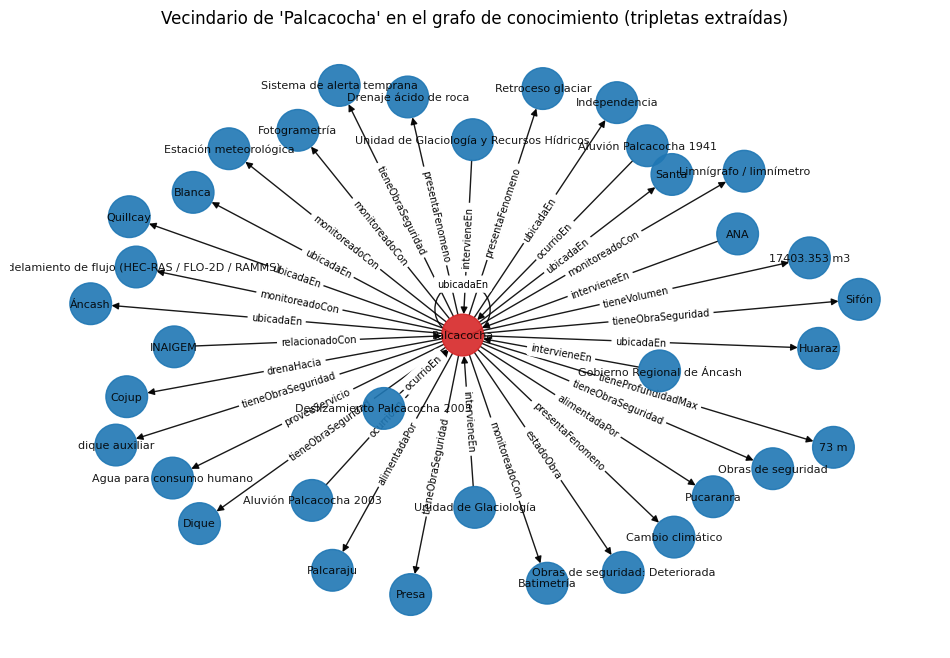

In [24]:
dibujar_vecindario(cons[cons.confianza >= 0.6], CONFIG["ENTIDAD_DEMO"],
                   ruta=os.path.join(CARPETA_TRIP, f"vecindario_{CONFIG['ENTIDAD_DEMO']}.png"))

## Entrega
**GitHub (`data/persona3_v22/`):** este notebook, `entidades.csv`, `tripletas_consolidadas.csv`, `tripletas_contenido.csv`,
`tripletas_todas.csv`, `tripletas_descartadas.csv`, `alias_entidades.csv`, `reporte_pln.md`, `README_tripletas.md`, la carpeta `respuestas/` y la imagen.
Los cachés (`cache_*.jsonl`) y `menciones.csv` pueden quedarse en Drive si pesan mucho.

**Siguiente paso:** ontología OWL (Protégé) con estos tipos y predicados (+ Inventario) y carga de `tripletas_consolidadas.csv` en Neo4j;
las consultas de la sección 13 y 14 se traducen a Cypher.